<a href="https://colab.research.google.com/github/smrkrs/ArabicPython/blob/main/HW7(Matplotlib)ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

rng = np.random.default_rng(42)
dates = pd.date_range("2026-01-01", periods=90)

# Данные для заданий 1 и 2
pd.DataFrame({
    "date": dates,
    "passengers": rng.integers(1000, 3000, 90)
}).to_csv("passengers.csv", index=False)

# Данные для заданий 5, 7, 8 и 9
n = 5000
distance = rng.integers(300, 6000, n)

pd.DataFrame({
    "date": rng.choice(dates, n),
    "destination": rng.choice(
        ["Москва", "Сочи", "Казань", "СПб", "Самара",
         "Екатеринбург", "Уфа", "Омск", "Пермь", "Тюмень"], n
    ),
    "aircraft": rng.choice(
        ["Boeing 737", "Airbus A320", "Boeing 777",
         "Airbus A330", "SSJ-100"], n
    ),
    "distance_km": distance,
    "fuel_t": distance * 0.003 + rng.uniform(1, 3, n),
    "delay_min": rng.integers(0, 120, n)
}).to_csv("flights.csv", index=False)

# Данные для задания 6
airlines = ["Аэрофлот", "S7", "Победа", "Россия", "Уральские авиалинии"]

pd.DataFrame(
    [(date, airline, int(rng.integers(10, 60)))
     for date in dates for airline in airlines],
    columns=["date", "airline", "count"]
).to_csv("flights_by_airline.csv", index=False)

print("Данные готовы!")

Данные готовы!


Задача 1 (первый график, Figure, Axes, savefig). Аэропорт ведёт учёт ежедневного пассажиропотока — данные в passengers.csv со столбцами date и passengers. Загрузите через pd.read_csv("passengers.csv", parse_dates=["date"], index_col="date"), создайте fig, ax = plt.subplots(), постройте ax.plot(df.index, df["passengers"]) и сохраните passengers.png с dpi=150, bbox_inches="tight". Выведите type(fig), type(ax), df.index.dtype. Ожидаемый вывод: Figure, Axes, datetime64[ns]; файл создан. В комментариях объясните: чем fig отличается от ax и почему это разделение принципиально для сложных фигур (один холст — несколько графиков, suptitle, colorbar); что делает plt.subplots() «под капотом», если параметры не указаны (Figure.add_subplot(111)); почему savefig нужно вызывать до plt.show() (фигура может быть очищена и сохранится пустой PNG); зачем нужен bbox_inches="tight" и что произойдёт с длинными подписями без него; что случится, если забыть parse_dates при чтении CSV — как будут выглядеть даты по оси X (числа дней с 1970 года или категории вместо дат); почему x и y должны быть одинаковой длины и какую ошибку выбросит Matplotlib при несовпадении (ValueError: x and y must have same first dimension).

Figure
Axes
datetime64[ns]


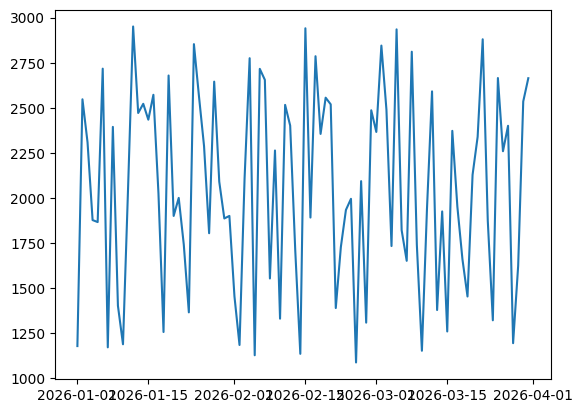

In [ ]:
df = pd.read_csv("passengers.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots()
ax.plot(df.index, df["passengers"])

fig.savefig("passengers.png", dpi=150, bbox_inches="tight")

print(type(fig).__name__)
print(type(ax).__name__)
print(df.index.dtype)

plt.show()

Задача 2 (параметры figure, PlotConfig). Аэропорт готовит серию отчётов для авиавластей, и нужно, чтобы все графики имели одинаковый стиль. Определите @dataclass class PlotConfig с полями figsize: tuple = (10, 6), dpi: int = 100, facecolor: str = "white", layout: str = "constrained" и реализуйте фабрику make_figure(cfg) -> tuple[Figure, Axes]. Постройте график пассажиропотока с конфигурацией PlotConfig(figsize=(12, 8), dpi=200, facecolor="#f5f5f5") и выведите итоговый размер в пикселях. Ожидаемый вывод: 2400 × 1600 пикселей. В комментариях объясните: как figsize и dpi связаны с размером в пикселях и почему figsize в дюймах, а не в пикселях; что даёт layout="constrained" и почему он рекомендуется вместо tight_layout; чем facecolor фигуры отличается от ax.set_facecolor; зачем нужны разные dpi для веба (100–150) и для печати (300+); как расширить датакласс методом with_dpi(new_dpi) через dataclasses.replace и почему это функциональный подход поверх ООП; что произойдёт, если задать facecolor фигуры и осей разными — где это может быть полезно в презентации аэропорта (белый фон осей на фирменном синем).

2400 × 1600 пикселей


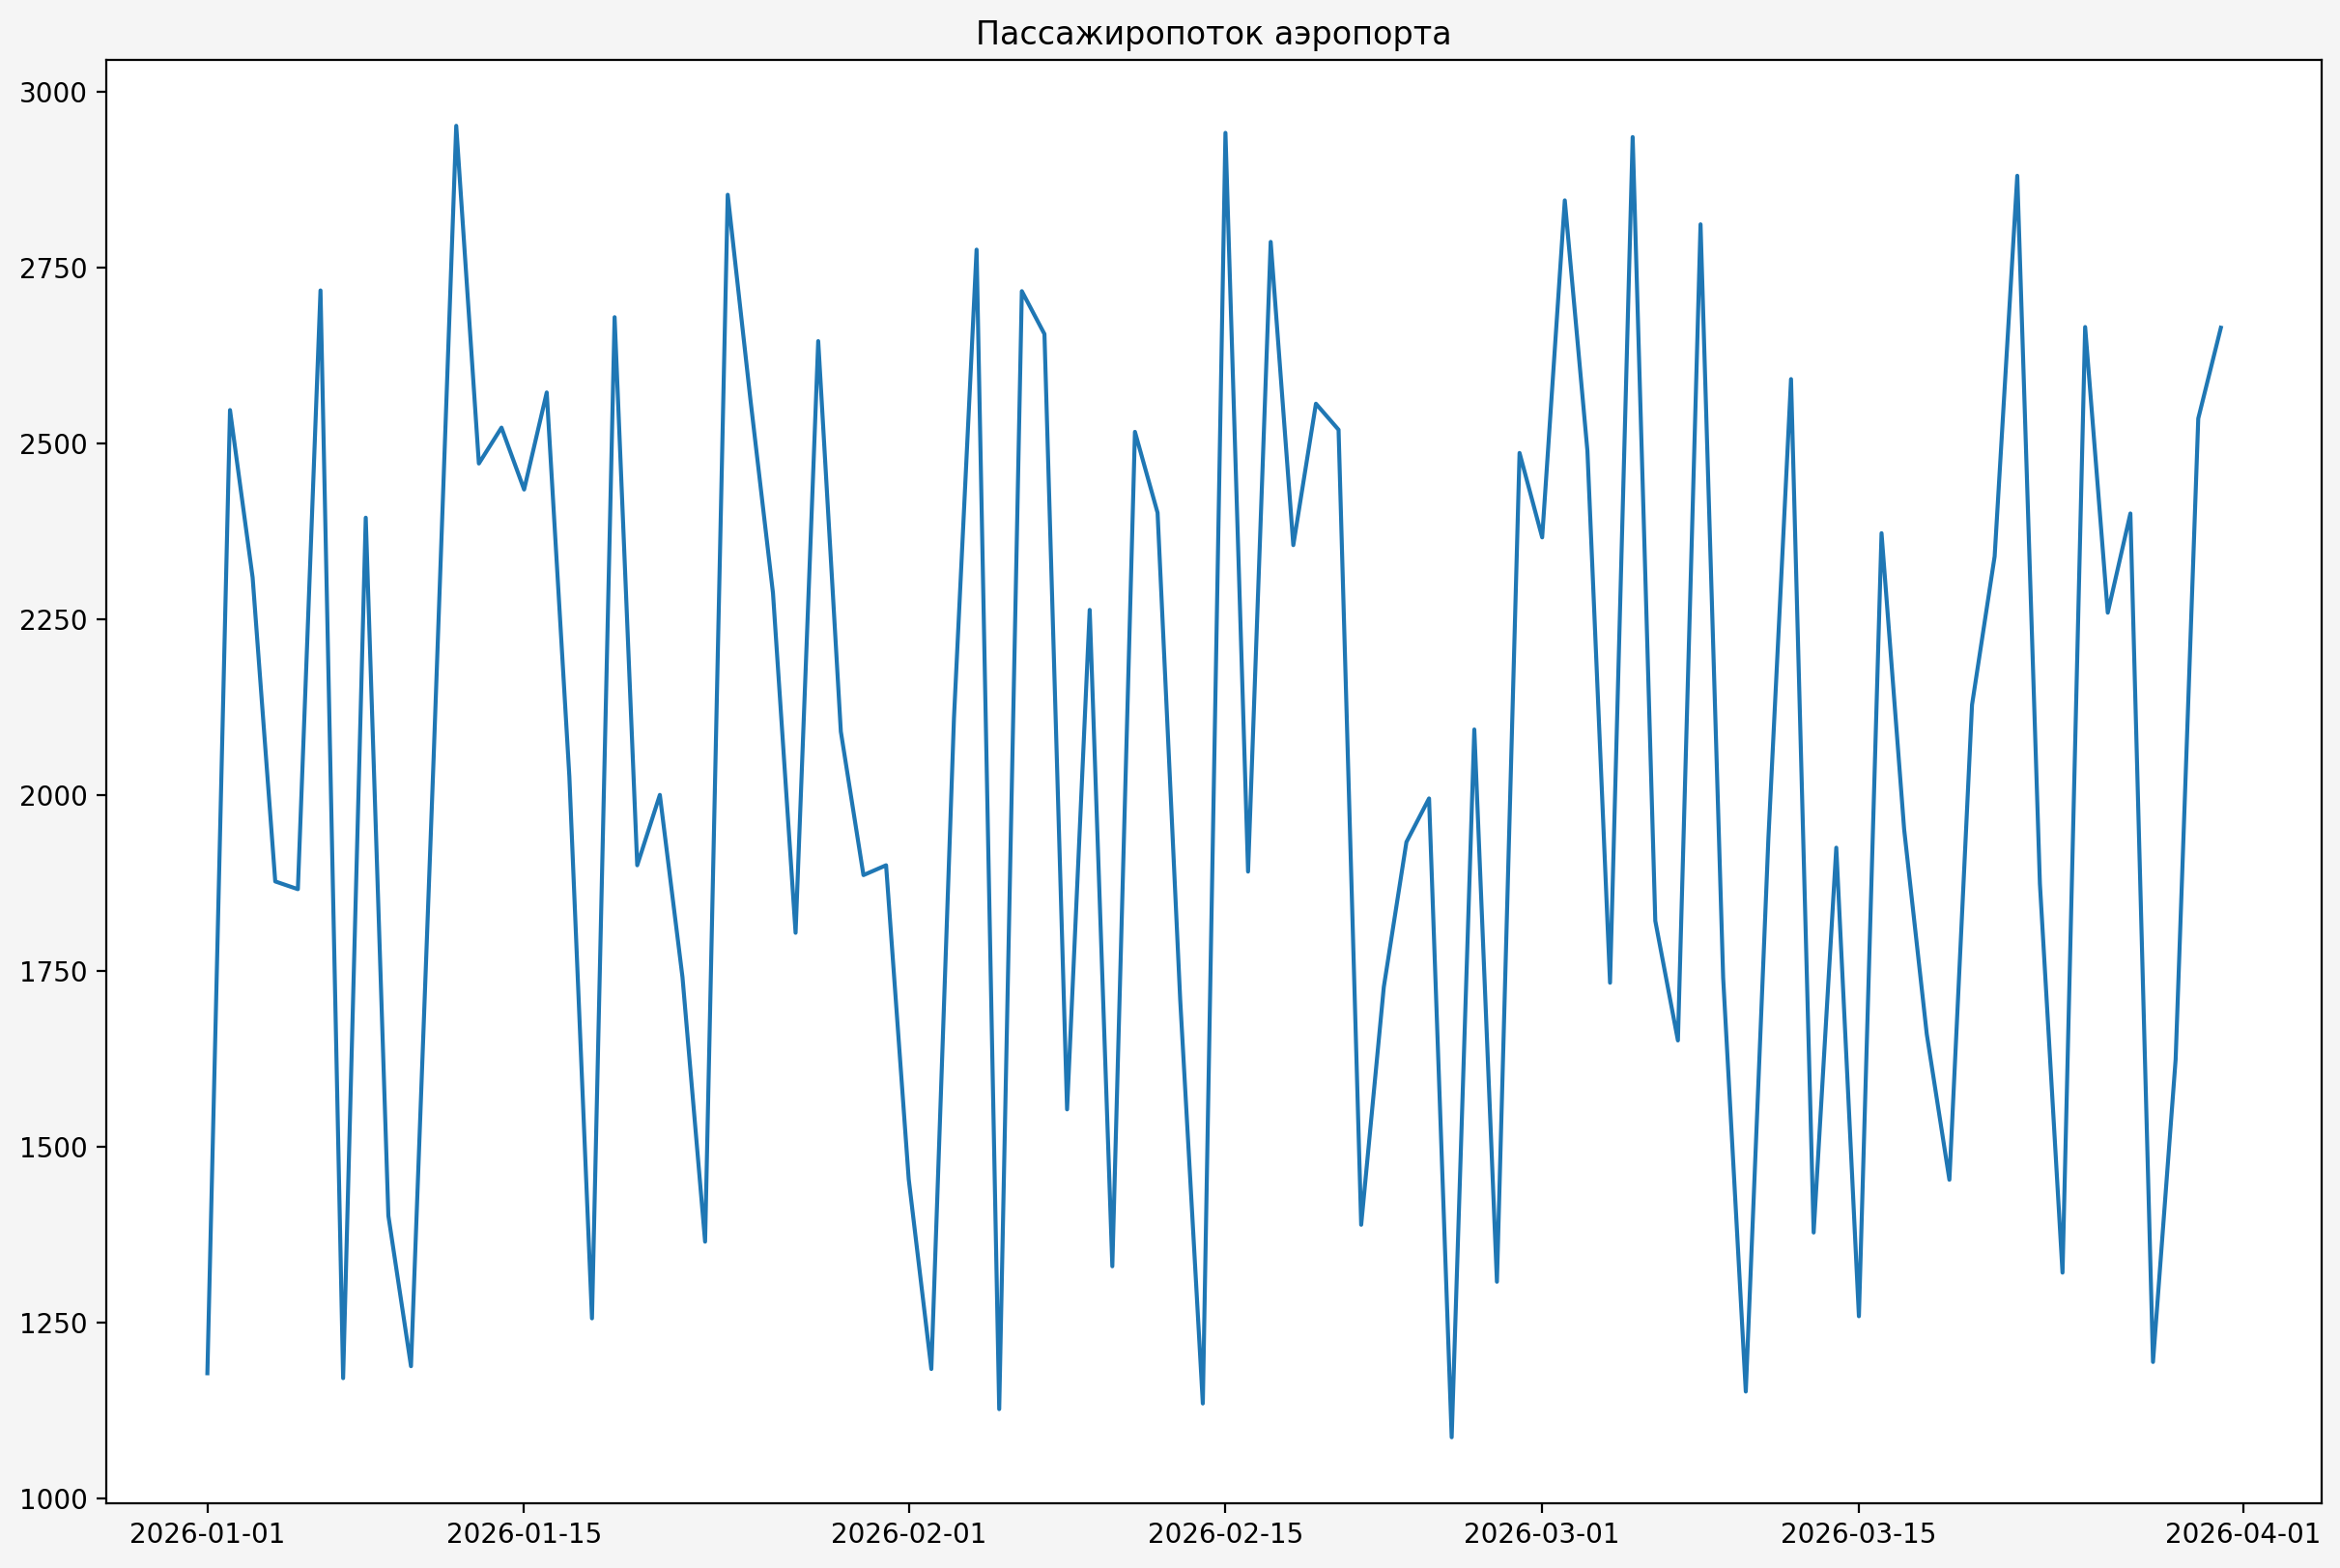

In [ ]:
from dataclasses import dataclass, replace
from matplotlib.figure import Figure
from matplotlib.axes import Axes

@dataclass
class PlotConfig:
    figsize: tuple = (10, 6)
    dpi: int = 100
    facecolor: str = "white"
    layout: str = "constrained"

    def with_dpi(self, new_dpi):
        return replace(self, dpi=new_dpi)

def make_figure(cfg: PlotConfig) -> tuple[Figure, Axes]:
    return plt.subplots(
        figsize=cfg.figsize,
        dpi=cfg.dpi,
        facecolor=cfg.facecolor,
        layout=cfg.layout
    )

df = pd.read_csv("passengers.csv", parse_dates=["date"], index_col="date")

cfg = PlotConfig(figsize=(12, 8), dpi=200, facecolor="#f5f5f5")
fig, ax = make_figure(cfg)

ax.plot(df.index, df["passengers"])
ax.set_title("Пассажиропоток аэропорта")

width, height = fig.get_size_inches() * fig.dpi
print(f"{int(width)} × {int(height)} пикселей")

plt.show()

# figsize задаёт размер в дюймах, а dpi — число точек на дюйм.
# Размер в пикселях = figsize * dpi. Дюймы сохраняют физический размер.
# constrained автоматически подбирает отступы, часто удобнее tight_layout.
# facecolor задаёт фон фигуры, ax.set_facecolor() — фон области графика.
# Для веба используют 100–150 dpi, для печати — 300 и выше.
# replace создаёт новую конфигурацию, не изменяя старую.
# Разные цвета фона фигуры и осей полезны для фирменных презентаций.

Задача 3 (метки, заголовок, DelayFormatter). Аэропорт анализирует среднюю задержку рейсов по месяцам, и на оси Y нужен формат 12.5 мин с точностью до десятых. Реализуйте class DelayFormatter(mticker.Formatter) с методом __call__(self, x, pos=None), возвращающим f"{x:.1f} мин", и примените через ax.yaxis.set_major_formatter(DelayFormatter()). Установите xlabel("Месяц"), ylabel("Средняя задержка"), title("Средняя задержка рейсов по месяцам"), для заголовка — fontweight="bold", fontfamily="serif", для оси X — labelpad=15. В комментариях объясните: как Formatter встраивается в ООП-иерархию Matplotlib и почему наследование от mticker.Formatter даёт больше возможностей, чем функция в FuncFormatter; в каких случаях Formatter-класс хранит состояние (единица измерения, точность, суффикс); почему fontfamily="serif" может дать разный шрифт на разных ОС и как это влияет на воспроизводимость отчёта; что делает labelpad и когда его нужно увеличивать; как loc="left" в set_title смещает заголовок к левому краю; зачем использовать fontdict вместо именованных аргументов, если одинаковые настройки применяются к нескольким текстовым элементам.

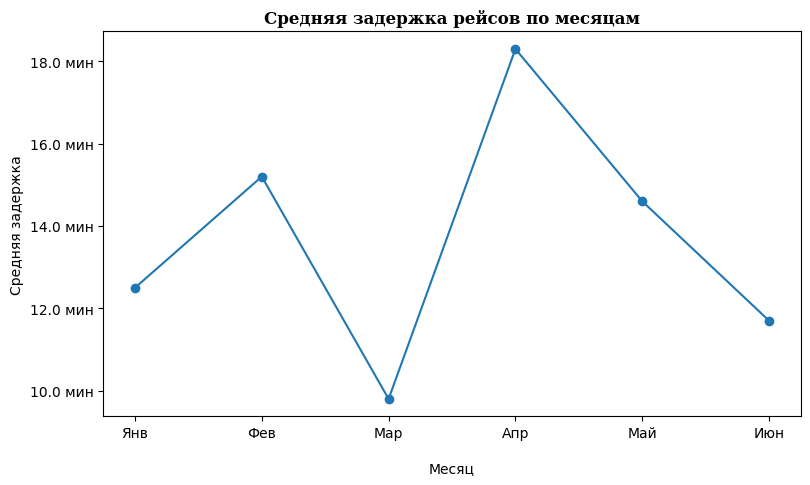

In [ ]:
import matplotlib.ticker as mticker

class DelayFormatter(mticker.Formatter):
    def __call__(self, x, pos=None):
        return f"{x:.1f} мин"

months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн"]
delays = [12.5, 15.2, 9.8, 18.3, 14.6, 11.7]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(months, delays, marker="o")

ax.yaxis.set_major_formatter(DelayFormatter())

ax.set_xlabel("Месяц", labelpad=15)
ax.set_ylabel("Средняя задержка")
ax.set_title(
    "Средняя задержка рейсов по месяцам",
    fontweight="bold",
    fontfamily="serif"
)

plt.show()

# Formatter — базовый класс Matplotlib для форматирования подписей.
# Наследование позволяет добавлять настройки и хранить состояние.
# Например, Formatter может хранить единицы измерения и точность.
# FuncFormatter проще, когда достаточно одной функции.
# serif выбирает шрифт с засечками; на разных ОС он может отличаться.
# labelpad увеличивает расстояние от подписи до оси.
# loc="left" в set_title() выравнивает заголовок слева.
# fontdict удобен для одинакового оформления нескольких подписей.

Задача 4 (стили линий, LineStyle). Аэропорт строит график сравнения трёх авиакомпаний (Аэрофлот, S7, Победа) на одной оси — число рейсов по месяцам. Чтобы не дублировать десятки аргументов в каждом plot, создайте @dataclass class LineStyle с полями color: str = "steelblue", linewidth: float = 2, marker: str = "o", markersize: int = 8, alpha: float = 1 и методом as_kwargs() -> dict. Постройте 5 подграфиков с разными LineStyle, на двух из них покажите эквивалентность строки "ob-" и именованных аргументов color="b", marker="o", linestyle="-". Ожидаемый вывод: 5 линий с разными маркерами и цветами. В комментариях объясните: как читается строка формата "[marker][line][color]" и почему её иногда удобнее именованных аргументов; чем markerfacecolor отличается от markeredgecolor и когда их стоит различать; как alpha < 1 улучшает читаемость при наложении нескольких линий; почему linewidth измеряется в точках, а не в пикселях, и как это связано с dpi; что произойдёт при alpha=0 и как это можно использовать для «скрытых» линий; как задать цвет HEX-кодом или RGB-кортежем для соответствия брендбуку аэропорта.

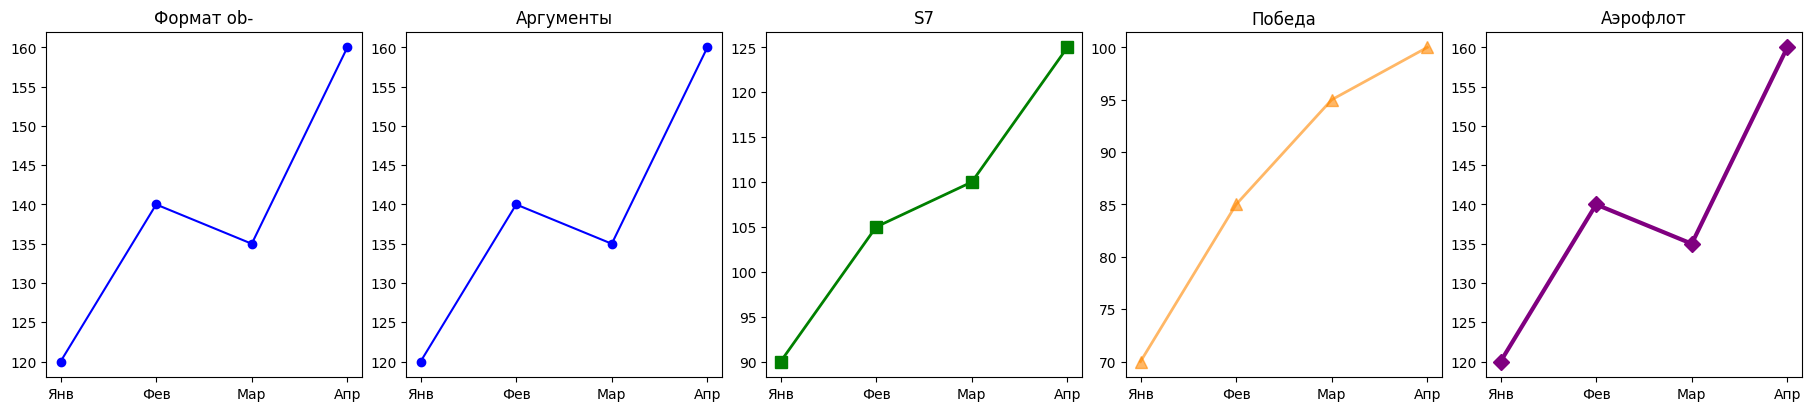

In [ ]:
from dataclasses import dataclass

@dataclass
class LineStyle:
    color: str = "steelblue"
    linewidth: float = 2
    marker: str = "o"
    markersize: int = 8
    alpha: float = 1

    def as_kwargs(self) -> dict:
        return vars(self).copy()

months = ["Янв", "Фев", "Мар", "Апр"]
aeroflot = [120, 140, 135, 160]
s7 = [90, 105, 110, 125]
pobeda = [70, 85, 95, 100]

fig, axes = plt.subplots(1, 5, figsize=(18, 4), layout="constrained")

# Первый способ
axes[0].plot(months, aeroflot, "ob-")
axes[0].set_title("Формат ob-")

# Второй способ — эквивалент первого
axes[1].plot(months, aeroflot, color="b", marker="o", linestyle="-")
axes[1].set_title("Аргументы")

# Разные LineStyle
axes[2].plot(months, s7,
             **LineStyle(color="green", marker="s").as_kwargs())
axes[2].set_title("S7")

axes[3].plot(months, pobeda,
             **LineStyle(color="#FF8800", marker="^", alpha=0.6).as_kwargs())
axes[3].set_title("Победа")

axes[4].plot(months, aeroflot,
             **LineStyle(color="purple", marker="D", linewidth=3).as_kwargs())
axes[4].set_title("Аэрофлот")

plt.show()

# "ob-" означает круглый маркер, синий цвет и сплошную линию.
# Короткая запись удобна, но именованные аргументы понятнее.
# markerfacecolor задаёт заливку, markeredgecolor — контур маркера.
# Разные цвета заливки и контура помогают выделить точки.
# alpha < 1 делает линию полупрозрачной, что помогает при наложении.
# alpha=0 делает линию полностью невидимой.
# linewidth измеряется в пунктах, а не пикселях, и зависит от dpi.
# Цвет можно задать HEX-кодом или RGB-кортежем, например (1, 0, 0).

Задача 5 (деления, сетка, MultipleLocator). Диспетчерская служба строит график вылетов по дням и хочет видеть деления раз в неделю по оси X и круглые числа (кратные 50) по оси Y. Загрузите flights.csv с датами и постройте линию. Примените ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)), ax.yaxis.set_major_locator(mticker.MultipleLocator(50)), ax.yaxis.set_minor_locator(mticker.AutoMinorLocator()), включите двухуровневую сетку через ax.grid(which="major", linestyle="--", alpha=0.5) и ax.grid(which="minor", linestyle=":", alpha=0.3). Ожидаемый вывод: деления по понедельникам и по 50 вылетов; два уровня сетки. В комментариях объясните: чем Locator отличается от Formatter и почему это разделение ответственности важно; что делает AutoMinorLocator; почему MultipleLocator(50) удобнее для счётчиков, чем автоматические деления; как set_xlim(5, -5) инвертирует ось и зачем это может понадобиться; как tick_params(which="minor", length=0) скрывает сами штрихи, оставляя только сетку; что произойдёт при set_xlim с диапазоном вне данных — обрежется ли линия или покажется пустая область.

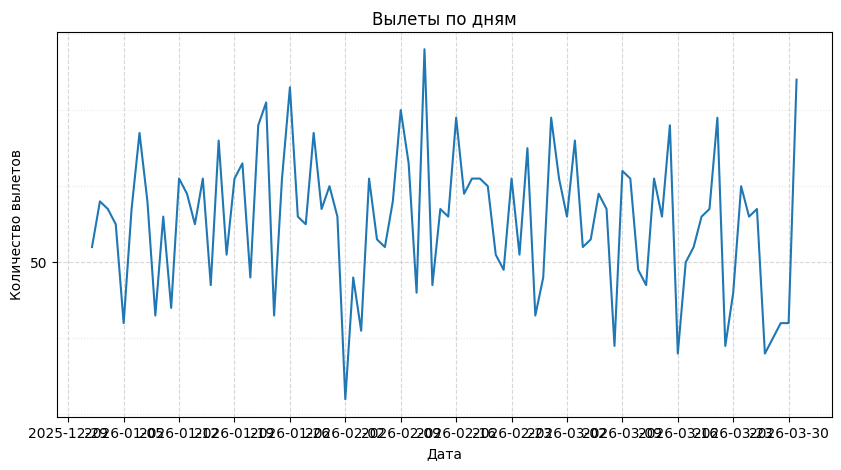

In [ ]:
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

df = pd.read_csv("flights.csv", parse_dates=["date"])
daily = df.groupby("date").size().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(daily.index, daily.values)

ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.yaxis.set_major_locator(mticker.MultipleLocator(50))
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())

ax.grid(which="major", linestyle="--", alpha=0.5)
ax.grid(which="minor", linestyle=":", alpha=0.3)

ax.tick_params(which="minor", length=0)

ax.set_xlabel("Дата")
ax.set_ylabel("Количество вылетов")
ax.set_title("Вылеты по дням")

plt.show()

# Locator определяет положение делений, Formatter — их подписи.
# AutoMinorLocator автоматически добавляет промежуточные деления.
# MultipleLocator(50) удобен для счётчиков с фиксированным шагом.
# set_xlim(5, -5) переворачивает числовую ось X.
# Инверсия полезна, когда нужен обратный порядок значений.
# tick_params(which="minor", length=0) скрывает штрихи, но не сетку.
# set_xlim за пределами данных добавляет пустую область.
# Если диапазон слишком узкий, часть линии будет обрезана.

Задача 6 (легенда из groupby). Аэропорт сравнивает число рейсов по авиакомпаниям (Аэрофлот, S7, Победа, Уральские авиалинии, Россия) за квартал. Загрузите flights_by_airline.csv с колонками date, airline, count, постройте линии циклом for al, g in df.groupby("airline"): ax.plot(g["date"], g["count"], label=al). Вызовите ax.legend(loc="upper left", ncol=2, title="Авиакомпании", framealpha=0.9). Дополнительно вынесите легенду за график через bbox_to_anchor=(1.02, 0.5). Ожидаемый вывод: легенда с N записями в 2 колонки; при выносе — за пределами области осей. В комментариях объясните: как groupby в Pandas даёт готовые группы для цикла и почему это стандартный паттерн; зачем параметр ncol=2 и когда он критичен (много авиакомпаний — 6–8); как bbox_to_anchor задаёт точку привязки в долях осей и почему loc и bbox_to_anchor работают вместе; что делает borderaxespad=0 и когда его нужно указывать; почему без label=al легенда будет пустой; что произойдёт, если одна из линий не имеет label — попадёт ли она в легенду или будет проигнорирована (Matplotlib выдаст предупреждение No artists with labels found).

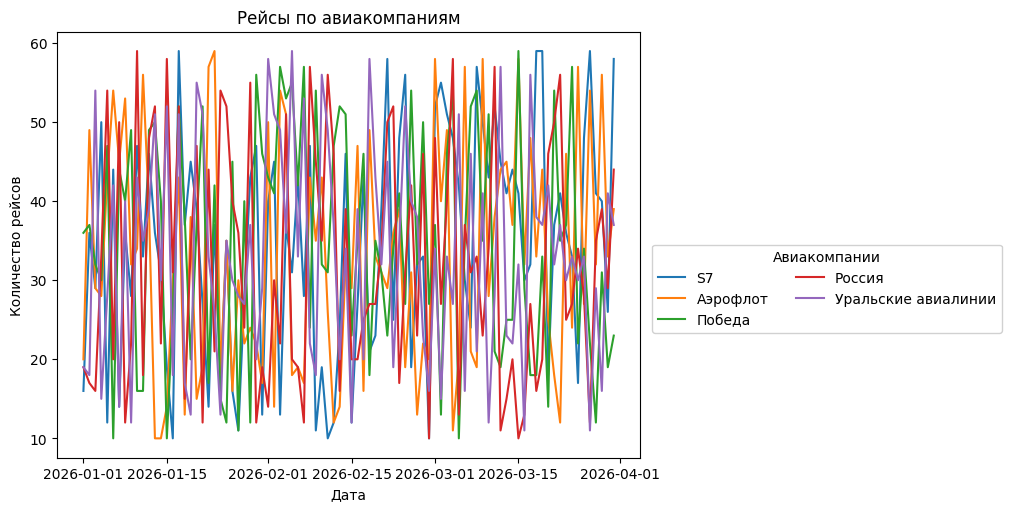

In [ ]:
df = pd.read_csv("flights_by_airline.csv", parse_dates=["date"])
df = df.sort_values("date")

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

for al, g in df.groupby("airline"):
    ax.plot(g["date"], g["count"], label=al)

ax.legend(
    loc="upper left",
    ncol=2,
    title="Авиакомпании",
    framealpha=0.9,
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)

ax.set_xlabel("Дата")
ax.set_ylabel("Количество рейсов")
ax.set_title("Рейсы по авиакомпаниям")

plt.show()

# groupby разделяет данные на группы, которые удобно обходить циклом.
# label=al добавляет название авиакомпании в легенду.
# ncol=2 распределяет легенду по двум колонкам, удобно при 6–8 линиях.
# loc определяет точку легенды, bbox_to_anchor — место привязки.
# bbox_to_anchor использует относительные координаты области осей.
# borderaxespad=0 убирает дополнительный отступ.
# Линия без label игнорируется автоматической легендой.
# Если нет ни одной подписанной линии, появится предупреждение
# No artists with labels found.

Задача 7 (bar и barh из value_counts). Аэропорт анализирует топ-10 самых популярных направлений за год. Загрузите flights.csv, получите top = df["destination"].value_counts().head(10), постройте вертикальную диаграмму ax.bar(top.index, top.values) и горизонтальную ax.barh(top.index[::-1], top.values[::-1]). Подпишите значения над столбцами через for i, v in enumerate(top.values): ax.text(i, v + 5, str(v), ha="center") (для bar) и ax.text(v + 5, i, str(v), va="center") (для barh). Ожидаемый вывод: две диаграммы — вертикальная и горизонтальная с перевёрнутыми данными. В комментариях объясните: почему для barh данные переворачивают через [::-1] и что произойдёт без разворота (самое популярное направление окажется внизу); почему ось значений bar-графика должна начинаться с нуля и что произойдёт при ax.set_ylim(50, 200) (визуальный обман); когда barh удобнее bar (длинные названия направлений типа «Санкт-Петербург (Пулково)»); как value_counts() уже сортирует данные по убыванию и зачем .head(10); что произойдёт при value_counts(normalize=True) и как это использовать для доли направления в общем трафике; как подписать значения внутри столбцов, а не снаружи (для очень длинных столбцов — иначе текст вылезет за границы).

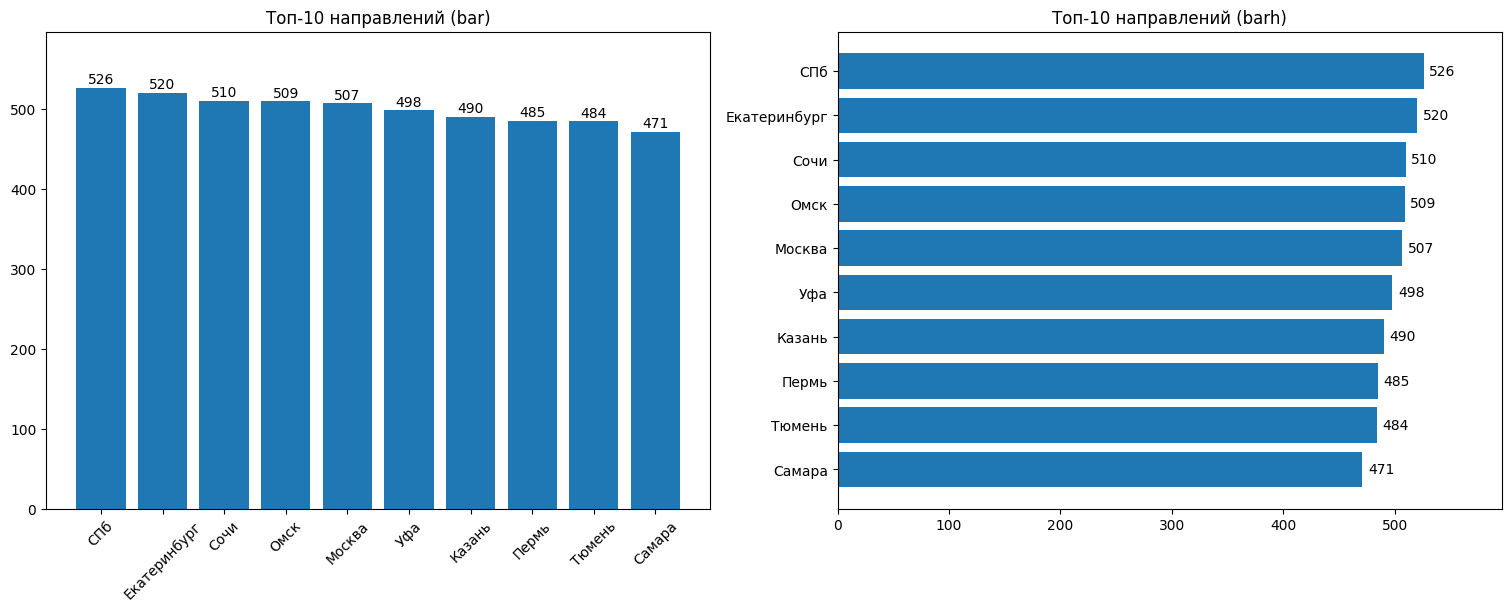

In [ ]:
df = pd.read_csv("flights.csv")
top = df["destination"].value_counts().head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

# Вертикальная диаграмма
ax1.bar(top.index, top.values)
ax1.set_title("Топ-10 направлений (bar)")
ax1.tick_params(axis="x", rotation=45)
ax1.set_ylim(0, top.max() + 70)

for i, v in enumerate(top.values):
    ax1.text(i, v + 5, str(v), ha="center")

# Горизонтальная диаграмма
ax2.barh(top.index[::-1], top.values[::-1])
ax2.set_title("Топ-10 направлений (barh)")
ax2.set_xlim(0, top.max() + 70)

for i, v in enumerate(top.values[::-1]):
    ax2.text(v + 5, i, str(v), va="center")

plt.show()

# value_counts() считает категории и сортирует их по убыванию.
# head(10) выбирает десять самых популярных направлений.
# [::-1] меняет порядок, чтобы лидер в barh оказался сверху.
# Без разворота самое популярное направление будет внизу.
# Ось значений должна начинаться с нуля.
# set_ylim(50, 200) может визуально преувеличить различия.
# barh удобнее для длинных названий направлений.
# value_counts(normalize=True) возвращает доли вместо количества.
# Подписи можно разместить внутри столбцов, например при x=v-5.

Задача 8 (scatter с ручным hue). Аэропорт изучает связь дальности рейса и расхода топлива, с разбивкой по типу воздушного судна (Boeing 737, Airbus A320, Boeing 777, Airbus A330, SSJ-100). В Matplotlib нет встроенного hue, но его легко эмулировать циклом for ac, g in df.groupby("aircraft"): ax.scatter(g["distance_km"], g["fuel_t"], label=ac, s=50, alpha=0.7, edgecolors="black"). Ожидаемый вывод: пять облаков точек разного цвета с общей легендой. В комментариях объясните: чем scatter отличается от plot при маркерах и почему для диаграммы рассеяния предпочтителен первый; что означает параметр s (площадь в точках², а не диаметр) и как увеличить диаметр в 2 раза (площадь в 4 раза); зачем alpha=0.6 при большом количестве точек; почему edgecolors="black" улучшает читаемость на светлом фоне и когда лучше использовать белый; как groupby в Pandas даёт готовые срезы для каждой группы; что произойдёт при пропусках в distance_km или fuel_t — нужно ли dropna() перед scatter и почему (ValueError: x and y must be the same size).

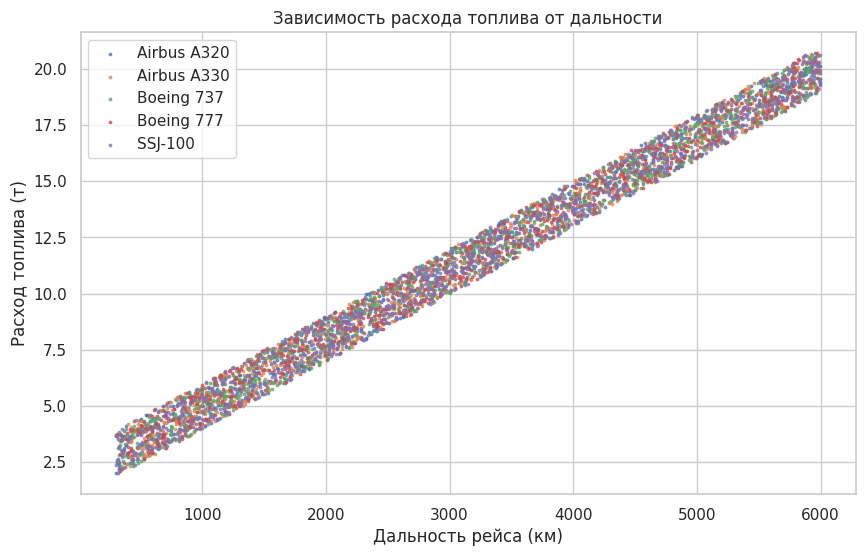

In [ ]:
df = pd.read_csv("flights.csv")
df = df.dropna(subset=["aircraft", "distance_km", "fuel_t"])

fig, ax = plt.subplots(figsize=(10, 6))

for ac, g in df.groupby("aircraft"):
    ax.scatter(
        g["distance_km"],
        g["fuel_t"],
        label=ac,
        s=3,
        alpha=0.7
    )

ax.set_xlabel("Дальность рейса (км)")
ax.set_ylabel("Расход топлива (т)")
ax.set_title("Зависимость расхода топлива от дальности")
ax.legend()

plt.show()

# scatter показывает отдельные точки, а plot обычно соединяет их линиями.
# s — площадь маркера в пунктах², а не его диаметр.
# Для увеличения диаметра в 2 раза площадь увеличивают в 4 раза.
# alpha=0.7 делает точки прозрачными и показывает их наложения.
# Чёрный контур выделяет точки на светлом фоне, белый — на тёмном.
# groupby разделяет данные по типам самолётов.
# dropna() удаляет строки с пропусками в нужных столбцах.
# Matplotlib обычно пропускает NaN, но dropna гарантирует чистые пары.
# При разной длине x и y возникнет ValueError.

Задача 9 (гистограмма с правилом Фридмана-Диакониса). Аэропорт анализирует распределение задержек вылетов в минутах. Реализуйте функцию fd_bins(x: pd.Series) -> int, вычисляющую число корзин по правилу Фридмана-Диакониса: q25, q75 = np.percentile(x.dropna(), [25, 75]), iqr = q75 - q25, width = 2 * iqr / len(x) ** (1/3), int((x.max() - x.min()) / width). Постройте четыре гистограммы delay_min: с bins=fd_bins(...), bins=10, bins=30, bins="auto". Ожидаемый вывод: FD-вариант обычно даёт 20–30 корзин и балансирует детализацию и гладкость. В комментариях объясните: почему FD-правило устойчиво к выбросам (использует IQR, а не стандартное отклонение); почему мало корзин «сглаживает» пики, а много создаёт «пилу» случайных флуктуаций; зачем density=True при сравнении выборок разного размера (например, «внутренние» vs «международные» рейсы — разное число вылетов); чем hist отличается от bar (непрерывные vs категориальные данные) и почему для авиакомпаний нужен bar; что произойдёт при bins=1000 на 500 рейсах (почти все корзины пусты — гистограмма нечитаема); как наложить KDE-кривую через scipy.stats.gaussian_kde, чтобы сгладить гистограмму для презентации.

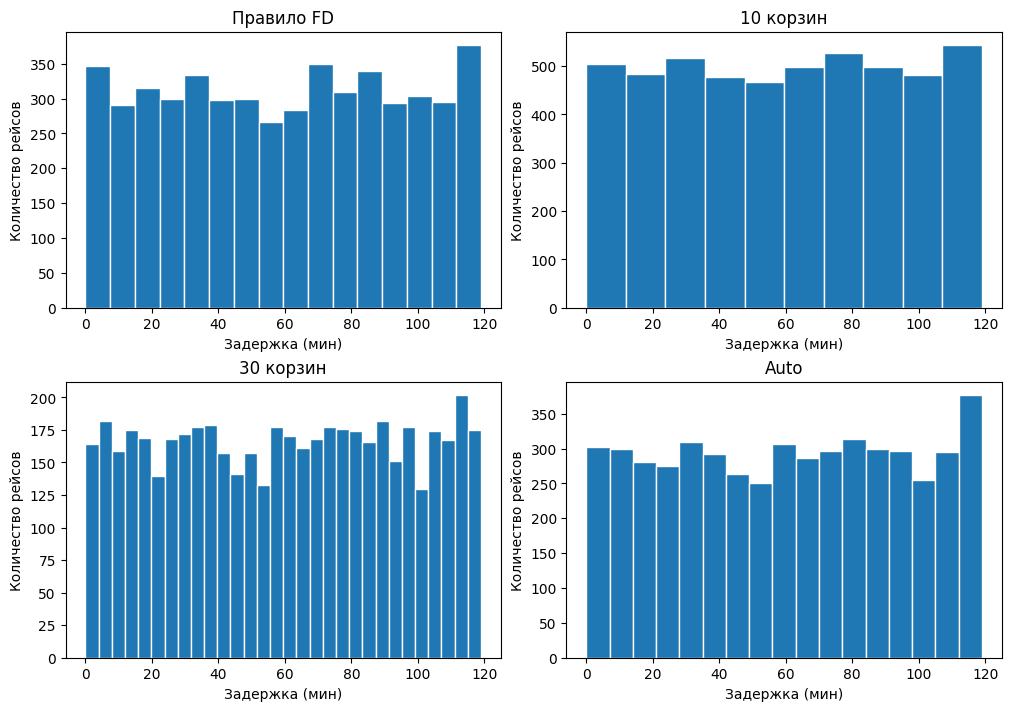

In [ ]:
df = pd.read_csv("flights.csv")
delays = df["delay_min"].dropna()

def fd_bins(x: pd.Series) -> int:
    x = x.dropna()

    q25, q75 = np.percentile(x, [25, 75])
    iqr = q75 - q25

    width = 2 * iqr / len(x) ** (1/3)

    if width == 0:
        return 1

    return max(1, int((x.max() - x.min()) / width))

fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")

bins_list = [fd_bins(delays), 10, 30, "auto"]
titles = ["Правило FD", "10 корзин", "30 корзин", "Auto"]

for ax, bins, title in zip(axes.flat, bins_list, titles):
    ax.hist(delays, bins=bins, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Задержка (мин)")
    ax.set_ylabel("Количество рейсов")

plt.show()

# IQR = 75-й процентиль минус 25-й процентиль.
# Правило FD использует IQR, поэтому устойчиво к выбросам.
# Мало корзин скрывает детали, много создаёт случайные колебания.
# density=True позволяет сравнивать выборки разного размера.
# hist показывает распределение чисел, bar сравнивает категории.
# При bins=1000 на 500 рейсах почти все корзины будут пустыми.
# Для сглаживания можно использовать scipy.stats.gaussian_kde:
# kde = gaussian_kde(delays)
# xs = np.linspace(delays.min(), delays.max(), 200)
# ax.plot(xs, kde(xs))
# Для наложения KDE гистограмму нужно построить с density=True.

Задача 10 (круговая диаграмма и donut). Аэропорт визуализирует структуру рейсов по типам (внутренние, международные, чартерные, грузовые, бизнес-авиация, транзитные). Постройте ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2}). Второй вариант — donut через wedgeprops={"width": 0.4} и текст в центре через ax.text(0, 0, f"Всего: {counts.sum():,}", ha="center", va="center"). Ожидаемый вывод: круговая диаграмма с процентами; donut с общим числом в центре. В комментариях объясните: как autopct форматирует проценты и зачем %%; как startangle=90 поворачивает диаграмму и почему это влияет на восприятие (первый сектор начинается сверху — как на часах); зачем explode и когда его использовать (выделить нишевый, но важный сегмент — бизнес-авиацию); почему pie плохо работает при >7 категориях и близких значениях; как wedgeprops={"width": 0.4} превращает круговую в donut; что произойдёт при отрицательных значениях (ошибка ValueError: Wedge sizes must be non-negative) и как обрабатывать «отменённые рейсы» (переводить в положительные перед pie).

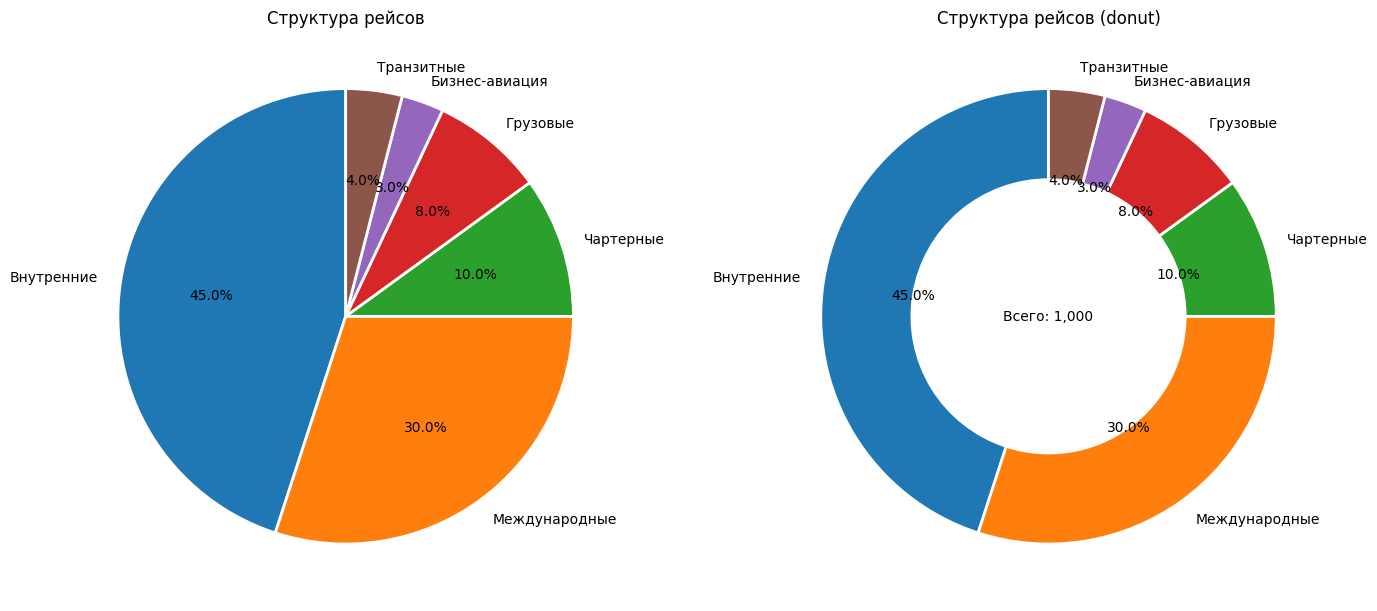

In [ ]:
counts = pd.Series({
    "Внутренние": 450,
    "Международные": 300,
    "Чартерные": 100,
    "Грузовые": 80,
    "Бизнес-авиация": 30,
    "Транзитные": 40
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")

# Круговая диаграмма
ax1.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

ax1.set_title("Структура рейсов")

# Кольцевая диаграмма
ax2.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2}
)

ax2.text(0, 0, f"Всего: {counts.sum():,}", ha="center", va="center")
ax2.set_title("Структура рейсов (donut)")

plt.show()

# autopct="%1.1f%%" показывает проценты с одним знаком после точки.
# %% добавляет символ процента.
# startangle=90 поворачивает первый сектор к верхней части круга.
# explode позволяет выделить важный сектор, например бизнес-авиацию.
# При количестве категорий больше 7 pie становится трудно читать.
# width=0.4 делает отверстие в центре и создаёт donut.
# Отрицательные значения вызывают ValueError.
# Отменённые рейсы нужно учитывать положительным количеством
# в отдельной категории, а не передавать отрицательные числа.

Задача 11 (экспорт в несколько форматов и BytesIO). Аэропорт готовит отчёт для авиавластей: графики нужны в PNG (для сайта), PDF (для печати), SVG (для редактирования), JPEG (для email-рассылки) и прозрачный PNG (для слайда с фирменным фоном). Постройте график и сохраните в 5 форматов: report.png с dpi=300, report.pdf, report.svg, report.jpg с dpi=100, report_transparent.png с transparent=True. Для каждого файла вычислите SHA-256 через hashlib.sha256(open(name, "rb").read()).hexdigest()[:8] и размер через os.path.getsize. Дополнительно сохраните в BytesIO (для последующей отправки через FastAPI) и верните длину. Ожидаемый вывод: размеры и хэши 5 файлов; PNG-прозрачный — с альфа-каналом. В комментариях объясните: зачем нужны хэши файлов (детерминизм, кэширование CI, проверка изменений при ревью); почему savefig нужно вызывать до plt.close(fig), а не после; как BytesIO используется в FastAPI (Response(content=buf.getvalue(), media_type="image/png")) и зачем buf.seek(0) перед чтением; почему JPEG плох для графиков (артефакты сжатия на резких границах текста); как metadata={"Title": "Отчёт аэропорта", "Author": "..."} встраивает информацию в PDF; что произойдёт при сохранении в несуществующую папку (FileNotFoundError) и как Path("outputs").mkdir(parents=True, exist_ok=True) решает проблему.

report.png Размер: 297388 байт SHA-256: 9f7cfb3f
report.pdf Размер: 13662 байт SHA-256: 159e5514
report.svg Размер: 31471 байт SHA-256: fb5b712c
report.jpg Размер: 48326 байт SHA-256: 89a43cad
report_transparent.png Размер: 49847 байт SHA-256: 5d4f2dac
Размер BytesIO: 76233 байт


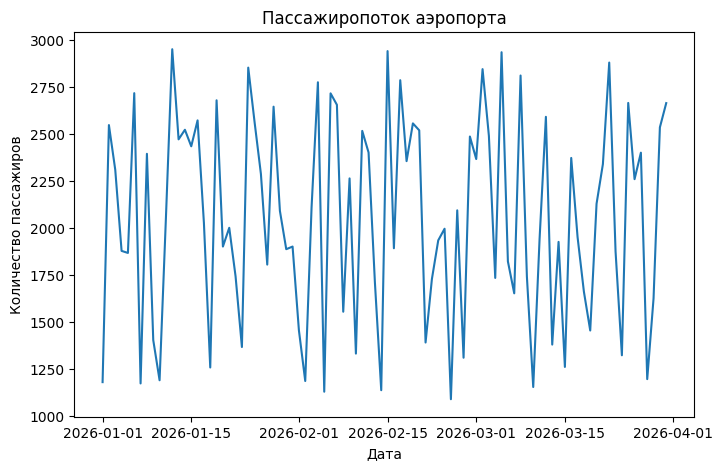

In [ ]:
import hashlib
import os
from io import BytesIO
from pathlib import Path

df = pd.read_csv("passengers.csv", parse_dates=["date"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["date"], df["passengers"])

ax.set_title("Пассажиропоток аэропорта")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество пассажиров")

files = {
    "report.png": {"dpi": 300},
    "report.pdf": {
        "metadata": {"Title": "Отчёт аэропорта", "Author": "Аэропорт"}
    },
    "report.svg": {},
    "report.jpg": {"dpi": 100},
    "report_transparent.png": {"transparent": True}
}

for name, settings in files.items():
    fig.savefig(name, **settings)

    with open(name, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()[:8]

    file_size = os.path.getsize(name)

    print(name, "Размер:", file_size, "байт", "SHA-256:", file_hash)

buf = BytesIO()
fig.savefig(buf, format="png")
buf.seek(0)

print("Размер BytesIO:", len(buf.read()), "байт")

plt.show()
plt.close(fig)

# SHA-256 помогает находить изменения файлов и проверять кэш в CI.
# Для одинаковых хэшей содержимое файлов должно совпадать.
# savefig вызывают до plt.close(fig), чтобы сохранить готовую фигуру.
# BytesIO хранит изображение в оперативной памяти без отдельного файла.
# seek(0) возвращает указатель в начало буфера перед read().
# В FastAPI используют Response(content=buf.getvalue(), media_type="image/png").
# JPEG может искажать текст и линии из-за сжатия.
# metadata записывает название и автора в свойства PDF.
# Несуществующая папка вызовет FileNotFoundError.
# Path("outputs").mkdir(parents=True, exist_ok=True) создаёт папку.

Задача 12 (стили, rcParams, контекстный менеджер). Аэропорт хочет, чтобы все внутренние графики имели единый стиль, но при этом титульные графики для авиавластей выглядели иначе. Реализуйте @contextlib.contextmanager def style_ctx(name): with plt.style.context(name): yield. Примените with style_ctx("ggplot"): к одному графику, затем with style_ctx("seaborn-v0_8-darkgrid"): к другому. Дополнительно покажите plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3}) и mpl.rcdefaults() для полного сброса. Ожидаемый вывод: графики в разных стилях; после rcdefaults — заводской вид. В комментариях объясните: чем plt.style.use отличается от plt.style.context (глобально vs временно — второе критично в Jupyter); зачем rcParams для тонкой настройки; как комбинировать стили (use(["seaborn-v0_8", "dark_background"])) — какой перекрывает какой; почему plt.style.use("default") не сбрасывает вручную заданные rcParams и что использовать (mpl.rcdefaults()); где хранятся собственные .mplstyle файлы (~/.config/matplotlib/stylelib/) и как загрузить стиль по имени; что вернёт plt.style.available и как быстро посмотреть доступные стили для вдохновения.

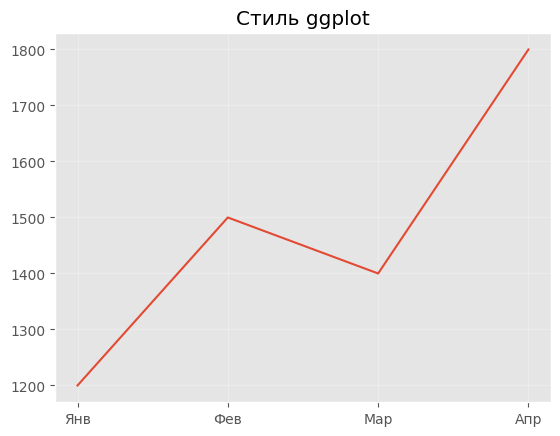

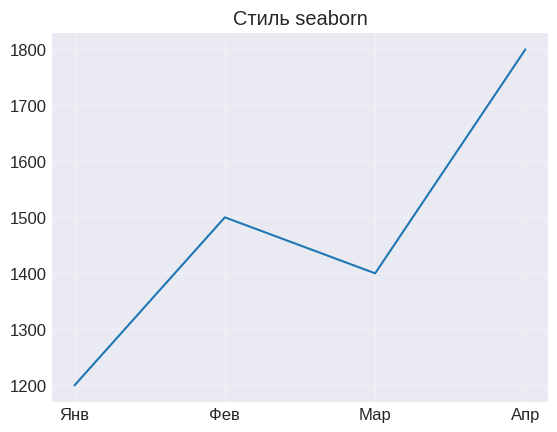

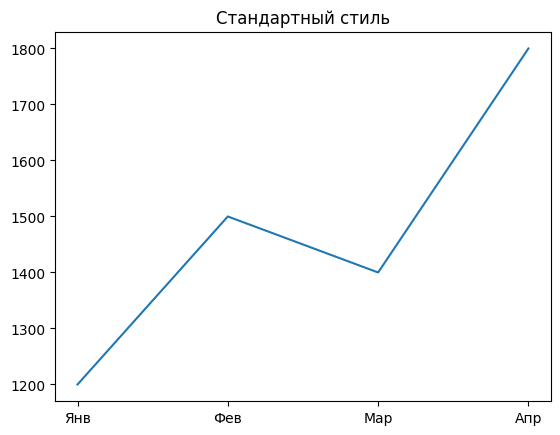

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [ ]:
import matplotlib as mpl
import contextlib

@contextlib.contextmanager
def style_ctx(name):
    with plt.style.context(name):
        yield

months = ["Янв", "Фев", "Мар", "Апр"]
passengers = [1200, 1500, 1400, 1800]

plt.rcParams.update({
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.3
})

# Стиль ggplot
with style_ctx("ggplot"):
    fig, ax = plt.subplots()
    ax.plot(months, passengers)
    ax.set_title("Стиль ggplot")
    plt.show()

# Стиль seaborn
with style_ctx("seaborn-v0_8-darkgrid"):
    fig, ax = plt.subplots()
    ax.plot(months, passengers)
    ax.set_title("Стиль seaborn")
    plt.show()

# Сброс настроек
mpl.rcdefaults()

fig, ax = plt.subplots()
ax.plot(months, passengers)
ax.set_title("Стандартный стиль")
plt.show()

print(plt.style.available)

# style.use() меняет стиль глобально для следующих графиков.
# style.context() временно применяет стиль внутри блока with.
# В Colab и Jupyter context удобен, так как настройки не сохраняются.
# rcParams задаёт отдельные параметры, например шрифт и сетку.
# Стили можно объединять:
# plt.style.use(["seaborn-v0_8", "dark_background"])
# При совпадении параметров последний стиль имеет приоритет.
# style.use("default") не гарантирует сброс всех ручных изменений.
# Для сброса rcParams используется mpl.rcdefaults().
# Свои .mplstyle можно хранить в ~/.config/matplotlib/stylelib/
# и загружать по имени через plt.style.use("my_style").
# plt.style.available возвращает список доступных стилей.
# print(plt.style.available) позволяет быстро посмотреть этот список.

In [ ]:
# Подготовка данных для заданий 13–22

rng = np.random.default_rng(42)
dates = pd.date_range("2026-10-01", periods=30)

# Пассажиропоток по дням
passengers = rng.integers(900, 2000, 30)
passengers[6] = 3000
passengers[19] = 400

pd.DataFrame({
    "date": dates,
    "passengers": passengers
}).to_csv("daily_passengers.csv", index=False)

# Пассажиропоток по 8 терминалам
terminals = [f"Терминал {letter}" for letter in "ABCDEFGH"]

pd.DataFrame(
    [(date, term, int(rng.integers(200, 900)))
     for term in terminals for date in dates],
    columns=["date", "terminal", "passengers"]
).to_csv("passengers_by_terminal.csv", index=False)

# Задержки по авиакомпаниям
airline_counts = {
    "Аэрофлот": 300,
    "S7": 200,
    "Победа": 50,
    "Уральские авиалинии": 150
}

airline_delays = pd.DataFrame(
    [(airline, max(0, round(float(v), 1)))
     for airline, n in airline_counts.items()
     for v in rng.normal(30, 18, n)],
    columns=["airline", "delay_min"]
)

airline_delays.to_csv("airline_delays.csv", index=False)

print("Данные для заданий 13–22 готовы!")

Данные для заданий 13–22 готовы!


Задача 13 (аннотации с argmax/argmin). Аэропорт анализирует дневной пассажиропоток за месяц и хочет выделить дни-пики и дни-провалы (например, начало отпусков и «мёртвый» ноябрь). Загрузите daily_passengers.csv с parse_dates=["date"], index_col="date", найдите idx_max = df["passengers"].idxmax() и idx_min = df["passengers"].idxmin(). Добавьте аннотации через ax.annotate(f"Пик: {df.loc[idx_max, 'passengers']:,}", xy=(idx_max, df.loc[idx_max, "passengers"]), xytext=(10, 20), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="green", connectionstyle="arc3,rad=0.2")); аналогично для минимума с xytext=(-80, -30), color="red". Ожидаемый вывод: стрелки указывают на пики, текст смещён и не перекрывает линию. В комментариях объясните: чем textcoords="offset points" отличается от "data" и почему первый удобнее для смещения текста; почему idxmax() в Pandas возвращает метку индекса, а не позицию, и как это используется в xy; зачем arc3,rad=0.2 (изогнутая стрелка) и как rad=-0.2 развернёт изгиб; как bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", edgecolor="orange") в annotate улучшает читаемость поверх линий; что произойдёт без ha/va (текст «прилипнет» к точке и перекроет маркер); как аннотировать несколько близких точек, чтобы они не перекрывались.

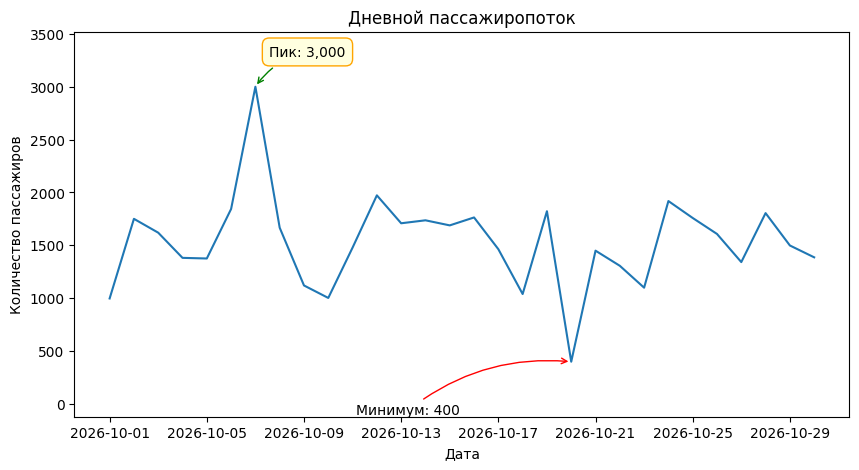

In [ ]:
df = pd.read_csv(
    "daily_passengers.csv",
    parse_dates=["date"],
    index_col="date"
)

idx_max = df["passengers"].idxmax()
idx_min = df["passengers"].idxmin()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df.index, df["passengers"])

ax.annotate(
    f"Пик: {df.loc[idx_max, 'passengers']:,}",
    xy=(idx_max, df.loc[idx_max, "passengers"]),
    xytext=(10, 20),
    textcoords="offset points",
    ha="left",
    va="bottom",
    arrowprops=dict(
        arrowstyle="->",
        color="green",
        connectionstyle="arc3,rad=0.2"
    ),
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="lightyellow",
        edgecolor="orange"
    )
)

ax.annotate(
    f"Минимум: {df.loc[idx_min, 'passengers']:,}",
    xy=(idx_min, df.loc[idx_min, "passengers"]),
    xytext=(-80, -30),
    textcoords="offset points",
    ha="right",
    va="top",
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        connectionstyle="arc3,rad=-0.2"
    )
)

ax.margins(y=0.2)
ax.set_title("Дневной пассажиропоток")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество пассажиров")

plt.show()

# idxmax() и idxmin() возвращают метки индекса, а не номера строк.
# Поэтому полученные даты можно сразу использовать в xy.
# textcoords="offset points" смещает текст относительно точки в пунктах.
# textcoords="data" использовал бы координаты самих данных.
# arc3,rad=0.2 изгибает стрелку, rad=-0.2 меняет направление изгиба.
# bbox создаёт фон вокруг текста и повышает читаемость.
# ha и va управляют выравниванием текста относительно его позиции.
# Без них подпись может оказаться слишком близко к маркеру.
# Для близких точек задают разные xytext, чтобы подписи не пересекались.

Задача 14 (продвинутая легенда из groupby). Аэропорт имеет 8 терминалов и хочет показать на графике только 2 ключевых (например, «Терминал B» и «Терминал D»), но остальные оставить построенными — чтобы видеть общий фон. Загрузите passengers_by_terminal.csv, постройте линии циклом for term, g in df.groupby("terminal"): line, = ax.plot(...); lines[term] = line. Создайте две легенды: выборочную через ax.legend(handles=[lines["Терминал B"], lines["Терминал D"]], loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0) — вынесенную за график, и полную через ncol=2 внутри. Ожидаемый вывод: две легенды — выборочная вне графика и полная внутри. В комментариях объясните: зачем запятая в line, = ax.plot(...) (распаковка кортежа из одного элемента); что произойдёт без запятой и почему handles=[line] не сработает (AttributeError: 'tuple' object has no attribute 'set_label'); как bbox_to_anchor в долях осей задаёт точку привязки и почему loc="center left" + bbox_to_anchor=(1.02, 0.5) помещает легенду справа; что делает borderaxespad=0; почему при многих категориях полная легенда перегружает график и лучше использовать выборочную; как автоматически отсортировать категории через sorted(lines.items()), чтобы в легенде был алфавитный порядок.

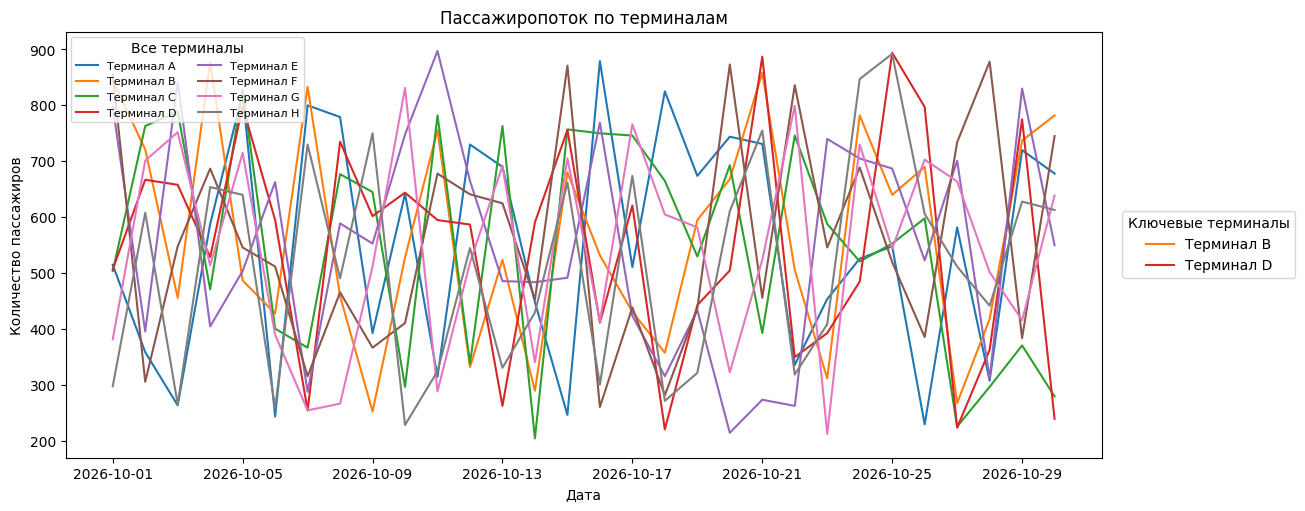

In [ ]:
df = pd.read_csv("passengers_by_terminal.csv", parse_dates=["date"])

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
lines = {}

for term, g in df.groupby("terminal"):
    line, = ax.plot(g["date"], g["passengers"], label=term)
    lines[term] = line

# Выборочная легенда справа
selected_legend = ax.legend(
    handles=[lines["Терминал B"], lines["Терминал D"]],
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0,
    title="Ключевые терминалы"
)

ax.add_artist(selected_legend)

# Полная легенда внутри графика
ax.legend(
    handles=[line for _, line in sorted(lines.items())],
    loc="upper left",
    ncol=2,
    title="Все терминалы",
    fontsize=8
)

ax.set_title("Пассажиропоток по терминалам")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество пассажиров")

plt.show()

# groupby разделяет данные по терминалам.
# ax.plot возвращает список линий, а line, извлекает одну линию из списка.
# Без запятой line будет списком, а не объектом Line2D.
# В handles нужно передавать сами линии, иначе легенда не сформируется.
# bbox_to_anchor задаёт позицию относительно области осей.
# loc="center left" привязывает левый центр легенды к указанной точке.
# borderaxespad=0 убирает дополнительный отступ от области осей.
# Полная легенда может перегружать график при множестве категорий.
# sorted(lines.items()) сортирует терминалы по названию.
# add_artist сохраняет первую легенду при создании второй.

Задача 15 (группированные столбцы из pivot_table). Аэропорт сравнивает число рейсов по авиакомпаниям за 2023 и 2024 год. Постройте pivot = flights.pivot_table(index="airline", columns="year", values="count", aggfunc="sum"), получите x = np.arange(len(pivot.index)) и width = 0.8 / len(pivot.columns). Через цикл for i, year in enumerate(pivot.columns): offset = (i - len(pivot.columns) / 2 + 0.5) * width; ax.bar(x + offset, pivot[year], width, label=str(year)) постройте сгруппированные столбцы. Установите ax.set_xticks(x) и ax.set_xticklabels(pivot.index). Ожидаемый вывод: парные столбцы (2023 и 2024) для каждой авиакомпании. В комментариях объясните: почему width = 0.8 / n_years, а не фиксированный 0.35 (иначе столбцы перекроются при 3+ группах); как формула (i - n/2 + 0.5) * width обобщается на любое число групп; как pivot_table сразу готовит данные — что было бы, если бы данных не было в правильной форме; зачем set_xticks и set_xticklabels по отдельности; что произойдёт при width=0.8 с двумя группами (полностью перекроются); как добавить третью группу (например, прогноз на 2025) и почему это работает без изменений в коде.

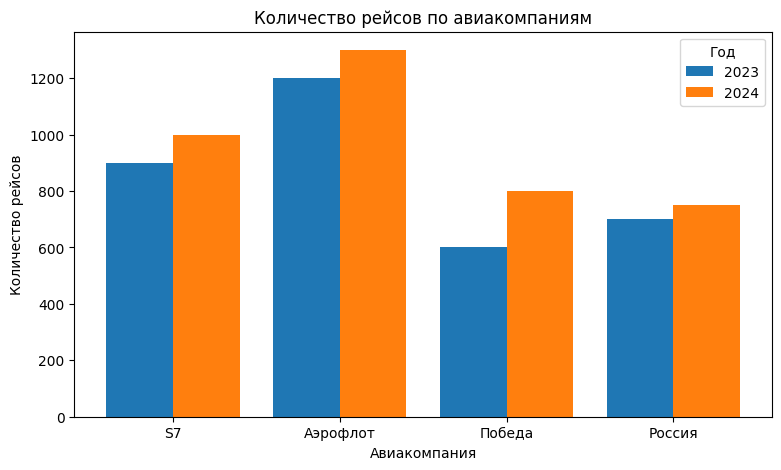

In [ ]:
flights = pd.DataFrame({
    "airline": ["Аэрофлот", "S7", "Победа", "Россия"] * 2,
    "year": [2023] * 4 + [2024] * 4,
    "count": [1200, 900, 600, 700, 1300, 1000, 800, 750]
})

pivot = flights.pivot_table(
    index="airline",
    columns="year",
    values="count",
    aggfunc="sum"
)

x = np.arange(len(pivot.index))
width = 0.8 / len(pivot.columns)

fig, ax = plt.subplots(figsize=(9, 5))

for i, year in enumerate(pivot.columns):
    offset = (i - len(pivot.columns) / 2 + 0.5) * width
    ax.bar(x + offset, pivot[year], width, label=str(year))

ax.set_xticks(x)
ax.set_xticklabels(pivot.index)

ax.set_title("Количество рейсов по авиакомпаниям")
ax.set_xlabel("Авиакомпания")
ax.set_ylabel("Количество рейсов")
ax.legend(title="Год")

plt.show()

# pivot_table преобразует строки в таблицу: авиакомпании × годы.
# Без такой подготовки пришлось бы вручную собирать значения для групп.
# width=0.8 / n_years делит место между всеми годами.
# Фиксированная ширина 0.35 может вызвать наложение при 3+ годах.
# Формула offset симметрично размещает любое число групп вокруг x.
# set_xticks задаёт позиции делений, set_xticklabels — их названия.
# При width=0.8 для двух лет столбцы перекроются.
# Если добавить данные за 2025 год, цикл автоматически построит
# третью группу столбцов без изменения кода.

Задача 16 (stacked bar + errorbar). Аэропорт показывает структуру пассажиропотока по типам рейсов (внутренние, международные, чартерные) для каждого терминала. Постройте pivot = flights.pivot_table(index="terminal", columns="flight_type", values="passengers", aggfunc="sum"), реализуйте накопление через bottom = np.zeros(len(pivot)); for ft in pivot.columns: ax.bar(pivot.index, pivot[ft], bottom=bottom, label=ft); bottom += pivot[ft].values. Добавьте планки ошибок к сумме через ax.errorbar(pivot.index, bottom, yerr=stds.values, fmt="none", capsize=8, ecolor="black"). Ожидаемый вывод: накопленные столбцы с планками ошибок наверху каждого. В комментариях объясните: как bottom=bottom реализует накопление и почему bottom += pivot[ft].values (а не bottom = pivot[ft]) — что будет, если забыть +=; почему yerr нужен для суммы, а не для отдельного типа (планка «утонет» внутри столбца и будет вводить в заблуждение); зачем fmt="none" (только планки, без маркеров); как error_kw={"elinewidth": 2, "ecolor": "black"} объединяет стиль; что произойдёт при неправильном порядке категорий в bottom и yerr (планки окажутся не на тех столбцах); как вычислить стандартное отклонение по терминалам (flights.groupby("terminal")["passengers"].std()).

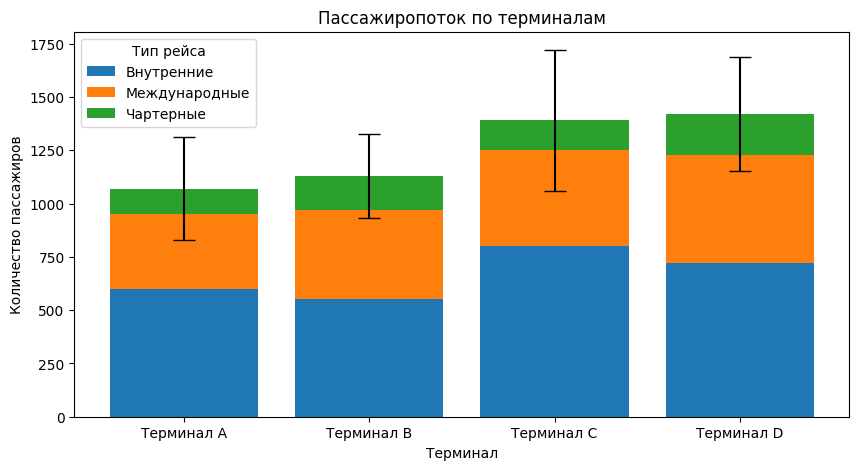

In [ ]:
flights = pd.DataFrame({
    "terminal": ["Терминал A"] * 3 + ["Терминал B"] * 3 +
                ["Терминал C"] * 3 + ["Терминал D"] * 3,
    "flight_type": ["Внутренние", "Международные", "Чартерные"] * 4,
    "passengers": [600, 350, 120, 550, 420, 160,
                   800, 450, 140, 720, 510, 190]
})

pivot = flights.pivot_table(
    index="terminal",
    columns="flight_type",
    values="passengers",
    aggfunc="sum"
)

stds = flights.groupby("terminal")["passengers"].std()
stds = stds.reindex(pivot.index)

fig, ax = plt.subplots(figsize=(10, 5))

bottom = np.zeros(len(pivot))

for ft in pivot.columns:
    ax.bar(pivot.index, pivot[ft], bottom=bottom, label=ft)
    bottom += pivot[ft].values

ax.errorbar(
    pivot.index,
    bottom,
    yerr=stds.values,
    fmt="none",
    capsize=8,
    ecolor="black"
)

ax.set_title("Пассажиропоток по терминалам")
ax.set_xlabel("Терминал")
ax.set_ylabel("Количество пассажиров")
ax.legend(title="Тип рейса")

plt.show()

# bottom задаёт высоту, с которой начинается следующий столбец.
# bottom += добавляет новое значение к уже накопленной сумме.
# Без += столбцы не будут правильно накапливаться.
# yerr задаёт величину отклонения относительно общей высоты столбца.
# Если поставить планки на отдельную часть, они окажутся внутри столбца.
# fmt="none" показывает только планки ошибок, без маркеров.
# error_kw={"elinewidth": 2, "ecolor": "black"} задаёт их оформление.
# Порядок значений stds должен соответствовать порядку терминалов.
# Иначе планки ошибок окажутся на неправильных столбцах.
# groupby("terminal")["passengers"].std() вычисляет стандартное отклонение.

Задача 17 (scatter + polyfit + выбросы по z-score). Аэропорт исследует связь загрузки рейса и задержки вылета — но в данных есть «аварийные» дни с аномально большими задержками при низкой загрузке (погода, технические причины). Постройте облако точек через ax.scatter(df["load_factor"], df["delay_min"], alpha=0.6), вычислите m, b = np.polyfit(df["load_factor"], df["delay_min"], 1) и нарисуйте тренд ax.plot(x_line, m * x_line + b, "r--"). Выбросы определите по z = np.abs((df["delay_min"] - df["delay_min"].mean()) / df["delay_min"].std()); mask = z > 3 и выделите отдельным ax.scatter(df.loc[mask, "load_factor"], df.loc[mask, "delay_min"], c="red", marker="X", s=200, edgecolors="black", label="Выбросы", zorder=5). Добавьте в заголовок r = np.corrcoef(df["load_factor"], df["delay_min"])[0, 1]. В комментариях объясните: что означает m в polyfit (наклон — сколько минут задержки добавляется на каждый процент загрузки); почему polyfit чувствителен к выбросам и как RANSACRegressor из sklearn.linear_model решает проблему; как zorder держит выбросы поверх точек; что произойдёт при нелинейной зависимости — линейный тренд введёт в заблуждение и нужен polyfit(deg=2); как np.corrcoef[0, 1] извлекает коэффициент корреляции Пирсона из матрицы; почему коэффициент Пирсона чувствителен к выбросам, а Спирмен (scipy.stats.spearmanr) — нет.

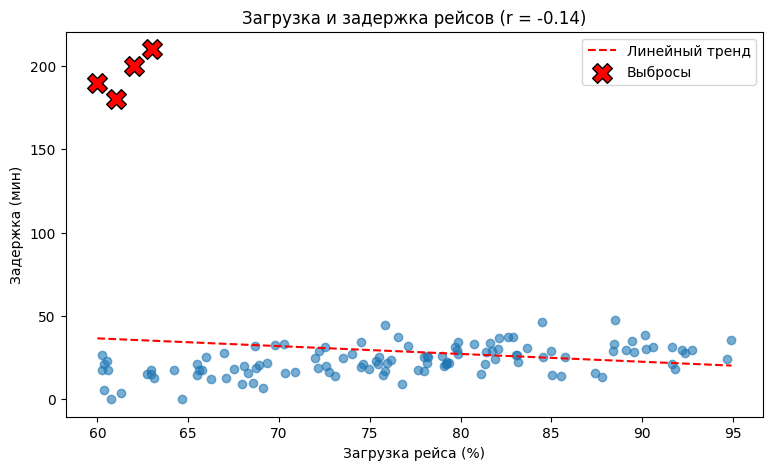

In [ ]:

rng = np.random.default_rng(17)

loads = rng.uniform(60, 95, 120)
delays = 20 + 0.6 * (loads - 70) + rng.normal(0, 8, 120)

# Несколько аномально больших задержек
loads[:4] = [60, 62, 61, 63]
delays[:4] = [190, 200, 180, 210]

df = pd.DataFrame({
    "load_factor": loads,
    "delay_min": delays
})

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(df["load_factor"], df["delay_min"], alpha=0.6)

m, b = np.polyfit(df["load_factor"], df["delay_min"], 1)

x_line = np.linspace(df["load_factor"].min(),
                     df["load_factor"].max(), 100)

ax.plot(x_line, m * x_line + b, "r--", label="Линейный тренд")

z = np.abs(
    (df["delay_min"] - df["delay_min"].mean()) /
    df["delay_min"].std()
)

mask = z > 3

ax.scatter(
    df.loc[mask, "load_factor"],
    df.loc[mask, "delay_min"],
    c="red",
    marker="X",
    s=200,
    edgecolors="black",
    label="Выбросы",
    zorder=5
)

r = np.corrcoef(df["load_factor"], df["delay_min"])[0, 1]

ax.set_title(f"Загрузка и задержка рейсов (r = {r:.2f})")
ax.set_xlabel("Загрузка рейса (%)")
ax.set_ylabel("Задержка (мин)")
ax.legend()

plt.show()

# polyfit(..., 1) подбирает линейный тренд y = m*x + b.
# m — изменение задержки в минутах при росте загрузки на 1 п.п.
# polyfit чувствителен к выбросам, которые могут исказить наклон.
# RANSACRegressor из sklearn уменьшает влияние аномальных точек.
# z-score показывает отклонение от среднего в стандартных отклонениях.
# zorder=5 размещает выбросы поверх остальных точек.
# При нелинейной зависимости можно использовать polyfit(..., 2).
# corrcoef возвращает матрицу корреляций, [0, 1] — коэффициент Пирсона.
# Корреляция Пирсона чувствительна к выбросам.
# Корреляция Спирмена (scipy.stats.spearmanr) менее чувствительна,
# поскольку использует ранги значений.

Задача 18 (density, cumulative, step). Аэропорт сравнивает распределения задержек по трём авиакомпаниям (Аэрофлот, S7, Победа). Если построить обычные гистограммы, Победа (мало рейсов в выборке) будет визуально «раздавлена» Аэрофлотом (много рейсов). Постройте 4 подграфика: (а) наложение с alpha=0.5; (б) density=True (нормировка площади к 1); (в) cumulative=True (накопленная частота); (г) histtype="step" (только контуры). Для каждого for al, g in df.groupby("airline"): ax.hist(g["delay_min"], ...). В комментариях объясните: зачем density=True при разном n; как cumulative=True находит медиану (точка, где накопленная частота = 0.5) и как её отметить через ax.axvline(median_value); почему histtype="step" лучше при 3+ сериях; как зафиксировать bins при сравнении (bins=np.linspace(min, max, 21)) — что будет при автоматическом подборе корзин для каждой группы отдельно; как наложить KDE через scipy.stats.gaussian_kde; что произойдёт при cumulative=-1 (обратная накопленная — от 1 к 0, полезно для «доли рейсов с задержкой меньше X»).

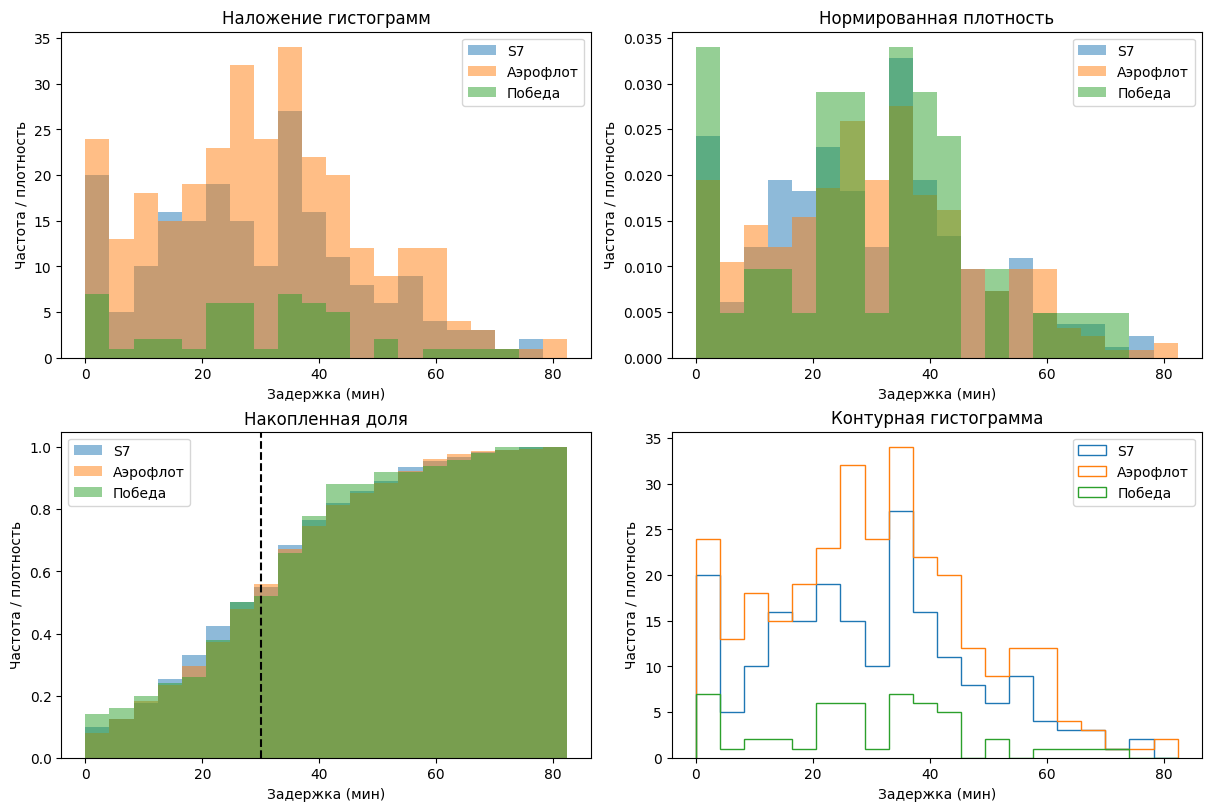

In [ ]:
df = pd.read_csv("airline_delays.csv")

df = df[df["airline"].isin(["Аэрофлот", "S7", "Победа"])]

bins = np.linspace(df["delay_min"].min(), df["delay_min"].max(), 21)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")

settings = [
    {"alpha": 0.5},
    {"density": True, "alpha": 0.5},
    {"cumulative": True, "density": True, "alpha": 0.5},
    {"histtype": "step"}
]

titles = [
    "Наложение гистограмм",
    "Нормированная плотность",
    "Накопленная доля",
    "Контурная гистограмма"
]

for ax, params, title in zip(axes.flat, settings, titles):
    for al, g in df.groupby("airline"):
        ax.hist(g["delay_min"], bins=bins, label=al, **params)

    ax.set_title(title)
    ax.set_xlabel("Задержка (мин)")
    ax.set_ylabel("Частота / плотность")
    ax.legend()

median_value = df.loc[
    df["airline"] == "Аэрофлот", "delay_min"
].median()

axes[1, 0].axvline(median_value, color="black", linestyle="--")

plt.show()

# alpha=0.5 позволяет видеть перекрывающиеся гистограммы.
# density=True нормирует площадь каждой гистограммы к 1.
# Это позволяет сравнивать выборки разного размера.
# cumulative=True накапливает частоты слева направо.
# Вместе с density=True уровень 0.5 соответствует медиане.
# axvline(median_value) отмечает медиану вертикальной линией.
# histtype="step" рисует контуры, что удобно для 3+ групп.
# Общие bins важны, иначе границы интервалов будут различаться.
# KDE можно добавить через scipy.stats.gaussian_kde для сглаживания.
# cumulative=-1 создаёт обратное накопление от 1 к 0
# при density=True, показывая долю значений выше порога.

Задача 19 (stackplot и fill_between для диапазонов). Аэропорт показывает структуру пассажиропотока по типам рейсов (внутренние, международные, чартерные) и отдельно — доверительный интервал для прогноза международного трафика. Постройте ax.stackplot(dates, dom, intl, charter, labels=["Внутренние", "Международные", "Чартерные"], alpha=0.8) — суммируемые данные. Для доверительного интервала прогноза постройте lo = forecast.rolling(7).quantile(0.1); hi = forecast.rolling(7).quantile(0.9); ax.fill_between(dates, lo, hi, alpha=0.2, color="steelblue"). Ожидаемый вывод: накопленные области и CI-полоса на второй оси или на отдельном графике. В комментариях объясните: когда stackplot (суммируемые данные), когда fill_between (диапазоны — CI, оптимистичный/пессимистичный прогноз); что делает baseline="sym" (симметрично относительно нуля — полезно для знакопеременных данных типа прибыли/убытка); как where= закрашивает только часть (fill_between(..., where=(y > threshold))); что произойдёт с stackplot при 8+ категориях и как объединить мелкие; как stackplot связан с накопленным bar(bottom=...) и когда что использовать; как аннотировать проценты подписей внутри каждой области.

In [ ]:
rng = np.random.default_rng(19)
dates = pd.date_range("2026-01-01", periods=30)

dom = rng.integers(700, 1100, 30)
intl = rng.integers(300, 650, 30)
charter = rng.integers(50, 170, 30)

forecast = pd.Series(
    np.linspace(350, 550, 30) + rng.normal(0, 30, 30),
    index=dates
)

lo = forecast.rolling(7).quantile(0.1)
hi = forecast.rolling(7).quantile(0.9)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 8), layout="constrained"
)

# Накопленные области
ax1.stackplot(
    dates, dom, intl, charter,
    labels=["Внутренние", "Международные", "Чартерные"],
    alpha=0.8
)

ax1.set_title("Структура пассажиропотока")
ax1.set_ylabel("Пассажиры")
ax1.legend()

# Прогноз и диапазон
ax2.plot(dates, forecast, color="steelblue", label="Прогноз")

ax2.fill_between(
    dates,
    lo.to_numpy(),
    hi.to_numpy(),
    alpha=0.2,
    color="steelblue"
)

ax2.set_title("Диапазон прогноза международного трафика")
ax2.set_xlabel("Дата")
ax2.set_ylabel("Пассажиры")
ax2.legend()

plt.show()

# stackplot используют для суммируемых категорий во времени.
# fill_between закрашивает диапазон между двумя линиями.
# lo и hi — 10-й и 90-й процентили за скользящее окно 7 дней.
# Это диапазон скользящих квантилей, не формальный доверительный интервал.
# baseline="sym" центрирует накопленные области вокруг нуля.
# where=(y > threshold) закрашивает только подходящие участки.
# При 8+ категориях stackplot перегружается, мелкие лучше объединять.
# stackplot похож на stacked bar с bottom, но показывает области,
# а bar удобнее для отдельных категорий и периодов.
# Проценты внутри областей можно добавить через ax.text(),
# вычислив долю категории от общей суммы в нужной точке.

Задача 20 (pie топ-N с «Прочее»). Аэропорт визуализирует распределение направлений — их десятки, но в презентации нужны только топ-5 плюс «Прочее». Получите counts = df["destination"].value_counts(), оставьте top5 = counts.head(5), посчитайте other = counts.iloc[5:].sum(), объедините через pd.concat([top5, pd.Series({"Прочее": other})]). Постройте ax.pie(combined.values, labels=combined.index, autopct="%1.1f%%", explode=(0.05, 0, 0, 0, 0, 0), wedgeprops={"edgecolor": "white", "linewidth": 2}). Ожидаемый вывод: 6 секторов, где «Прочее» визуально меньше остальных, но вклад виден по подписи. В комментариях объясните: как pd.concat объединяет Series и почему pd.Series({"Прочее": other}) создаёт Series с одним элементом; зачем группировать мелкие категории (читаемость — 20 мелких секторов сливаются в кашу); когда pie вообще уместна (доли целого, ≤7 категорий, положительные суммируемые данные); как autopct=lambda p: f"{p * sum / 100:.0f}" показывает абсолютные значения вместо процентов; как отсортировать категории по размеру перед pie — что важнее, размер или алфавитный порядок; почему explode=(0.05, 0, 0, ...) выделяет первый сектор.

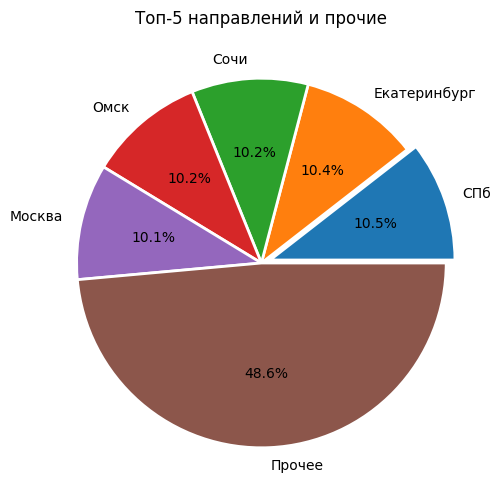

In [ ]:
df = pd.read_csv("flights.csv")

counts = df["destination"].value_counts()
top5 = counts.head(5)
other = counts.iloc[5:].sum()

combined = pd.concat([
    top5,
    pd.Series({"Прочее": other})
])

fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    combined.values,
    labels=combined.index,
    autopct="%1.1f%%",
    explode=(0.05, 0, 0, 0, 0, 0),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

ax.set_title("Топ-5 направлений и прочие")

plt.show()

# pd.concat объединяет несколько Series в одну.
# pd.Series({"Прочее": other}) создаёт один элемент с нужным названием.
# Мелкие категории объединяют, чтобы не было множества мелких секторов.
# pie подходит для долей целого, примерно до 7 категорий.
# Значения должны быть неотрицательными и суммируемыми.
# autopct=lambda p: f"{p * combined.sum() / 100:.0f}"
# показывает абсолютные значения вместо процентов.
# value_counts() уже сортирует категории по убыванию количества.
# Для сравнения долей порядок по размеру обычно полезнее алфавитного.
# explode=(0.05, 0, ...) немного отделяет первый сектор.
# Доля "Прочее" зависит от данных и может оказаться самой большой.

Задача 21 (twinx на данных аэропорта). Аэропорт визуализирует число рейсов и среднюю загрузку рейса — две переменные с разными масштабами (рейсы 100–500 в день, загрузка 60–95%). Постройте число рейсов на ax1 столбцами и среднюю загрузку на ax2 = ax1.twinx() линией. Обязательно свяжите цвета: ax1.tick_params(axis="y", labelcolor="C0"), ax2.tick_params(axis="y", labelcolor="C1"). Настройте FuncFormatter для загрузки (f"{v:.0f}%") и рейсов (f"{v:.0f}"). Соберите общую легенду через get_legend_handles_labels(). Ожидаемый вывод: число рейсов и загрузка на одной оси с разными шкалами; цвета осей совпадают с цветом данных. В комментариях объясните: зачем twinx (несопоставимые масштабы — без него загрузка «схлопнется» в плоскую линию на фоне числа рейсов); почему обязательно связывать цвет данных и осей; как get_legend_handles_labels() собирает элементы с обеих осей и почему ax1.legend() покажет только линии ax1; когда twiny (вторая ось X) уместнее — например, две шкалы по времени (дни и недели); как ax2.spines["right"].set_color("C1") красит правую рамку в цвет данных; что произойдёт без set_ylim на каждой оси — Matplotlib сам подберёт диапазон, но иногда начнёт с нуля и «сплющит» загрузку (75% и 80% будут неразличимы).

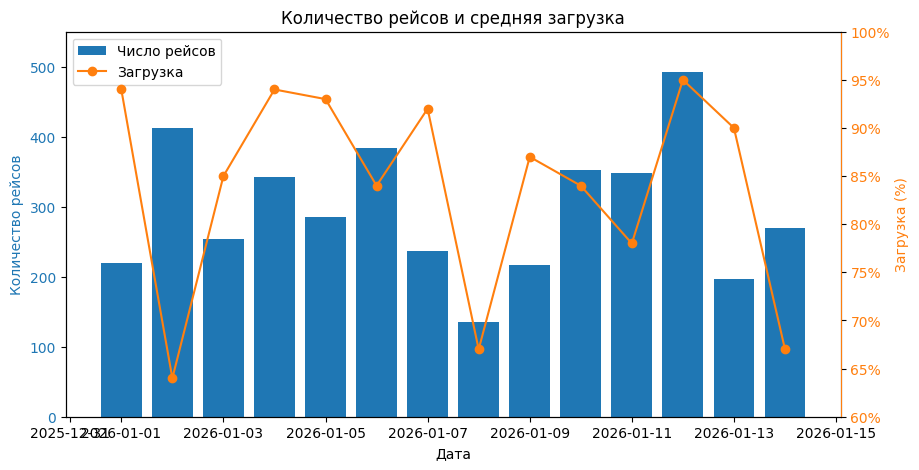

In [ ]:
import matplotlib.ticker as mticker

rng = np.random.default_rng(21)
dates = pd.date_range("2026-01-01", periods=14)

df = pd.DataFrame({
    "date": dates,
    "flights": rng.integers(100, 501, 14),
    "load_factor": rng.integers(60, 96, 14)
})

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

# Первая ось — количество рейсов
ax1.bar(
    df["date"], df["flights"],
    color="C0", label="Число рейсов"
)

# Вторая ось — загрузка
ax2.plot(
    df["date"], df["load_factor"],
    color="C1", marker="o", label="Загрузка"
)

ax1.tick_params(axis="y", labelcolor="C0")
ax2.tick_params(axis="y", labelcolor="C1")

ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, pos: f"{v:.0f}")
)

ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, pos: f"{v:.0f}%")
)

ax2.spines["right"].set_color("C1")

ax1.set_ylim(0, 550)
ax2.set_ylim(60, 100)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

ax1.legend(h1 + h2, l1 + l2)

ax1.set_title("Количество рейсов и средняя загрузка")
ax1.set_xlabel("Дата")
ax1.set_ylabel("Количество рейсов", color="C0")
ax2.set_ylabel("Загрузка (%)", color="C1")

plt.show()

# twinx создаёт вторую ось Y с независимой шкалой.
# Без неё значения загрузки могут быть плохо различимы
# на фоне гораздо большего количества рейсов.
# Цвета осей соответствуют цветам данных для понятного сравнения.
# FuncFormatter задаёт формат подписей делений.
# get_legend_handles_labels собирает элементы с каждой оси.
# Обычный ax1.legend() не включит линии, построенные на ax2.
# twiny создаёт вторую ось X, например для дней и недель.
# spines["right"].set_color меняет цвет правой рамки.
# Без set_ylim Matplotlib подбирает пределы автоматически,
# из-за чего небольшие различия иногда плохо видны.

Задача 22 (box plot из read_csv). Аэропорт сравнивает задержки по авиакомпаниям (Аэрофлот, S7, Победа, Уральские авиалинии). Постройте box plot двумя способами: через df.boxplot(column="delay_min", by="airline", grid=False, patch_artist=True) (обёртка Pandas) и вручную через groups = [g["delay_min"].values for _, g in df.groupby("airline")]; ax.boxplot(groups, tick_labels=names, patch_artist=True, medianprops=dict(color="red", linewidth=2)). Ожидаемый вывод: одинаковые графики двумя разными способами. В комментариях объясните: как df.boxplot(by=...) связан с Matplotlib (это просто обёртка, которая вызывает ax.boxplot под капотом); зачем grid=False; что такое notch=True (вырез для доверительного интервала медианы — если «талии» двух ящиков не пересекаются, медианы различаются статистически); почему patch_artist=True нужен для закраски ящиков и без него facecolor игнорируется; почему в новых версиях Matplotlib (3.9+) параметр labels устарел в пользу tick_labels; что произойдёт при малой выборке (5–10 значений) — box plot станет малоинформативным, лучше strip plot (ax.scatter с jitter).

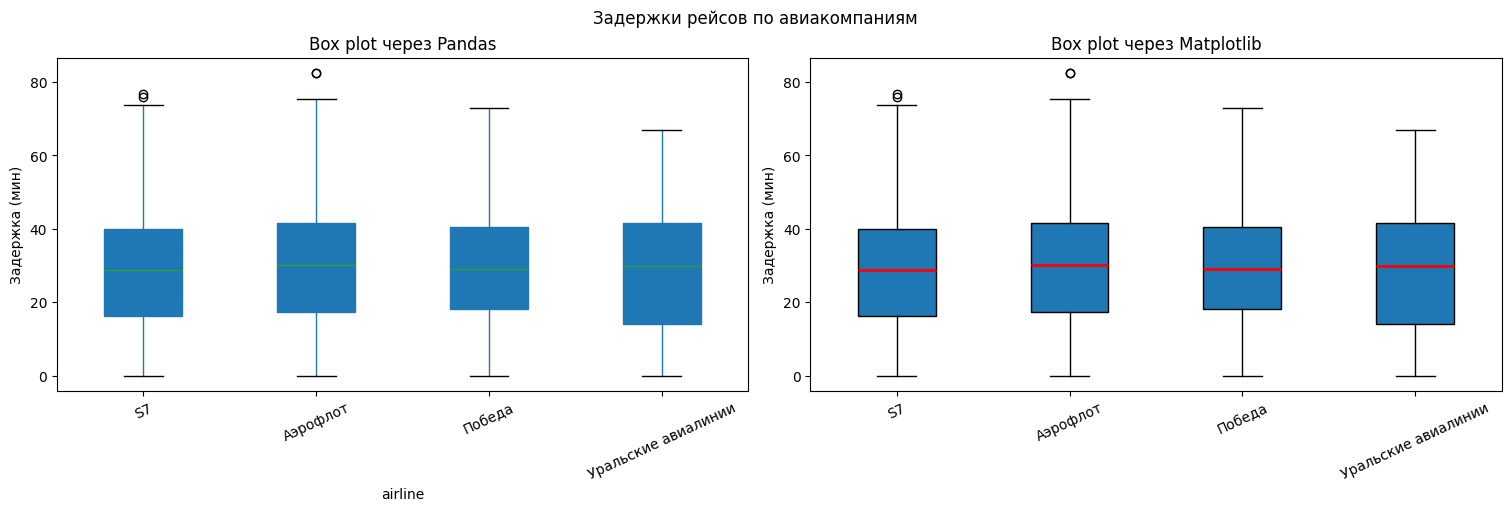

In [ ]:
df = pd.read_csv("airline_delays.csv")

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 5), layout="constrained"
)

# Способ 1 — через Pandas
df.boxplot(
    column="delay_min",
    by="airline",
    grid=False,
    patch_artist=True,
    ax=ax1
)

ax1.set_title("Box plot через Pandas")

# Способ 2 — через Matplotlib
names = sorted(df["airline"].unique())

groups = [
    df.loc[df["airline"] == name, "delay_min"].values
    for name in names
]

ax2.boxplot(
    groups,
    tick_labels=names,
    patch_artist=True,
    medianprops=dict(color="red", linewidth=2)
)

ax2.set_title("Box plot через Matplotlib")

ax1.tick_params(axis="x", rotation=25)
ax2.tick_params(axis="x", rotation=25)

ax1.set_ylabel("Задержка (мин)")
ax2.set_ylabel("Задержка (мин)")

fig.suptitle("Задержки рейсов по авиакомпаниям")

plt.show()

# df.boxplot() — обёртка Pandas над Matplotlib.
# grid=False отключает сетку.
# patch_artist=True создаёт закрашиваемые ящики.
# Без patch_artist нельзя нормально задать facecolor ящиков.
# notch=True добавляет вырезы для приближённого интервала медианы.
# Непересекающиеся вырезы могут указывать на различие медиан.
# В Matplotlib 3.9+ вместо labels используют tick_labels.
# medianprops изменяет оформление линии медианы.
# При 5–10 значениях box plot малоинформативен.
# Для маленьких выборок лучше показать отдельные точки
# через scatter с небольшим случайным смещением (jitter).

Задача 23 (FigureBuilder — ООП-обёртка для сетки). Аэропорт готовит дашборд из 4 графиков (динамика пассажиропотока, топ направлений, распределение задержек, рейсы по авиакомпаниям). При построении код обрастает повторяющимися axes[i, j].plot(...) и axes[i, j].set_title(...). Реализуйте class FigureBuilder с __init__(self, nrows=1, ncols=1, **kw), методами plot(i, j, x, y, **kw), title(i, j, text, **kw), grid(**kw) и savefig(path, **kw), возвращающими self для цепочек. Используйте np.atleast_2d(self.axes), чтобы индексация [i, j] работала и для одномерных сеток. Создайте FigureBuilder(2, 2, figsize=(12, 8), layout="constrained").plot(0, 0, ...).title(0, 0, "Пассажиропоток").grid(alpha=0.3).savefig("dashboard.png", dpi=300). Ожидаемый вывод: сетка 2×2 с 4 графиками. В комментариях объясните: зачем fluent API (читаемость цепочек — код похож на английский); что произойдёт при subplots(1, 3) без atleast_2d (одномерный массив — индексация [0, 1] выбросит IndexError); как расширить класс методами set_xlabel, legend, axhline, чтобы сохранить принцип единственной ответственности; когда такой класс — овер-инжиниринг; как связать FigureBuilder с PlotConfig из задачи 2; почему return self в каждом методе — ключевой паттерн (позволяет цепочки любой длины).

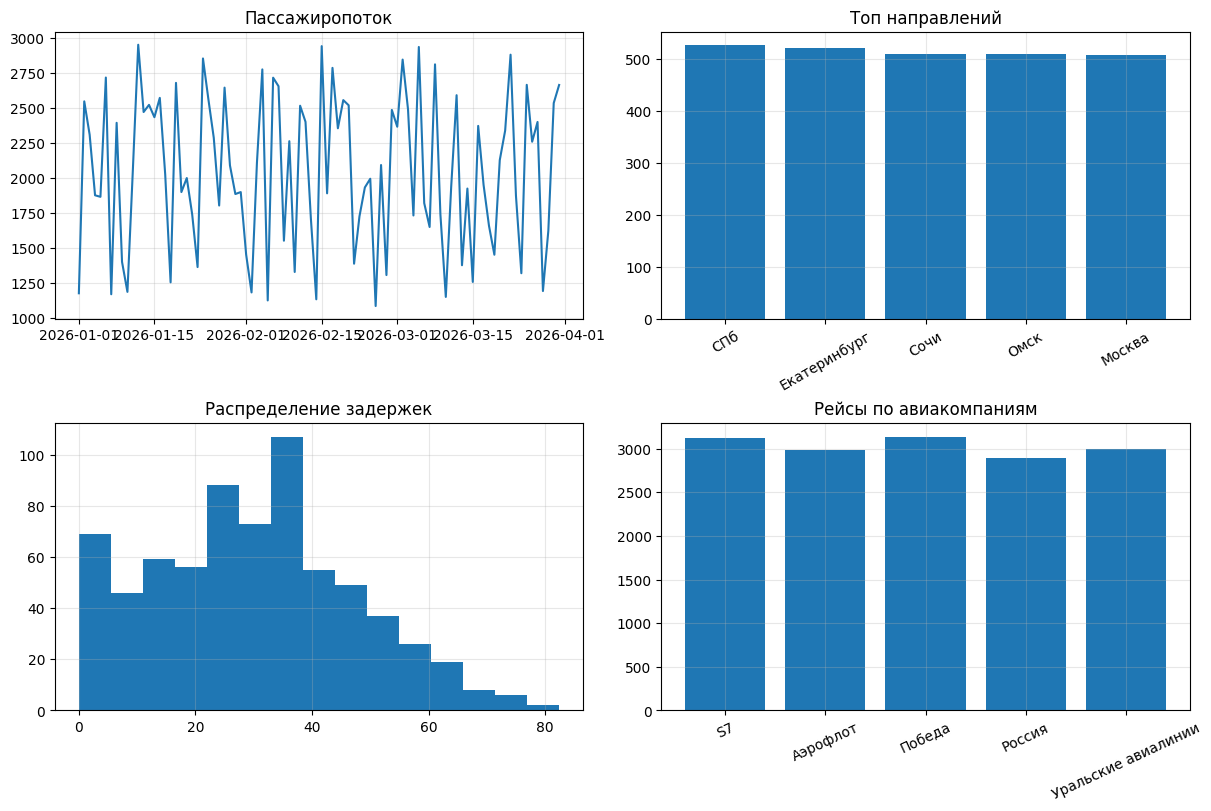

In [ ]:
class FigureBuilder:
    def __init__(self, nrows=1, ncols=1, **kw):
        self.fig, self.axes = plt.subplots(nrows, ncols, **kw)
        self.axes = np.atleast_2d(self.axes).reshape(nrows, ncols)

    def plot(self, i, j, x, y, **kw):
        self.axes[i, j].plot(x, y, **kw)
        return self

    def title(self, i, j, text, **kw):
        self.axes[i, j].set_title(text, **kw)
        return self

    def grid(self, **kw):
        for ax in self.axes.flat:
            ax.grid(**kw)
        return self

    def savefig(self, path, **kw):
        self.fig.savefig(path, **kw)
        return self


passengers = pd.read_csv("passengers.csv", parse_dates=["date"])
flights = pd.read_csv("flights.csv")
delays = pd.read_csv("airline_delays.csv")
airlines = pd.read_csv("flights_by_airline.csv")

top = flights["destination"].value_counts().head(5)
by_airline = airlines.groupby("airline")["count"].sum()

builder = (
    FigureBuilder(2, 2, figsize=(12, 8), layout="constrained")
    .plot(0, 0, passengers["date"], passengers["passengers"])
    .title(0, 0, "Пассажиропоток")
)

builder.axes[0, 1].bar(top.index, top.values)
builder.axes[1, 0].hist(delays["delay_min"], bins=15)
builder.axes[1, 1].bar(by_airline.index, by_airline.values)

builder.axes[0, 1].tick_params(axis="x", rotation=30)
builder.axes[1, 1].tick_params(axis="x", rotation=25)

(
    builder
    .title(0, 1, "Топ направлений")
    .title(1, 0, "Распределение задержек")
    .title(1, 1, "Рейсы по авиакомпаниям")
    .grid(alpha=0.3)
    .savefig("dashboard.png", dpi=300)
)

plt.show()

# return self позволяет вызывать методы цепочкой (fluent API).
# np.atleast_2d обеспечивает двумерную индексацию axes[i, j].
# При subplots(1, 3) без этого axes — одномерный массив,
# поэтому обращение axes[0, 1] вызовет IndexError.
# reshape дополнительно учитывает сетки с одним столбцом.
# Класс можно расширить методами set_xlabel, legend, axhline,
# не смешивая построение графиков с обработкой данных.
# Для одного простого графика такой класс был бы избыточным.
# PlotConfig из задания 2 можно передать через параметры FigureBuilder.
# return self позволяет продолжать цепочку методов любой длины.

Задача 24 (GridSpec и subplot_mosaic). Аэропорт строит дашборд с большим графиком динамики пассажиропотока сверху и двумя меньшими снизу (топ направлений и авиакомпании). Реализуйте двумя способами: через gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], width_ratios=[3, 1]) с ax1 = fig.add_subplot(gs[0, :]), ax2 = fig.add_subplot(gs[1, 0]), ax3 = fig.add_subplot(gs[1, 1]); и через fig, axes = plt.subplot_mosaic("AAA;BC", figsize=(12, 8), layout="constrained") с обращением axes["A"], axes["B"], axes["C"]. Ожидаемый вывод: верхний график во всю ширину в 2× выше нижних. В комментариях объясните: как gs[0, :] означает «вся первая строка» (срез по NumPy), а gs[1, 0] — конкретная ячейка; зачем height_ratios=[2, 1] и width_ratios=[3, 1]; почему subplot_mosaic читается лучше для сложных сеток («AAA;BC» — почти как ASCII-арт); как GridSpecFromSubplotSpec создаёт вложенные сетки; что произойдёт при пересечении областей (например, gs[0, :2] и gs[0, 1:] — наложение, Matplotlib выдаст предупреждение); как сохранить layout="constrained" с GridSpec (передать в figure(layout="constrained")).

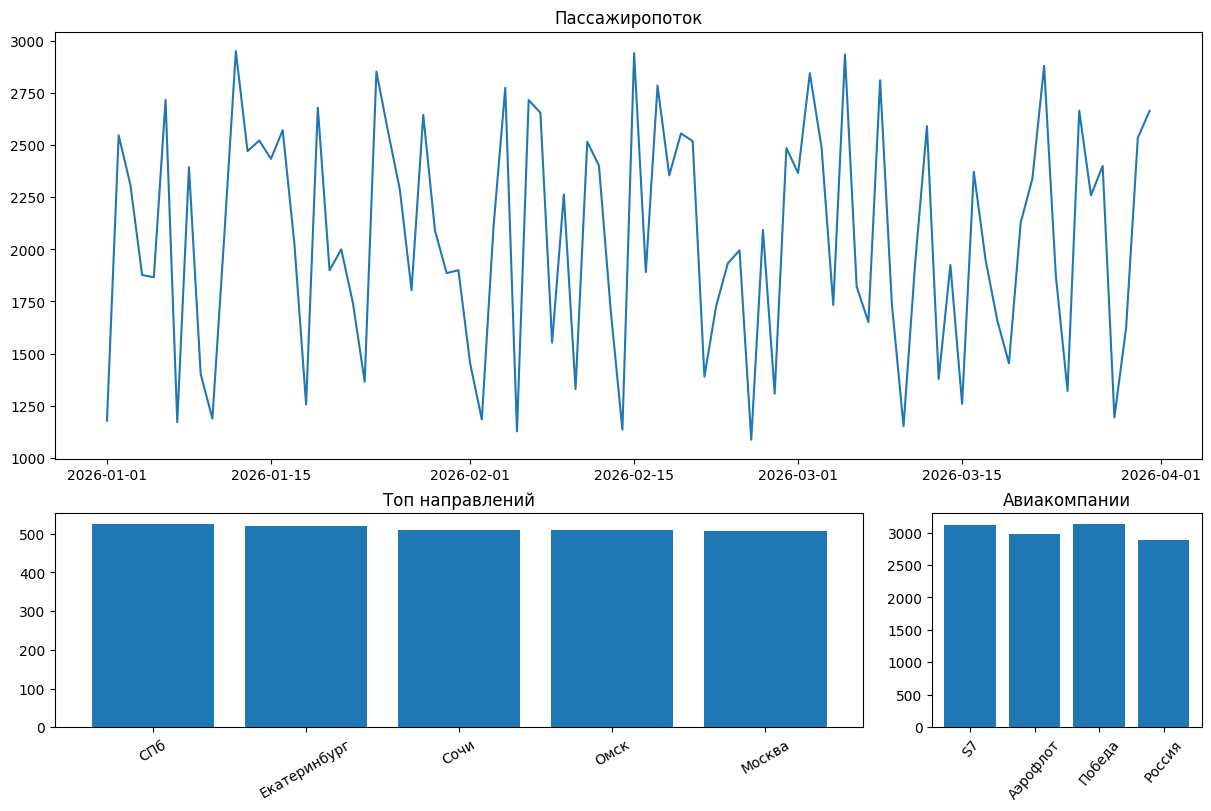

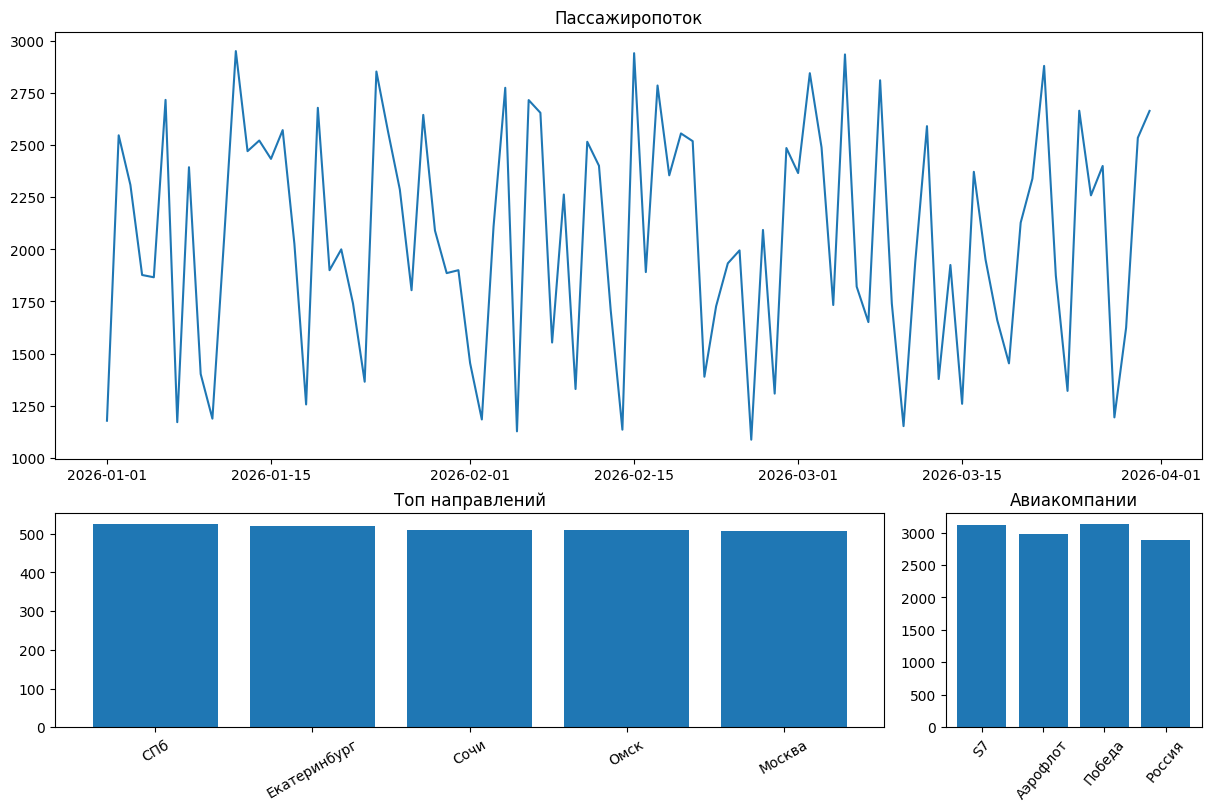

In [ ]:
passengers = pd.read_csv("passengers.csv", parse_dates=["date"])
flights = pd.read_csv("flights.csv")
airlines = pd.read_csv("flights_by_airline.csv")

top = flights["destination"].value_counts().head(5)
companies = airlines.groupby("airline")["count"].sum().head(4)

# Способ 1 — GridSpec
fig1 = plt.figure(figsize=(12, 8), layout="constrained")

gs = fig1.add_gridspec(
    2, 2,
    height_ratios=[2, 1],
    width_ratios=[3, 1]
)

ax1 = fig1.add_subplot(gs[0, :])
ax2 = fig1.add_subplot(gs[1, 0])
ax3 = fig1.add_subplot(gs[1, 1])

# Способ 2 — subplot_mosaic
fig2, axes = plt.subplot_mosaic(
    "AAA;BBC",
    figsize=(12, 8),
    layout="constrained",
    height_ratios=[2, 1],
    width_ratios=[1.5, 1.5, 1]
)

# Заполняем обе фигуры одинаковыми графиками
for ax_top, ax_dest, ax_airline in [
    (ax1, ax2, ax3),
    (axes["A"], axes["B"], axes["C"])
]:
    ax_top.plot(passengers["date"], passengers["passengers"])
    ax_top.set_title("Пассажиропоток")

    ax_dest.bar(top.index, top.values)
    ax_dest.set_title("Топ направлений")
    ax_dest.tick_params(axis="x", rotation=30)

    ax_airline.bar(companies.index, companies.values)
    ax_airline.set_title("Авиакомпании")
    ax_airline.tick_params(axis="x", rotation=50)

plt.show()

# gs[0, :] означает всю первую строку сетки.
# gs[1, 0] означает конкретную ячейку второй строки.
# height_ratios=[2, 1] делает верхнюю строку вдвое выше нижней.
# width_ratios=[3, 1] задаёт соотношение ширины нижних графиков.
# subplot_mosaic описывает расположение буквами, как ASCII-схему.
# GridSpecFromSubplotSpec позволяет делать вложенные сетки.
# Например, gs[1, 0].subgridspec(2, 1) создаст вложенную сетку.
# При пересечении областей графики могут перекрывать друг друга.
# Для GridSpec constrained layout задаётся при создании Figure.

Задача 25 (sharex/sharey и синхронизация зума). Аэропорт строит два подграфика: дневной пассажиропоток и его первая разность (прирост день ко дню). Обе линии относятся к одним и тем же датам, и хочется синхронизировать зум. Создайте fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 8), layout="constrained"), постройте axes[0].plot(df.index, df["passengers"]) и axes[1].plot(df.index, df["passengers"].diff()), уберите подпись X у верхнего (axes[0].set_xlabel("")). Дополнительно создайте вторую фигуру без layout и примените fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, hspace=0.05) — почти вплотную. Ожидаемый вывод: две синхронизированные оси X; без дублирования подписи. В комментариях объясните: как sharex синхронизирует зум (перетаскивание одной оси двигает обе); зачем убирать подпись X у верхнего подграфика (визуальный шум — даты повторяются); почему subplots_adjust не работает с layout="constrained"; что делает hspace=0.05; как ax.get_xlim() получить текущие границы для сохранения в отчёт; что произойдёт при sharex="col" в сетке 2×2.

Границы X: (np.float64(20725.55), np.float64(20757.45))


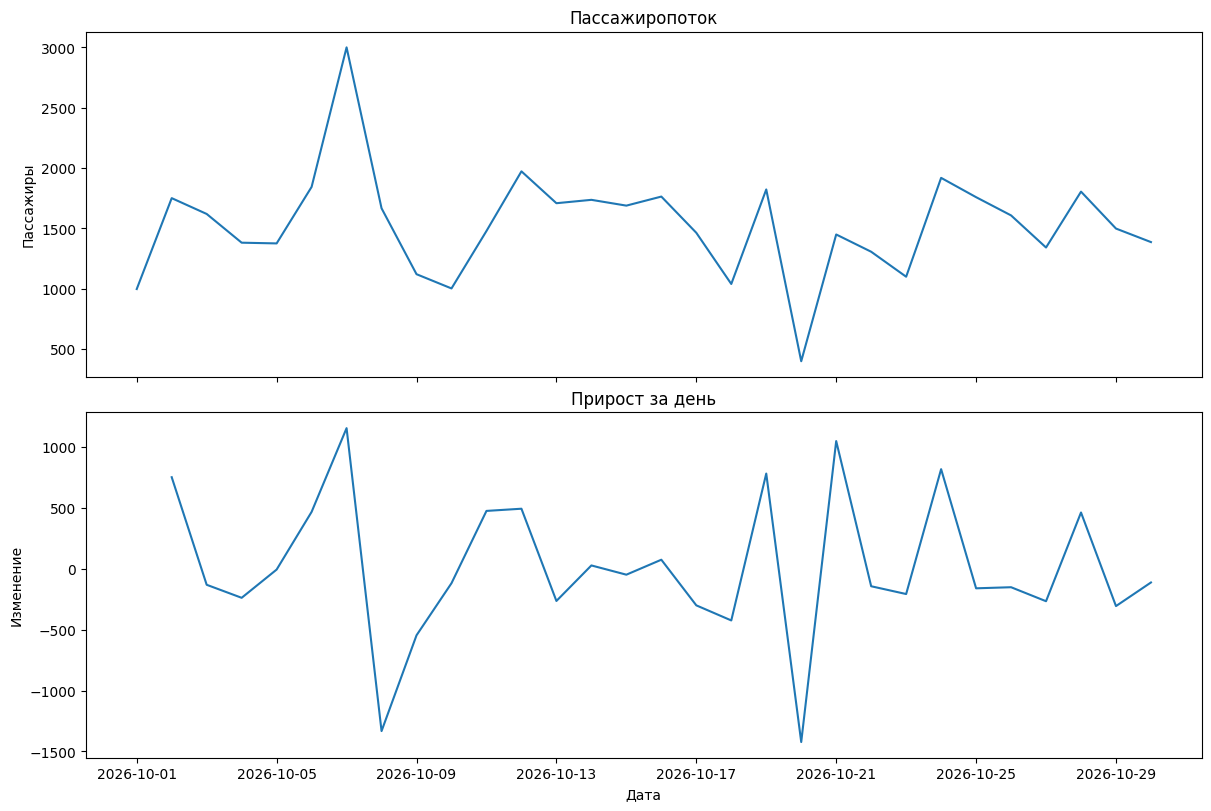

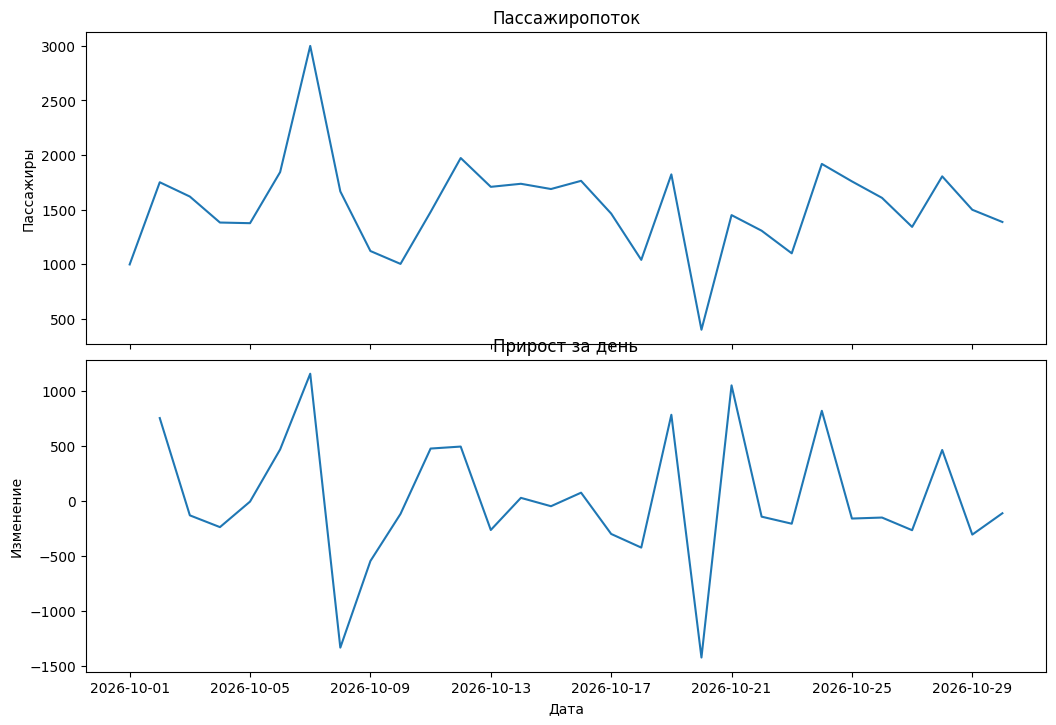

In [ ]:
df = pd.read_csv(
    "daily_passengers.csv",
    parse_dates=["date"],
    index_col="date"
)

# Первая фигура — constrained layout
fig1, axes1 = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(12, 8),
    layout="constrained"
)

# Вторая фигура — ручные отступы
fig2, axes2 = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(12, 8)
)

for axes in [axes1, axes2]:
    axes[0].plot(df.index, df["passengers"])
    axes[0].set_title("Пассажиропоток")
    axes[0].set_ylabel("Пассажиры")
    axes[0].set_xlabel("")

    axes[1].plot(df.index, df["passengers"].diff())
    axes[1].set_title("Прирост за день")
    axes[1].set_xlabel("Дата")
    axes[1].set_ylabel("Изменение")

fig2.subplots_adjust(
    left=0.1,
    right=0.9,
    top=0.9,
    bottom=0.1,
    hspace=0.05
)

print("Границы X:", axes1[0].get_xlim())

plt.show()

# sharex=True связывает масштабы осей X двух графиков.
# При изменении зума одного графика второй изменится вместе с ним.
# Подпись X сверху убирают, чтобы не повторять даты.
# constrained автоматически настраивает расстояния между графиками.
# subplots_adjust нельзя нормально сочетать с constrained layout.
# hspace=0.05 задаёт маленький вертикальный промежуток.
# get_xlim() возвращает текущие границы оси X.
# sharex="col" в сетке 2×2 связывает оси X внутри каждого столбца.

Задача 26 (bar с yerr из agg(["mean", "std"])). Аэропорт сравнивает среднюю задержку по авиакомпаниям с учётом разброса между рейсами. Получите stats = results.groupby("airline")["delay_min"].agg(["mean", "std"]). Постройте bars = ax.bar(stats.index, stats["mean"], yerr=stats["std"], capsize=8, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(stats))), edgecolor="black"). Установите ax.set_ylim(0, stats["mean"].max() * 1.3), подпишите значения через for bar, (m, s) in zip(bars, stats.itertuples(index=False)): ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + s + 1, f"{m:.1f}", ha="center"). Ожидаемый вывод: столбцы с планками ошибок и подписями. В комментариях объясните: как agg(["mean", "std"]) готовит данные в одну строку (что было бы без agg — пришлось бы дважды вызывать groupby); почему yerr=std корректен (это стандартное отклонение, а не SEM; для SEM поделите на sqrt(n)); почему set_ylim с запасом * 1.3 (чтобы планки и подписи не обрезались); что произойдёт без capsize; как zip(bars, stats.itertuples()) обходит две коллекции одновременно; почему для метрик-долей set_ylim(0, 1) обязателен.

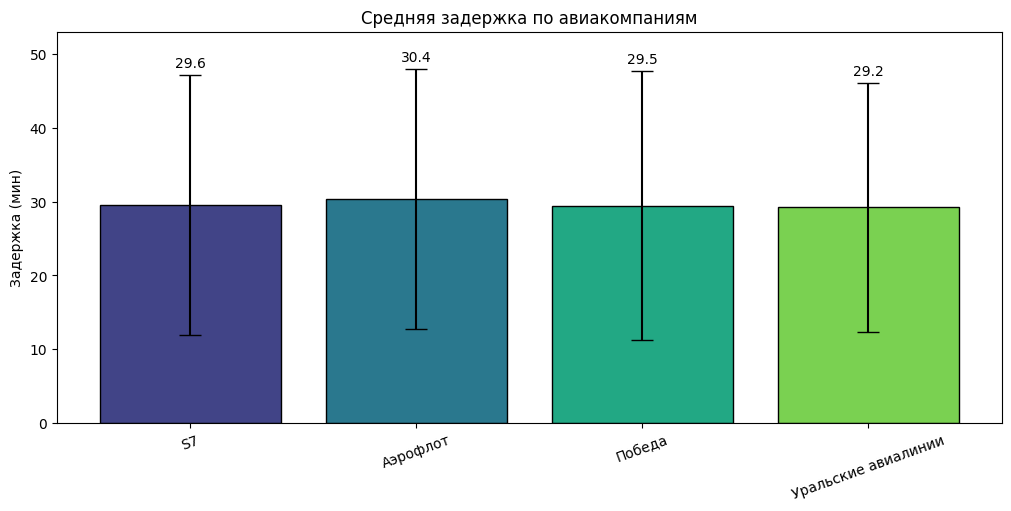

In [ ]:
results = pd.read_csv("airline_delays.csv")

stats = results.groupby("airline")["delay_min"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

bars = ax.bar(
    stats.index,
    stats["mean"],
    yerr=stats["std"],
    capsize=8,
    color=plt.cm.viridis(np.linspace(0.2, 0.8, len(stats))),
    edgecolor="black"
)

ax.set_ylim(
    0,
    max(stats["mean"].max() * 1.3,
        (stats["mean"] + stats["std"]).max() + 5)
)

for bar, (m, s) in zip(bars, stats.itertuples(index=False)):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + s + 1,
        f"{m:.1f}",
        ha="center"
    )

ax.set_title("Средняя задержка по авиакомпаниям")
ax.set_ylabel("Задержка (мин)")
ax.tick_params(axis="x", rotation=20)

plt.show()

# agg(["mean", "std"]) вычисляет среднее и стандартное отклонение.
# Без agg пришлось бы отдельно рассчитывать эти показатели.
# yerr=std показывает разброс задержек, а не ошибку среднего.
# SEM = std / sqrt(n), где n — количество наблюдений.
# set_ylim добавляет запас, чтобы планки и подписи не обрезались.
# capsize создаёт горизонтальные окончания планок ошибок.
# Без capsize окончания не будут отображаться.
# zip позволяет одновременно перебрать столбцы и статистику.
# Для долей от 0 до 1 удобно использовать set_ylim(0, 1).

Задача 27 (scatter + RANSAC-тренд). Аэропорт анализирует связь числа стоек регистрации и времени ожидания пассажиров, но в данных есть несколько дней с аномальными результатами (сбой системы, массовые задержки) — они искажают картину. Обычная линейная регрессия через np.polyfit сдвигается этими выбросами. Реализуйте два тренда: OLS через m, b = np.polyfit(x, y, 1) и RANSAC через RANSACRegressor(random_state=42).fit(X, y). Наложите оба: OLS — "r--", RANSAC — "g-", подпишите в легенде. Вычислите r_pearson = np.corrcoef(x, y)[0, 1] и r_spearman = scipy.stats.spearmanr(x, y).correlation. В комментариях объясните: чем OLS отличается от RANSAC; как интерпретировать разницу между r_pearson и r_spearman (нелинейность, выбросы — если Пирсон «портится», а Спирмен стабилен, значит, выбросы); почему polyfit(deg=2) для нелинейных зависимостей (например, эффект «насыщения» — после N стоек ожидание падает нелинейно); как zorder держит RANSAC-линию поверх точек; что произойдёт при полном отсутствии выбросов (RANSAC ≈ OLS); как сохранить ransac.estimator_ — коэффициенты найденной модели для отчёта.

Коэффициент RANSAC: [-2.56238872]
Свободный член RANSAC: 52.96999056448829


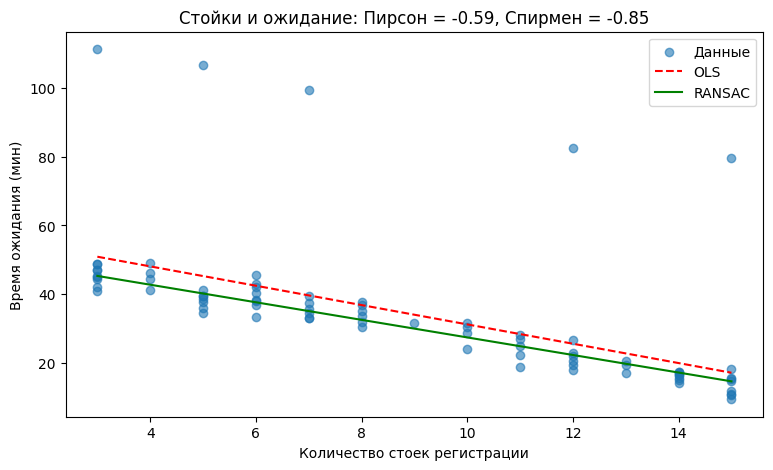

In [ ]:
from sklearn.linear_model import RANSACRegressor
from scipy.stats import spearmanr

rng = np.random.default_rng(27)

x = rng.integers(3, 16, 80)
y = 55 - 2.8 * x + rng.normal(0, 3, len(x))

# Аномальные дни
y[:5] += 65

# Обычная линейная регрессия
m, b = np.polyfit(x, y, 1)

# RANSAC
ransac = RANSACRegressor(random_state=42)
ransac.fit(x.reshape(-1, 1), y)

x_line = np.linspace(x.min(), x.max(), 100)

r_pearson = np.corrcoef(x, y)[0, 1]
r_spearman = spearmanr(x, y).correlation

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(x, y, alpha=0.6, label="Данные", zorder=2)

ax.plot(
    x_line, m * x_line + b,
    "r--", label="OLS", zorder=3
)

ax.plot(
    x_line,
    ransac.predict(x_line.reshape(-1, 1)),
    "g-", label="RANSAC", zorder=4
)

ax.set_title(
    f"Стойки и ожидание: Пирсон = {r_pearson:.2f}, "
    f"Спирмен = {r_spearman:.2f}"
)

ax.set_xlabel("Количество стоек регистрации")
ax.set_ylabel("Время ожидания (мин)")
ax.legend()

print("Коэффициент RANSAC:", ransac.estimator_.coef_)
print("Свободный член RANSAC:", ransac.estimator_.intercept_)

plt.show()

# OLS минимизирует сумму квадратов ошибок всех наблюдений.
# RANSAC ищет тренд по согласованным точкам и устойчивее к выбросам.
# Разница между Пирсоном и Спирменом может указывать на выбросы
# или нелинейную монотонную зависимость.
# polyfit с deg=2 подходит для приближения квадратичной зависимости.
# zorder размещает линии поверх точек.
# Без выбросов RANSAC и OLS обычно дают близкие результаты.
# ransac.estimator_ хранит обученную модель и её коэффициенты.

Задача 28 (contour функции потерь). Аэропорт использует ML для прогнозирования задержек. Чтобы понять, насколько сложна оптимизация модели, визуализируйте функцию потерь от двух параметров (например, w1 = порог загрузки, w2 = порог ветра). Используйте функцию Розенброка loss(w1, w2) = (w1 - 1)**2 + 10 * (w2 - w1**2)**2. Создайте meshgrid 200×200, постройте cf = ax.contourf(W1, W2, np.log1p(Z), levels=20, cmap="viridis") и поверх ax.contour(W1, W2, np.log1p(Z), levels=15, colors="white", linewidths=0.5). Отметьте минимум ax.plot(1, 1, "r*", markersize=20). Ожидаемый вывод: «долина Розенброка» с изолиниями и минимумом. В комментариях объясните: зачем np.log1p(Z) (сжать динамический диапазон — иначе вся «долина» будет одного цвета); почему для несимметричных данных выбирают sequential-палитру, а для симметричных относительно нуля — diverging (RdBu); что делает clabel(contour, inline=True); как levels=np.logspace(-1, 3, 20) помогает для данных, меняющихся в тысячи раз; что произойдёт при levels=3 (теряется форма); как norm="log" в contourf автоматически применяет логарифмическую шкалу.

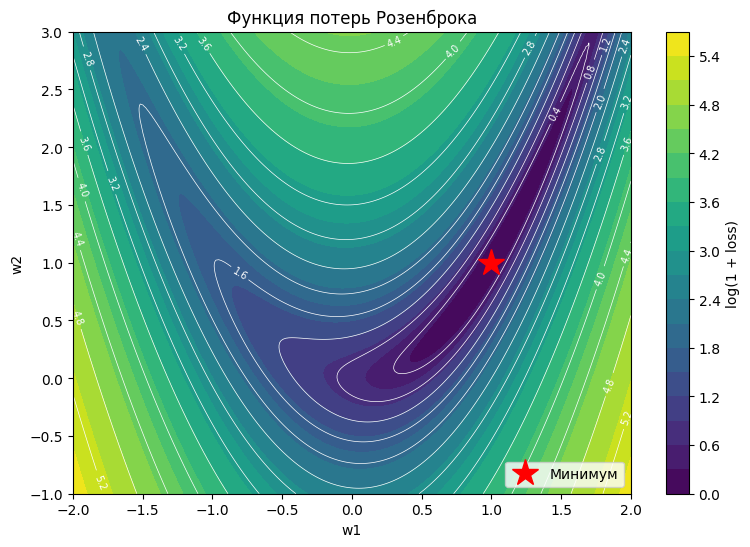

In [ ]:
w1 = np.linspace(-2, 2, 200)
w2 = np.linspace(-1, 3, 200)

W1, W2 = np.meshgrid(w1, w2)

Z = (W1 - 1)**2 + 10 * (W2 - W1**2)**2

fig, ax = plt.subplots(figsize=(9, 6))

cf = ax.contourf(
    W1, W2, np.log1p(Z),
    levels=20,
    cmap="viridis"
)

contour = ax.contour(
    W1, W2, np.log1p(Z),
    levels=15,
    colors="white",
    linewidths=0.5
)

ax.clabel(contour, inline=True, fontsize=7)

ax.plot(1, 1, "r*", markersize=20, label="Минимум")

fig.colorbar(cf, ax=ax, label="log(1 + loss)")

ax.set_xlabel("w1")
ax.set_ylabel("w2")
ax.set_title("Функция потерь Розенброка")
ax.legend()

plt.show()

# meshgrid создаёт двумерную сетку координат 200×200.
# log1p(Z) сжимает диапазон значений, делая долину заметнее.
# viridis — последовательная палитра для неотрицательных значений.
# Для величин вокруг нуля удобна расходящаяся палитра RdBu.
# contourf создаёт заполненные области, contour — линии уровней.
# clabel подписывает значения на линиях.
# levels=3 даст слишком мало деталей.
# np.logspace(-1, 3, 20) полезен для логарифмических уровней.
# norm="log" задаёт логарифмическую шкалу для положительных значений.

Задача 29 (heatmap корреляций). Аэропорт изучает, какие признаки сильнее всего коррелируют с задержкой вылета (загрузка, ветер, видимость, число стоек, время дня, температура). Постройте corr = df.select_dtypes("number").corr(method="spearman") (ранговая корреляция устойчива к выбросам), затем im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1) с fig.colorbar(im, label="Spearman ρ"). Скройте верхнюю половину через маску mask = np.triu(np.ones_like(corr, dtype=bool), k=1); corr_masked = corr.mask(mask). Аннотируйте значения через for i, j in zip(*np.where(~mask)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center"). Ожидаемый вывод: матрица 6×6 с диагональю 1.0 и цветовой шкалой. В комментариях объясните: почему vmin=-1, vmax=1 фиксирует диапазон (нуль всегда белый, иначе цвет «плавает» в зависимости от данных); зачем diverging-палитра RdBu для корреляций; как select_dtypes("number") защищает от ошибок (строковые столбцы типа «авиакомпания» не коррелируют); почему method="spearman" предпочтительнее pearson для реальных операционных данных; как np.where(~mask) даёт координаты только нижнего треугольника; как отсортировать признаки по корреляции с целевой (corr.abs().sort_values(by="delay_min", ascending=False)) для приоритизации.

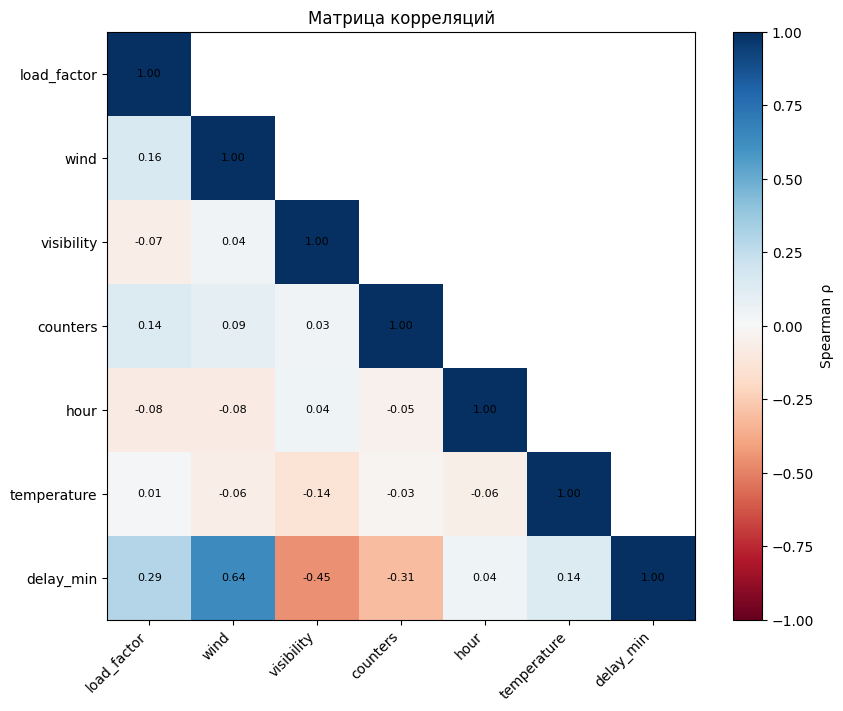

In [ ]:
rng = np.random.default_rng(29)
n = 150

load = rng.uniform(60, 100, n)
wind = rng.uniform(0, 30, n)
visibility = rng.uniform(1, 15, n)
counters = rng.integers(3, 15, n)
hours = rng.integers(0, 24, n)
temp = rng.uniform(-10, 30, n)

delay = (
    20 + 0.3 * load + 1.3 * wind
    - 1.8 * visibility - 1.5 * counters
    + 0.25 * hours + 0.2 * temp
    + rng.normal(0, 7, n)
)

df = pd.DataFrame({
    "load_factor": load,
    "wind": wind,
    "visibility": visibility,
    "counters": counters,
    "hour": hours,
    "temperature": temp,
    "delay_min": delay
})

corr = df.select_dtypes("number").corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
corr_masked = corr.mask(mask)

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")

im = ax.imshow(corr_masked, cmap="RdBu", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)), corr.columns,
              rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)

for i, j in zip(*np.where(~mask)):
    ax.text(
        j, i,
        f"{corr.iloc[i, j]:.2f}",
        ha="center",
        va="center",
        fontsize=8
    )

fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Матрица корреляций")

plt.show()

# select_dtypes("number") оставляет числовые столбцы.
# Это исключает ошибки со строковыми признаками.
# Spearman использует ранги и менее чувствителен к выбросам,
# чем Pearson, хотя не полностью защищён от них.
# vmin=-1 и vmax=1 фиксируют цвета для всех корреляций.
# RdBu — расходящаяся палитра: ноль соответствует светлому цвету.
# mask скрывает верхний треугольник матрицы.
# np.where(~mask) находит координаты видимых ячеек.
# Для сортировки по связи с задержкой можно использовать:
# corr.abs().sort_values(by="delay_min", ascending=False)

Задача 30 (box plot с notch и сравнение с violinplot). Аэропорт сравнивает распределение задержек по терминалам. Box plot компактен, но скрывает мультимодальность — а в терминале D задержка может быть бимодальной (утренние чартеры vs вечерние регулярные рейсы). Постройте bp = ax.boxplot(groups, tick_labels=names, patch_artist=True, notch=True, showmeans=True, medianprops=dict(color="red", linewidth=2), meanprops=dict(marker="D", markerfacecolor="yellow", markeredgecolor="black", markersize=10)). Рядом постройте ax.violinplot(groups, showmedians=True, showextrema=True). Ожидаемый вывод: box plot с «талией» и жёлтыми ромбами средних рядом с violin plot, где видна бимодальность в терминале D. В комментариях объясните: что показывает notch (доверительный интервал медианы — если «талии» двух ящиков не пересекаются, медианы статистически различаются); зачем showmeans, если уже есть медиана; почему violinplot информативнее box plot (видна плотность — два «горба» в терминале D сразу заметны); когда box plot лучше (мало данных, много групп — компактность); как наложить точки через ax.scatter (strip plot) поверх box plot; что произойдёт при notch=True на малой выборке (Matplotlib выведет предупреждение о ненадёжности).



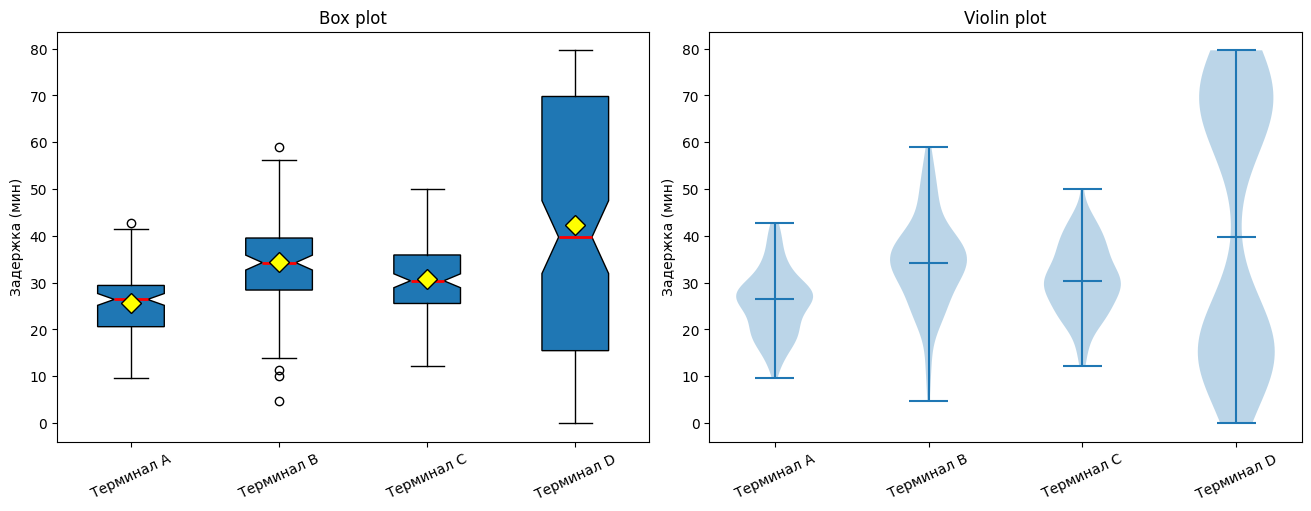

In [ ]:
rng = np.random.default_rng(30)

names = ["Терминал A", "Терминал B", "Терминал C", "Терминал D"]

groups = [
    rng.normal(25, 7, 120),
    rng.normal(35, 9, 120),
    rng.normal(30, 8, 120),
    np.concatenate([
        rng.normal(15, 4, 60),
        rng.normal(70, 6, 60)
    ])
]

groups = [np.clip(g, 0, None) for g in groups]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(13, 5), layout="constrained"
)

# Box plot
bp = ax1.boxplot(
    groups,
    tick_labels=names,
    patch_artist=True,
    notch=True,
    showmeans=True,
    medianprops=dict(color="red", linewidth=2),
    meanprops=dict(
        marker="D",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=10
    )
)

# Violin plot
ax2.violinplot(
    groups,
    showmedians=True,
    showextrema=True
)

ax2.set_xticks(np.arange(1, len(names) + 1))
ax2.set_xticklabels(names)

ax1.set_title("Box plot")
ax2.set_title("Violin plot")

ax1.set_ylabel("Задержка (мин)")
ax2.set_ylabel("Задержка (мин)")

ax1.tick_params(axis="x", rotation=25)
ax2.tick_params(axis="x", rotation=25)

plt.show()

# notch=True создаёт вырезы вокруг медианы.
# Они показывают приблизительный доверительный интервал медианы.
# Непересекающиеся вырезы могут говорить о различии медиан.
# showmeans показывает среднее, а не только медиану.
# Жёлтый ромб обозначает среднее значение.
# violinplot показывает форму плотности распределения.
# Для терминала D видны два скопления задержек.
# Box plot компактнее при большом количестве групп.
# Для отображения отдельных точек можно использовать ax.scatter
# со случайным горизонтальным смещением — jitter.
# На малой выборке notch ненадёжен и может вводить в заблуждение.

Задача 31 (errorbar + fill_between для CI + resample). Аэропорт мониторит недельный пассажиропоток с доверительным интервалом. Сгруппируйте по неделям: weekly = measurements.resample("W", on="date")["passengers"].agg(["mean", "std", "count"]). Вычислите sem = weekly["std"] / np.sqrt(weekly["count"]), ci = 1.96 * sem (95% CI для нормального распределения). Постройте ax.errorbar(weekly.index, weekly["mean"], yerr=ci, fmt="o-", capsize=6, color="steelblue") и ax.fill_between(weekly.index, weekly["mean"] - ci, weekly["mean"] + ci, alpha=0.15, color="steelblue"). Ожидаемый вывод: среднее с планками ошибок и той же полосой CI. В комментариях объясните: чем SD отличается от SEM (первое — разброс наблюдений, второе — точность оценки среднего; SEM всегда меньше SD при n > 1); зачем 1.96 * sem (95% CI для нормального распределения); когда fill_between читается лучше errorbar (плотные ряды — планки сливаются в «частокол»); как resample("W") группирует по неделям и почему нужен DatetimeIndex; что произойдёт при count = 1 в неделе (sem = 0/1 = 0, CI сжимается до точки); как использовать t-распределение для малых выборок (scipy.stats.t.ppf(0.975, df=count-1) вместо 1.96).

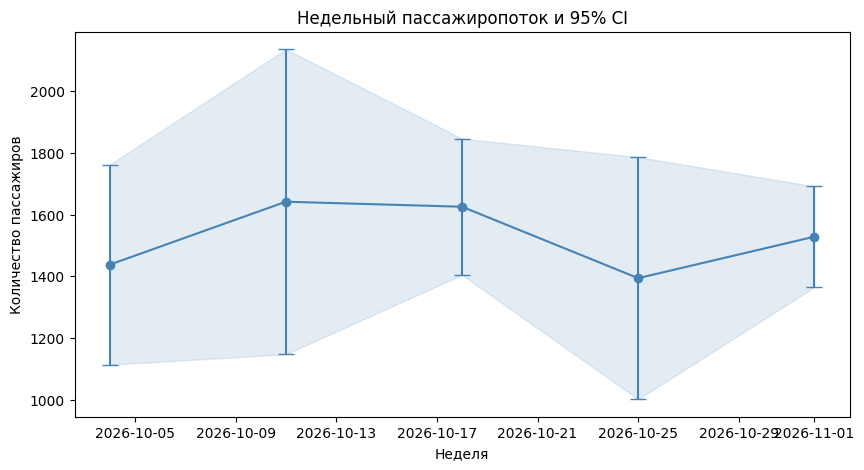

In [ ]:
measurements = pd.read_csv(
    "daily_passengers.csv",
    parse_dates=["date"]
)

weekly = measurements.resample(
    "W", on="date"
)["passengers"].agg(["mean", "std", "count"])

weekly = weekly.dropna(subset=["std"])

sem = weekly["std"] / np.sqrt(weekly["count"])
ci = 1.96 * sem

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    weekly.index,
    weekly["mean"],
    yerr=ci,
    fmt="o-",
    capsize=6,
    color="steelblue"
)

ax.fill_between(
    weekly.index,
    (weekly["mean"] - ci).to_numpy(),
    (weekly["mean"] + ci).to_numpy(),
    alpha=0.15,
    color="steelblue"
)

ax.set_title("Недельный пассажиропоток и 95% CI")
ax.set_xlabel("Неделя")
ax.set_ylabel("Количество пассажиров")

plt.show()

# resample("W") группирует данные по неделям.
# Для resample нужна дата в индексе или параметр on="date".
# SD — разброс наблюдений, SEM — ошибка оценки среднего.
# При n > 1 SEM меньше SD.
# 1.96 * SEM даёт приблизительный 95% доверительный интервал
# при подходящих предположениях о распределении и наблюдениях.
# errorbar рисует отдельные планки ошибок.
# fill_between создаёт непрерывную полосу доверительного интервала.
# Для плотных данных полоса обычно читается лучше планок.
# При count=1 выборочное std будет NaN, а не ноль.
# Такие недели здесь удаляются через dropna().
# Для малых выборок лучше использовать t-распределение:
# scipy.stats.t.ppf(0.975, df=count-1).

Задача 32 (форматирование чисел: собственные Formatter-классы). Аэропорт готовит финансовый отчёт: выручка доходит до 10 млрд руб., пунктуальность измеряется в процентах, а пассажиропоток — в миллионах. Стандартные форматтеры выглядят «сыро». Реализуйте три класса: class CompactFormatter(mticker.Formatter) (1500000 → "1.5M", 250000 → "250K"), class RubleFormatter (1500000 → "1 500 000 ₽" через f"{x:,.0f} ₽"), class PercentFormatterCustom (0.85 → "85.0%"). Сравните с готовыми EngFormatter(unit="₽") и PercentFormatter(1.0). Примените к трём подграфикам. Ожидаемый вывод: разные форматы на одной и той же оси Y. В комментариях объясните: зачем ООП-класс вместо FuncFormatter; как Formatter встраивается в Locator и почему это разделение ответственности; почему PercentFormatter(1.0) ожидает доли (0.25 → 25%), а не проценты (что было бы при PercentFormatter(100)); когда StrMethodFormatter("{x:.2f}") проще класса; как EngFormatter использует инженерные приставки (k, M, G) и когда это удобнее «M/K»; как сохранить единый формат в отчёте через plt.rcParams (нет стандартного параметра — нужна своя функция-обёртка).

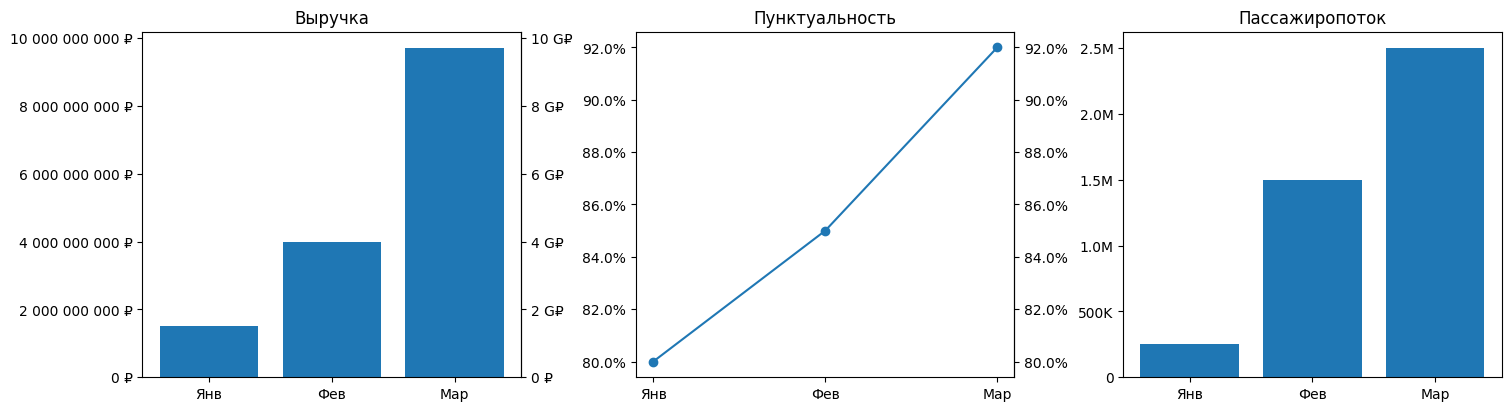

In [ ]:
import matplotlib.ticker as mticker

class CompactFormatter(mticker.Formatter):
    def __call__(self, x, pos=None):
        if abs(x) >= 1e9:
            return f"{x / 1e9:.1f}G"
        if abs(x) >= 1e6:
            return f"{x / 1e6:.1f}M"
        if abs(x) >= 1e3:
            return f"{x / 1e3:.0f}K"
        return f"{x:.0f}"

class RubleFormatter(mticker.Formatter):
    def __call__(self, x, pos=None):
        return f"{x:,.0f} ₽".replace(",", " ")

class PercentFormatterCustom(mticker.Formatter):
    def __call__(self, x, pos=None):
        return f"{x * 100:.1f}%"


months = ["Янв", "Фев", "Мар"]
revenue = [1.5e9, 4e9, 9.7e9]
punctuality = [0.80, 0.85, 0.92]
passengers = [250000, 1500000, 2500000]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4), layout="constrained"
)

# Рубли: свой Formatter слева, готовый справа
axes[0].bar(months, revenue)
axes[0].yaxis.set_major_formatter(RubleFormatter())

right1 = axes[0].secondary_yaxis("right")
right1.yaxis.set_major_formatter(mticker.EngFormatter(unit="₽"))
axes[0].set_title("Выручка")

# Проценты: свой Formatter слева, готовый справа
axes[1].plot(months, punctuality, marker="o")
axes[1].yaxis.set_major_formatter(PercentFormatterCustom())

right2 = axes[1].secondary_yaxis("right")
right2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_title("Пунктуальность")

# Компактные числа
axes[2].bar(months, passengers)
axes[2].yaxis.set_major_formatter(CompactFormatter())
axes[2].set_title("Пассажиропоток")

plt.show()

# Наследование от Formatter удобно для повторно используемых классов
# с собственными настройками и состоянием.
# Locator определяет позиции делений, Formatter — их подписи.
# PercentFormatter(1.0) преобразует 0.25 в 25%.
# PercentFormatter(100) для 0.25 показал бы 0.25%.
# StrMethodFormatter("{x:.2f}") удобен для простого формата.
# EngFormatter использует инженерные приставки k, M, G.
# Например, 1000000 превращается в 1 M с единицей измерения.
# В rcParams нет стандартного параметра для своего Formatter.
# Для одинакового оформления можно написать функцию-обёртку.

Задача 33 (форматирование дат через mdates). Аэропорт готовит график сезонности пассажиропотока за 3 года. «Сырые» даты выглядят как числа дней с 1970 года — нечитаемо. Освойте три стратегии: (а) ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) + DateFormatter("%b %Y") (раз в квартал); (б) ax.xaxis.set_major_locator(mdates.AutoDateLocator()) + AutoDateFormatter(...) (автоматический подбор); (в) ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)) + DateFormatter("%d.%m (%a)") (только понедельники). Для каждого поверните метки через plt.setp(ax.get_xticklabels(), rotation=45, ha="right"). Ожидаемый вывод: три подграфика с разными форматами дат. В комментариях объясните: зачем два инструмента (Locator решает «где», Formatter «как» — без Locator форматер поставит деления слишком часто); почему parse_dates при read_csv критичен; чем %b отличается от %B (Jan vs January); почему AutoDateLocator — хороший дефолт, если не хочется думать о деталях; что произойдёт при MonthLocator(interval=12) на 3-летнем ряду (всего 3 деления — неинформативно); как mdates.YearLocator(base=5) для долгосрочных данных.

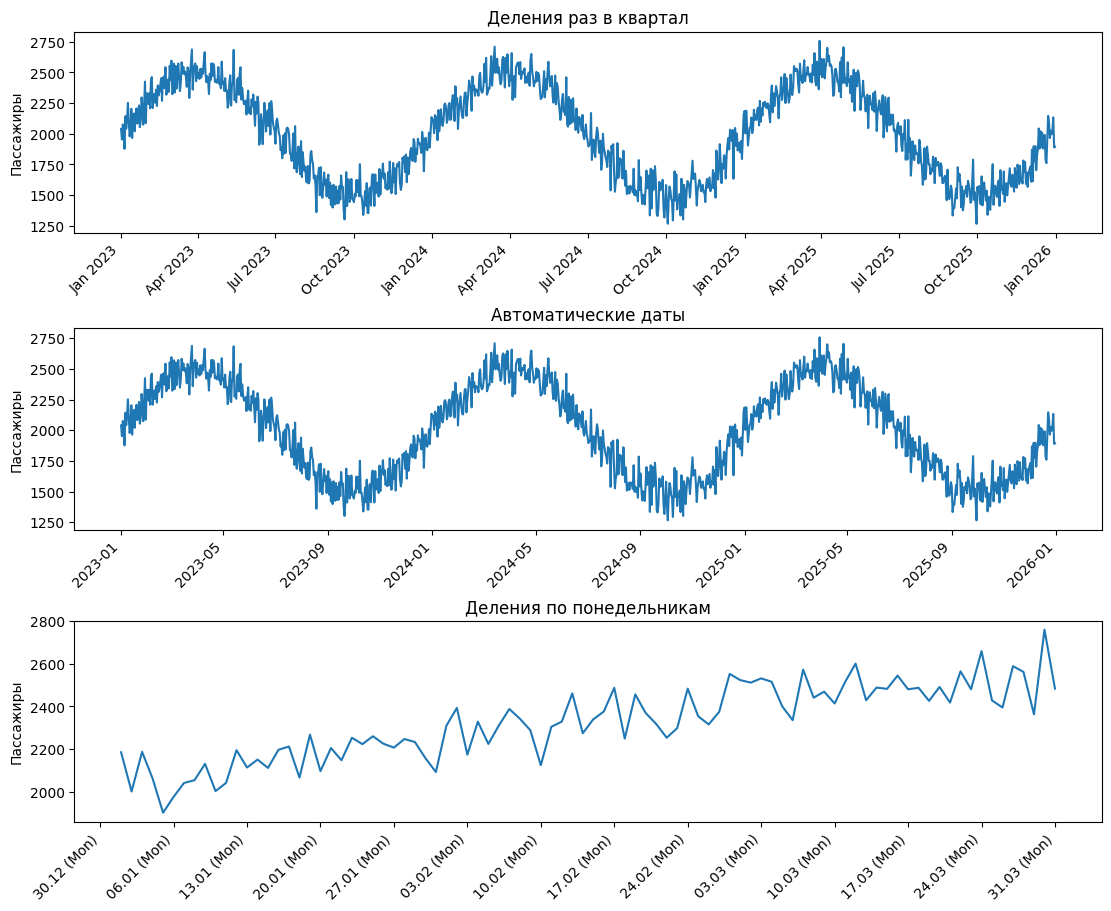

In [ ]:
import matplotlib.dates as mdates

rng = np.random.default_rng(33)
dates = pd.date_range("2023-01-01", "2025-12-31", freq="D")
t = np.arange(len(dates))

df = pd.DataFrame({
    "date": dates,
    "passengers": (
        2000 + 500 * np.sin(2 * np.pi * t / 365.25)
        + rng.normal(0, 100, len(t))
    ).astype(int)
})

df.to_csv("seasonal_passengers.csv", index=False)

df = pd.read_csv(
    "seasonal_passengers.csv",
    parse_dates=["date"],
    index_col="date"
)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), layout="constrained")

# 1. Деления раз в квартал
axes[0].plot(df.index, df["passengers"])
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].set_title("Деления раз в квартал")

# 2. Автоматическое форматирование
axes[1].plot(df.index, df["passengers"])
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.AutoDateFormatter(locator))
axes[1].set_title("Автоматические даты")

# 3. Деления по понедельникам (показаны 3 месяца)
part = df.loc["2025-01":"2025-03"]
axes[2].plot(part.index, part["passengers"])
axes[2].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m (%a)"))
axes[2].set_title("Деления по понедельникам")

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel("Пассажиры")

plt.show()

# Locator определяет, где будут деления, Formatter — как они выглядят.
# Без подходящего Locator подписи могут оказаться слишком частыми.
# parse_dates преобразует строки из CSV в настоящие даты.
# Без parse_dates даты могут восприниматься как строковые категории.
# %b — сокращённое название месяца, %B — полное название.
# AutoDateLocator автоматически выбирает подходящий шаг.
# MonthLocator(interval=12) покажет примерно одно деление в год.
# YearLocator(base=5) создаёт деления через каждые пять лет.

Задача 34 (операционный дашборд аэропорта с twinx + mdates + Formatter). Аэропорт мониторит число рейсов и среднюю пунктуальность для авиавластей. Постройте профессиональный график: (а) число рейсов на ax1 линией; (б) пунктуальность на ax2 = ax1.twinx(); (в) скользящее среднее рейсов df["flights"].rolling(7).mean() на ax1. Настройте ax1.xaxis.set_major_locator(mdates.MonthLocator()), DateFormatter("%b %Y"), ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}")), ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%")). Соберите общую легенду. Ожидаемый вывод: рейсы + SMA(7) на главной оси, пунктуальность на правой, даты по месяцам. В комментариях объясните: зачем rolling(7) (сглаживает дневной шум — недельный тренд); как line на twinx не мешает основной линии (визуальное разделение через цвет); почему цвета (синий/оранжевый) должны быть различимы даже для дальтоников (используйте #1f77b4/#ff7f0e — они хорошо видны); как width=0.8 в bar оставляет зазоры между днями (или width=1 для плотной заливки); как сохранить для веба (dpi=150) и для печати (dpi=300) — разные требования к размеру; что произойдёт без twinx (пунктуальность «схлопнется» на фоне рейсов — шкала 90% vs 500).

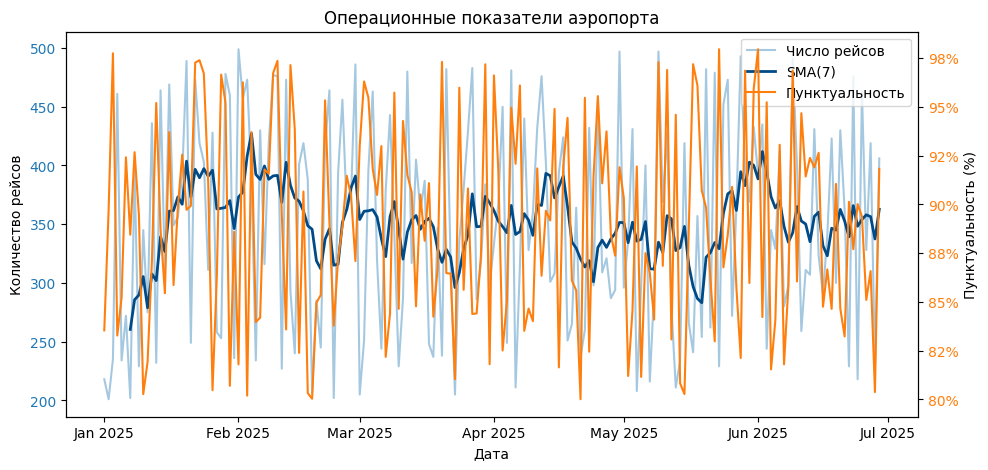

In [ ]:
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

rng = np.random.default_rng(34)
dates = pd.date_range("2025-01-01", periods=180)

df = pd.DataFrame({
    "date": dates,
    "flights": rng.integers(200, 500, len(dates)),
    "punctuality": rng.uniform(80, 98, len(dates))
})

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

# Число рейсов
ax1.plot(
    df["date"], df["flights"],
    color="#1f77b4", alpha=0.4, label="Число рейсов"
)

# Скользящее среднее за 7 дней
ax1.plot(
    df["date"], df["flights"].rolling(7).mean(),
    color="#004b87", linewidth=2, label="SMA(7)"
)

# Пунктуальность
ax2.plot(
    df["date"], df["punctuality"],
    color="#ff7f0e", label="Пунктуальность"
)

ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, p: f"{v:.0f}")
)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, p: f"{v:.0f}%")
)

ax1.tick_params(axis="y", labelcolor="#1f77b4")
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

ax1.set_xlabel("Дата")
ax1.set_ylabel("Количество рейсов")
ax2.set_ylabel("Пунктуальность (%)")
ax1.set_title("Операционные показатели аэропорта")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2)

plt.show()

# rolling(7).mean() сглаживает ежедневные колебания за неделю.
# twinx создаёт вторую ось Y с независимым масштабом.
# Без twinx процентная линия будет плохо различима рядом с рейсами.
# Разные цвета помогают отличать показатели и соответствующие оси.
# #1f77b4 и #ff7f0e — различимые цвета стандартной палитры.
# У bar ширина width=0.8 оставляет зазоры, width=1 уплотняет столбцы.
# Для сохранения веб-версии: fig.savefig("web.png", dpi=150).
# Для печати: fig.savefig("print.png", dpi=300).

Задача 35 (Figure3D — подкласс-обёртка для 3D-сцен). Аэропорт визуализирует 3D-связь дальности рейса, загрузки и расхода топлива (облако точек), а также спираль тренда (если данные позволяют). 3D в Matplotlib создаётся через plt.subplots(subplot_kw={"projection": "3d"}), возвращающий Axes3D. Реализуйте class Figure3D с методами helix(n=200) (спираль через ax.plot(np.cos(t), np.sin(t), t)), cloud(n=500) (облако через ax.scatter(x, y, z, c=z, cmap="viridis", s=20)), view(elev=30, azim=-60) (угол обзора). Постройте спираль и облако, вызовите view(20, -45). Ожидаемый вывод: 3D-сцена с возможностью вращения мышью. В комментариях объясните: зачем класс-обёртка (переиспользование, fluent API); как projection="3d" создаёт Axes3D — подкласс обычного Axes; что делает view_init(elev, azim) (углы обзора: elev — подъём 0–90°, azim — поворот 0–360°); как depthshade=True (по умолчанию) затемняет дальние точки, создавая иллюзию глубины; почему 3D сложнее читать, чем 2D (перспективные искажения, перекрытия — лучше комбинировать с проекциями); что произойдёт при сохранении 3D-графика в PNG (схлопнется в текущий ракурс — вращение возможно только интерактивно).

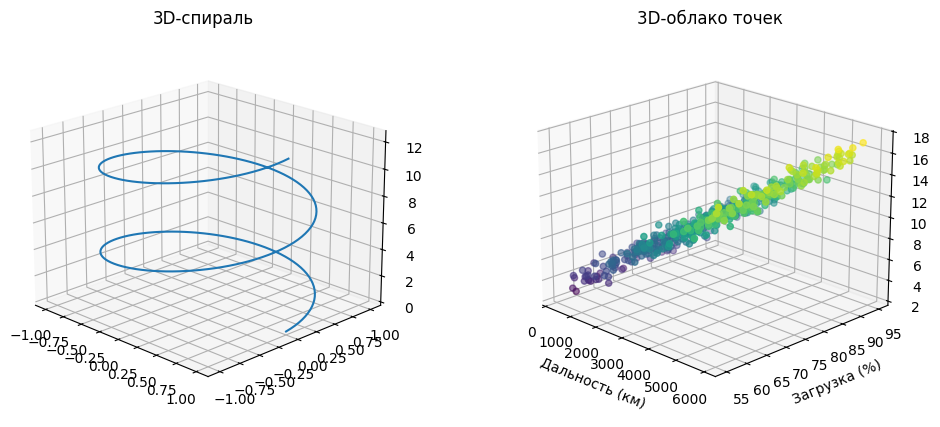

In [ ]:
class Figure3D:
    def __init__(self):
        self.fig, (self.ax1, self.ax2) = plt.subplots(
            1, 2,
            figsize=(12, 5),
            subplot_kw={"projection": "3d"}
        )

    def helix(self, n=200):
        t = np.linspace(0, 4 * np.pi, n)

        self.ax1.plot(np.cos(t), np.sin(t), t)
        self.ax1.set_title("3D-спираль")
        return self

    def cloud(self, n=500):
        rng = np.random.default_rng(35)

        x = rng.uniform(300, 6000, n)
        y = rng.uniform(55, 95, n)
        z = 0.002 * x + 0.05 * y + rng.normal(0, 0.6, n)

        self.ax2.scatter(
            x, y, z,
            c=z,
            cmap="viridis",
            s=20,
            depthshade=True
        )

        self.ax2.set_xlabel("Дальность (км)")
        self.ax2.set_ylabel("Загрузка (%)")
        self.ax2.set_zlabel("Топливо (т)")
        self.ax2.set_title("3D-облако точек")
        return self

    def view(self, elev=30, azim=-60):
        self.ax1.view_init(elev=elev, azim=azim)
        self.ax2.view_init(elev=elev, azim=azim)
        return self


scene = Figure3D().helix().cloud().view(20, -45)

plt.show()

# Класс Figure3D объединяет создание и настройку 3D-графиков.
# return self позволяет вызывать методы цепочкой (fluent API).
# projection="3d" создаёт Axes3D — специальный подкласс Axes.
# view_init задаёт угол обзора: elev — подъём, azim — поворот.
# depthshade=True затемняет дальние точки и создаёт эффект глубины.
# 3D сложнее читать из-за перспективы и перекрытия объектов.
# Поэтому его иногда дополняют двумерными проекциями.
# PNG сохраняет только текущий ракурс без возможности вращения.

Задача 36 (3D-поверхность с проекцией контуров). Аэропорт моделирует задержку как функцию ветра и видимости. Визуализируйте поверхность Z = np.sin(np.sqrt(X**2 + Y**2)) (волновая — имитация колебаний задержки). Постройте два подграфика в 3D: (а) ax.plot_surface(X, Y, Z, cmap="viridis", linewidth=0, antialiased=True, rstride=2, cstride=2, alpha=0.9) + ax.contour(X, Y, Z, zdir="z", offset=-1.5, levels=15, cmap="viridis") — проекция контуров на «пол»; (б) та же поверхность, но zdir="x", offset=-5 — проекция на боковую «стену». Настройте ax.set_box_aspect((1, 1, 0.6)). Ожидаемый вывод: поверхность с контурами на «полу» (или «стене»). В комментариях объясните: зачем antialiased=True (сглаживает грани — без него «рваный» вид); как rstride=2, cstride=2 уменьшают число полигонов в 4 раза (ускоряет отрисовку ценой детализации); что делает zdir/offset (выбор плоскости проекции и её сдвиг); почему set_box_aspect((1, 1, 0.6)) улучшает восприятие (стандартная 1:1:1 «растягивает» Z); что произойдёт при plot_surface 1000×1000 (медленно — стоит rstride=4); как комбинация поверхности + контуров даёт максимум информации (форма + числовые значения).

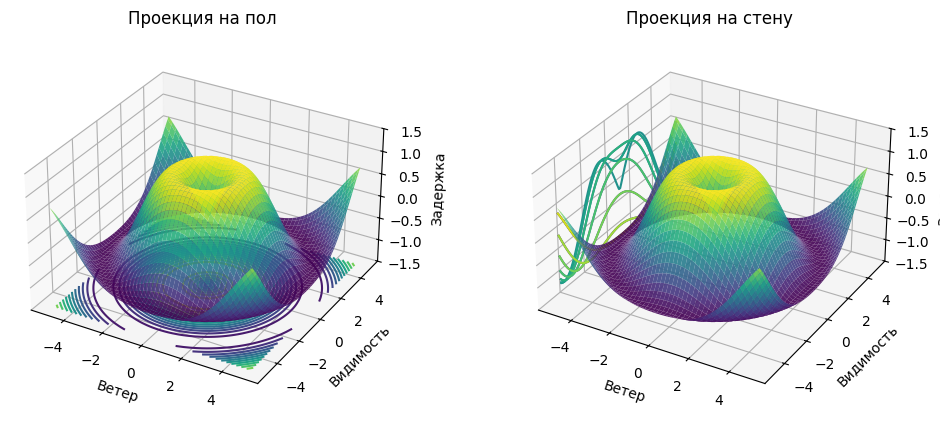

In [ ]:
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    subplot_kw={"projection": "3d"}
)

# Первый график — проекция на пол
axes[0].plot_surface(
    X, Y, Z,
    cmap="viridis",
    linewidth=0,
    antialiased=True,
    rstride=2,
    cstride=2,
    alpha=0.9
)

axes[0].contour(
    X, Y, Z,
    zdir="z",
    offset=-1.5,
    levels=15,
    cmap="viridis"
)

# Второй график — проекция на стену
axes[1].plot_surface(
    X, Y, Z,
    cmap="viridis",
    linewidth=0,
    antialiased=True,
    rstride=2,
    cstride=2,
    alpha=0.9
)

axes[1].contour(
    X, Y, Z,
    zdir="x",
    offset=-5,
    levels=15,
    cmap="viridis"
)

for ax in axes:
    ax.set_box_aspect((1, 1, 0.6))
    ax.set_zlim(-1.5, 1.5)
    ax.set_xlabel("Ветер")
    ax.set_ylabel("Видимость")
    ax.set_zlabel("Задержка")

axes[0].set_title("Проекция на пол")
axes[1].set_title("Проекция на стену")

plt.show()

# antialiased=True сглаживает края поверхности.
# rstride=2 и cstride=2 пропускают строки и столбцы сетки.
# Это примерно в 4 раза уменьшает число полигонов.
# zdir выбирает ось, перпендикулярную плоскости проекции.
# offset определяет положение плоскости с контурами.
# set_box_aspect((1, 1, 0.6)) уменьшает визуальный масштаб Z.
# Сетка 1000×1000 рисуется медленнее; можно увеличить stride до 4.
# Поверхность показывает форму, а контуры — уровни значений.

Задача 37 (confusion matrix из sklearn.metrics). Аэропорт обучил классификатор, который предсказывает статус рейса (3 класса: «вовремя», «задержан», «отменён»). Матрица ошибок покажет, где модель путается. Постройте cm = confusion_matrix(y_test, y_pred) и cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True), визуализируйте через imshow(cm, cmap="Blues") с аннотациями for i, j in np.ndindex(cm.shape): ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black"). Ожидаемый вывод: две матрицы — абсолютная и нормированная. В комментариях объясните: почему строки — истина, столбцы — предсказание (не путайте — это критично); зачем нормализация при дисбалансе (если «вовремя» 85%, абсолютные числа вводят в заблуждение); как ax.text(j, i) соответствует imshow (координаты (x, y), где x — столбец); что показывает диагональ (правильные предсказания — чем ярче, тем лучше); как добавить accuracy, precision, recall, F1 в заголовок (f"Acc={acc:.2f}, F1={f1:.2f}"); что произойдёт при 10 классах (аннотации станут мелкими — используйте plt.cm.Blues без текста).



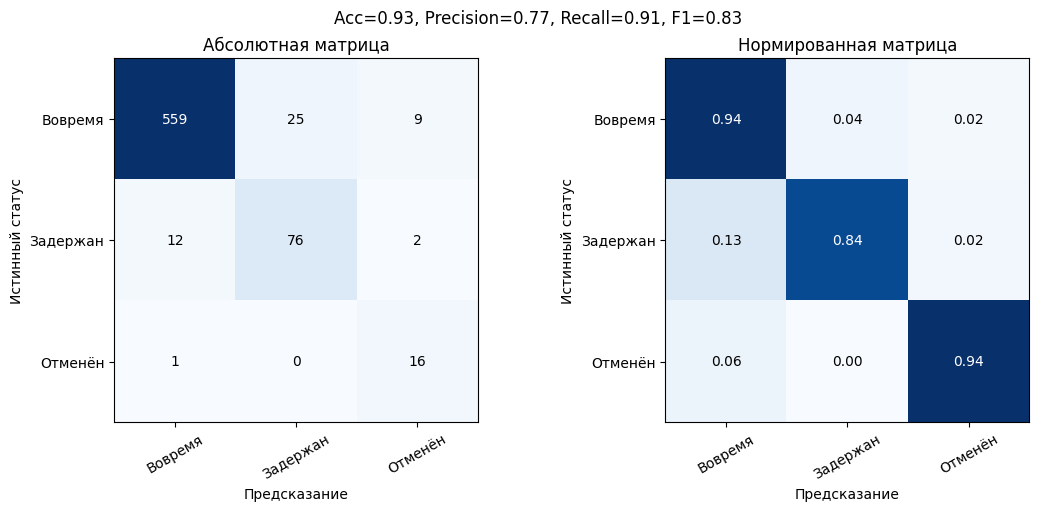

In [ ]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

rng = np.random.default_rng(37)

# 0 — вовремя, 1 — задержан, 2 — отменён
y_test = rng.choice(3, size=700, p=[0.85, 0.12, 0.03])
y_pred = y_test.copy()

# Имитация ошибок классификатора
errors = rng.random(700) < 0.17
y_pred[errors] = rng.choice(
    3, size=errors.sum(), p=[0.75, 0.20, 0.05]
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")

names = ["Вовремя", "Задержан", "Отменён"]

for ax, values, title in zip(
    axes,
    [cm, cm_norm],
    ["Абсолютная матрица", "Нормированная матрица"]
):
    im = ax.imshow(values, cmap="Blues")

    for i, j in np.ndindex(cm.shape):
        label = f"{values[i, j]:.2f}" if title.startswith("Норм") else str(values[i, j])

        ax.text(
            j, i, label,
            ha="center",
            va="center",
            color="white" if values[i, j] > values.max() / 2 else "black"
        )

    ax.set_xticks(range(3), names, rotation=30)
    ax.set_yticks(range(3), names)
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истинный статус")
    ax.set_title(title)

fig.suptitle(
    f"Acc={acc:.2f}, Precision={precision:.2f}, "
    f"Recall={recall:.2f}, F1={f1:.2f}"
)

plt.show()

# Строки матрицы — истинные классы, столбцы — предсказанные.
# Диагональ показывает правильные предсказания.
# Нормализация по строкам помогает сравнивать редкие и частые классы.
# ax.text(j, i) использует координаты x=столбец, y=строка.
# Accuracy — общая доля правильных ответов.
# Precision — точность положительных предсказаний.
# Recall — доля найденных объектов нужного класса.
# F1 объединяет Precision и Recall.
# При 10+ классах подписи могут стать мелкими — лучше оставить цвета.

Задача 38 (ROC, PR и калибровочная кривая). Аэропорт обучает модель предсказания отмены рейса на сильно несбалансированных данных (97% рейсов выполняются, 3% отменяются). ROC может «обмануть», PR честнее, калибровка показывает, можно ли доверять вероятностям. Обучите LogisticRegression на make_classification(weights=[0.97, 0.03]), получите y_proba = model.predict_proba(X_test)[:, 1]. Постройте три подграфика: (а) ROC (fpr, tpr, _ = roc_curve(...); auc = roc_auc_score(...)); (б) PR (precision, recall, _ = precision_recall_curve(...); ap = average_precision_score(...) с ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Baseline")); (в) калибровка (prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10) с диагональю ax.plot([0, 1], [0, 1], "k--")). Ожидаемый вывод: три кривые с метриками в легенде. В комментариях объясните: что такое TPR и FPR (чувствительность и доля ложных срабатываний); почему PR лучше ROC при дисбалансе (ROC «смотрит» и на TN, которых 97%, и картина кажется хорошей даже для плохой модели); что означает AUC = 0.5 (случайное угадывание — диагональ); как калибровочная кривая выявляет «самоуверенную» модель (точки ниже диагонали — предсказанные вероятности выше реальных); как average_precision_score связан с площадью PR; что произойдёт при перевёрнутых метках классов (AUC станет 1 - AUC, ROC «перевернётся»).

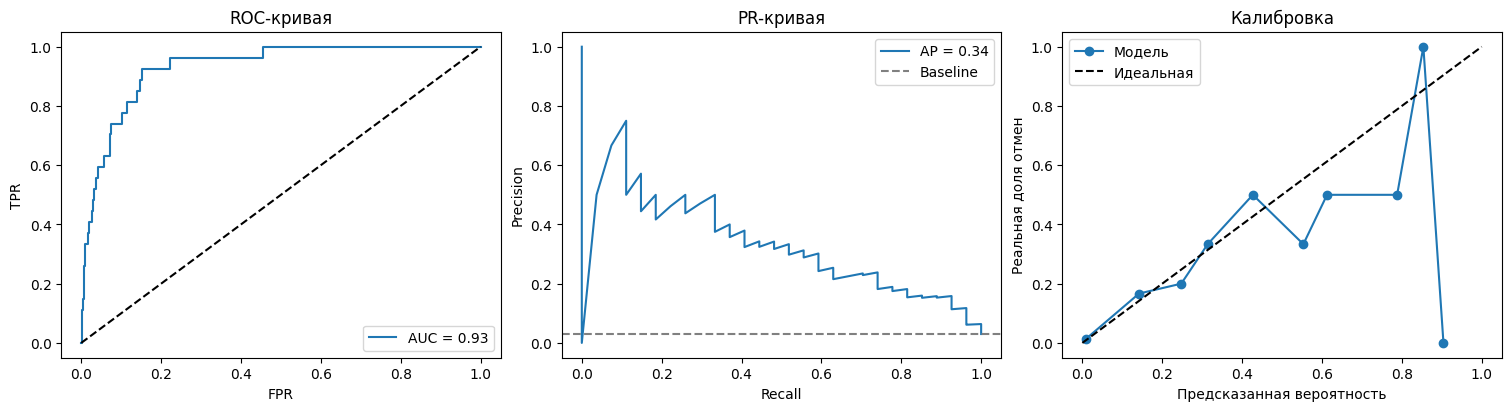

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)
from sklearn.calibration import calibration_curve

X, y = make_classification(
    n_samples=3000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    weights=[0.97, 0.03],
    flip_y=0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

precision, recall, _ = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

prob_true, prob_pred = calibration_curve(
    y_test, y_proba, n_bins=10
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

# ROC
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.2f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend()

# Precision-Recall
axes[1].plot(recall, precision, label=f"AP = {ap:.2f}")
axes[1].axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label="Baseline"
)
axes[1].set_title("PR-кривая")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

# Калибровочная кривая
axes[2].plot(prob_pred, prob_true, "o-", label="Модель")
axes[2].plot([0, 1], [0, 1], "k--", label="Идеальная")
axes[2].set_title("Калибровка")
axes[2].set_xlabel("Предсказанная вероятность")
axes[2].set_ylabel("Реальная доля отмен")
axes[2].legend()

plt.show()

# TPR — доля правильно обнаруженных отмен (чувствительность).
# FPR — доля выполненных рейсов, ошибочно названных отменёнными.
# PR особенно полезна при редких отменах, так как учитывает
# влияние ложных срабатываний на Precision.
# ROC AUC=0.5 соответствует качеству случайного ранжирования.
# AP обобщает Precision на разных уровнях Recall.
# На калибровке точки ниже диагонали означают завышение вероятностей.
# Если поменять только истинные метки 0 и 1, сохранив оценки,
# ROC AUC станет 1 - прежний AUC.
# При одновременном перевороте меток и вероятностей AUC сохранится.

Задача 39 (learning curves и диагностика переобучения). Аэропорт обучает модель прогноза задержек на исторических данных, но нужно понять, хватит ли данных и не переобучается ли модель. Кривые обучения показывают, как accuracy меняется с ростом обучающей выборки. Обучите три модели: простая DecisionTree(max_depth=3) (недообучение), сложная DecisionTree(max_depth=20) (переобучение), RandomForest (хорошая). Для каждой вызовите learning_curve(model, X, y, train_sizes=np.linspace(0.1, 1.0, 10), cv=5, scoring="accuracy", n_jobs=-1) и постройте train/val с fill_between(mean ± std). Ожидаемый вывод: 3 learning curves с диагнозами. В комментариях объясните: как диагностировать переобучение (train высоко, val низко — большой gap); недообучение (обе кривые низко — модель слишком простая); «хорошую» модель (кривые сходятся около 0.9+); что показывает заливка fill_between (стандартное отклонение по фолдам — стабильность); когда нужно собирать больше данных (обе кривые ещё растут); что произойдёт при train_sizes=[1.0] (одна точка — график неинформативен); почему cv=5 (5 фолдов дают разумный баланс скорости и стабильности).

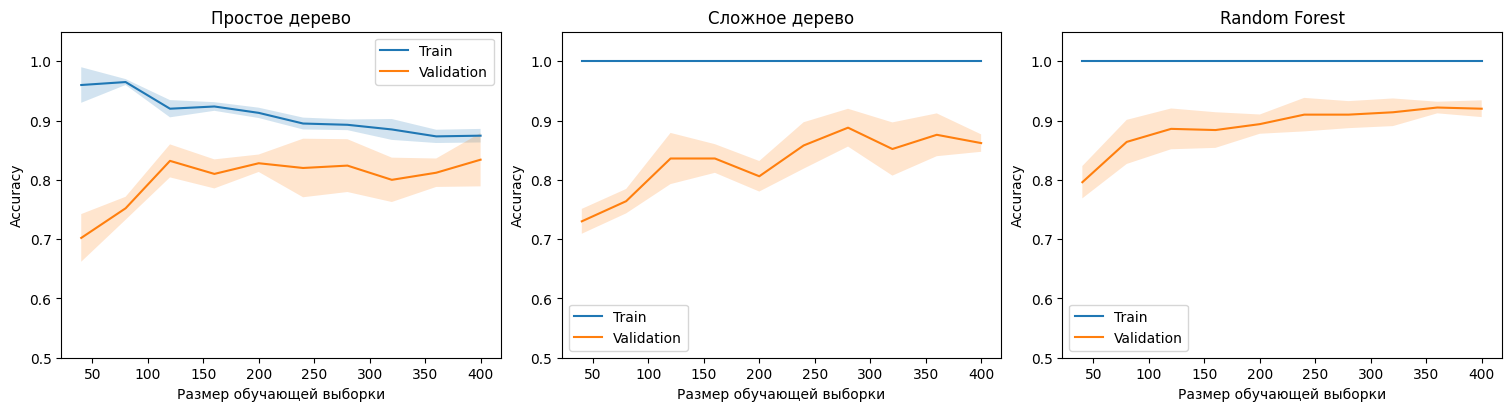

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(
    n_samples=500,
    n_features=12,
    n_informative=8,
    n_redundant=2,
    class_sep=1.6,
    flip_y=0.03,
    random_state=42
)

models = [
    DecisionTreeClassifier(max_depth=3, random_state=42),
    DecisionTreeClassifier(max_depth=20, random_state=42),
    RandomForestClassifier(n_estimators=50, random_state=42)
]

titles = ["Простое дерево", "Сложное дерево", "Random Forest"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

for ax, model, title in zip(axes, models, titles):
    sizes, train_scores, val_scores = learning_curve(
        model,
        X, y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)

    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    ax.plot(sizes, train_mean, label="Train")
    ax.plot(sizes, val_mean, label="Validation")

    ax.fill_between(
        sizes, train_mean - train_std, train_mean + train_std,
        alpha=0.2
    )

    ax.fill_between(
        sizes, val_mean - val_std, val_mean + val_std,
        alpha=0.2
    )

    ax.set_title(title)
    ax.set_xlabel("Размер обучающей выборки")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.5, 1.05)
    ax.legend()

plt.show()

# При переобучении Train высокий, а Validation заметно ниже.
# При недообучении оба показателя сравнительно низкие.
# Хорошая модель имеет высокие и близкие Train и Validation.
# fill_between показывает разброс оценок между фолдами.
# Если Validation продолжает расти, больше данных может помочь.
# train_sizes=[1.0] дал бы только одну точку вместо кривой.
# cv=5 означает оценивание на пяти разбиениях данных.
# Это компромисс между скоростью и стабильностью оценки.

Задача 40 (training curves и ранняя остановка). Аэропорт обучает нейросеть для прогноза задержек. По кривым обучения видно, когда модель начинает переобучаться. Смоделируйте историю 50 эпох: train_loss = 1.5 * np.exp(-epochs/15) + 0.1 + np.random.randn(50)*0.02, val_loss = 1.5 * np.exp(-epochs/15) + 0.15 + np.random.randn(50)*0.03, начиная с 25-й эпохи добавьте val_loss[25:] += (epochs[25:] - 25) * 0.01 (имитация переобучения). Постройте два подграфика: loss и accuracy (1 - loss/2). Найдите best_epoch = np.argmin(val_loss) + 1, добавьте ax.axvline(best_epoch, color="green", linestyle="--", label=f"Best = {best_epoch}") и ax.annotate("Начало переобучения", xy=(best_epoch, val_loss[best_epoch-1]), xytext=(best_epoch+5, val_loss[best_epoch-1]+0.3), arrowprops=dict(arrowstyle="->", color="green")). Ожидаемый вывод: loss падает, val растёт после 25-й эпохи; best-эпоха отмечена. В комментариях объясните: почему loss падает, а val растёт (переобучение — модель «запоминает» шум); что такое early stopping (остановка на best_epoch — оптимум валидации); как argmin находит лучшую эпоху и почему + 1 (эпохи начинаются с 1); что делать при взрыве loss (уменьшить learning rate, добавить регуляризацию); зачем логировать метрики в history = {"train_loss": [], "val_loss": [], ...} и строить после (history["train_loss"].append(...)); что произойдёт при argmin на пустом массиве (ValueError).

Лучшая эпоха: 36


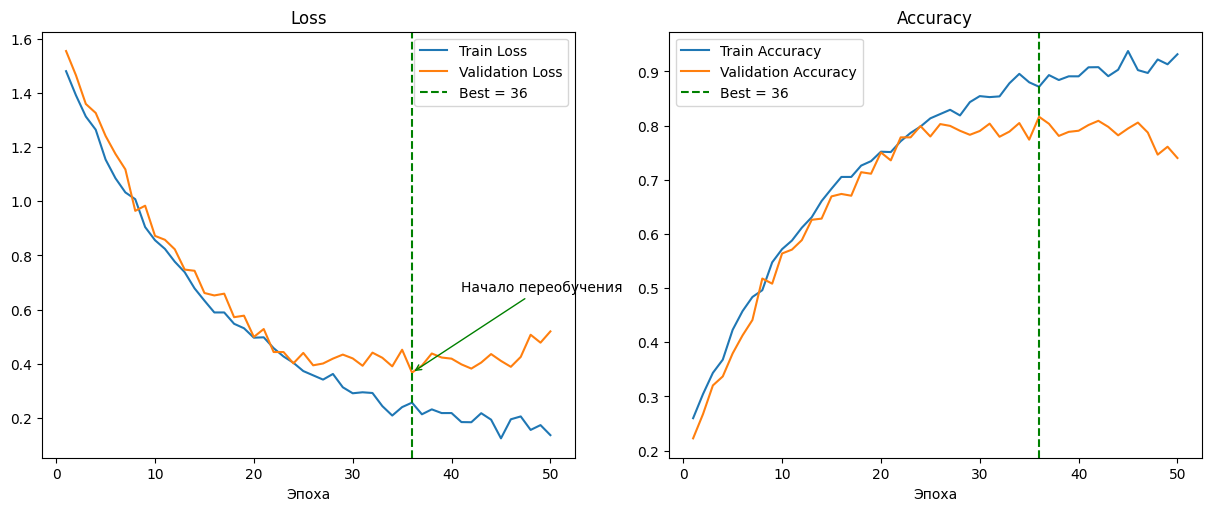

In [ ]:
rng = np.random.default_rng(40)
epochs = np.arange(1, 51)

train_loss = (
    1.5 * np.exp(-epochs / 15)
    + 0.1 + rng.normal(0, 0.02, 50)
)

val_loss = (
    1.5 * np.exp(-epochs / 15)
    + 0.15 + rng.normal(0, 0.03, 50)
)

# Имитация переобучения после 25-й эпохи
val_loss[25:] += (epochs[25:] - 25) * 0.01

train_acc = 1 - train_loss / 2
val_acc = 1 - val_loss / 2

best_epoch = np.argmin(val_loss) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

# График потерь
axes[0].plot(epochs, train_loss, label="Train Loss")
axes[0].plot(epochs, val_loss, label="Validation Loss")

axes[0].axvline(
    best_epoch, color="green",
    linestyle="--", label=f"Best = {best_epoch}"
)

axes[0].annotate(
    "Начало переобучения",
    xy=(best_epoch, val_loss[best_epoch - 1]),
    xytext=(best_epoch + 5, val_loss[best_epoch - 1] + 0.3),
    arrowprops=dict(arrowstyle="->", color="green")
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Эпоха")
axes[0].legend()

# График точности
axes[1].plot(epochs, train_acc, label="Train Accuracy")
axes[1].plot(epochs, val_acc, label="Validation Accuracy")

axes[1].axvline(
    best_epoch, color="green",
    linestyle="--", label=f"Best = {best_epoch}"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].legend()

print("Лучшая эпоха:", best_epoch)

plt.show()

# Loss измеряет ошибку модели, Accuracy — долю правильных ответов.
# Если Train Loss падает, а Validation Loss растёт, модель переобучается.
# Early stopping останавливает обучение около лучшей эпохи валидации.
# argmin находит индекс минимального Validation Loss.
# +1 нужен, потому что индексы начинаются с 0, а эпохи — с 1.
# При резком росте Loss можно уменьшить learning rate
# или добавить регуляризацию.
# Метрики удобно сохранять в history["train_loss"].append(value).
# Затем history используют для построения графиков.
# np.argmin на пустом массиве вызовет ValueError.

Задача 41 (feature importance: MDI vs permutation). Аэропорт обучил RandomForest для прогноза задержек, и нужно понять, какие признаки важнее всего — это поможет в операционном планировании. У RandomForest есть встроенная MDI-importance (model.feature_importances_), но она завышает важность категориальных признаков с высокой кардинальностью (например, «направление» с 100 уникальными значениями). Permutation importance надёжнее — измеряет падение метрики при перемешивании. Постройте barh с двумя сериями: MDI (pd.Series(model.feature_importances_, index=names).sort_values()) и permutation (permutation_importance(model, X, y, n_repeats=10).importances_mean). Ожидаемый вывод: два barh рядом; MDI и permutation могут расходиться. В комментариях объясните: чем MDI отличается от permutation (MDI — по «нечистоте» узлов; permutation — по падению метрики на holdout); зачем n_repeats=10 (усреднение по случайным перемешиваниям — уменьшает дисперсию); почему barh удобнее для длинных имён признаков ("скорость_ветра_на_взлёте" не влезает под bar); как plt.cm.viridis(imp / imp.max()) создаёт градиент (важные — яркие, неважные — тёмные); что показывает «важность = 0.15» (признак объясняет 15% «важности» — но это не 15% точности); какие альтернативы (SHAP, permutation_importance с scoring="roc_auc" вместо accuracy).

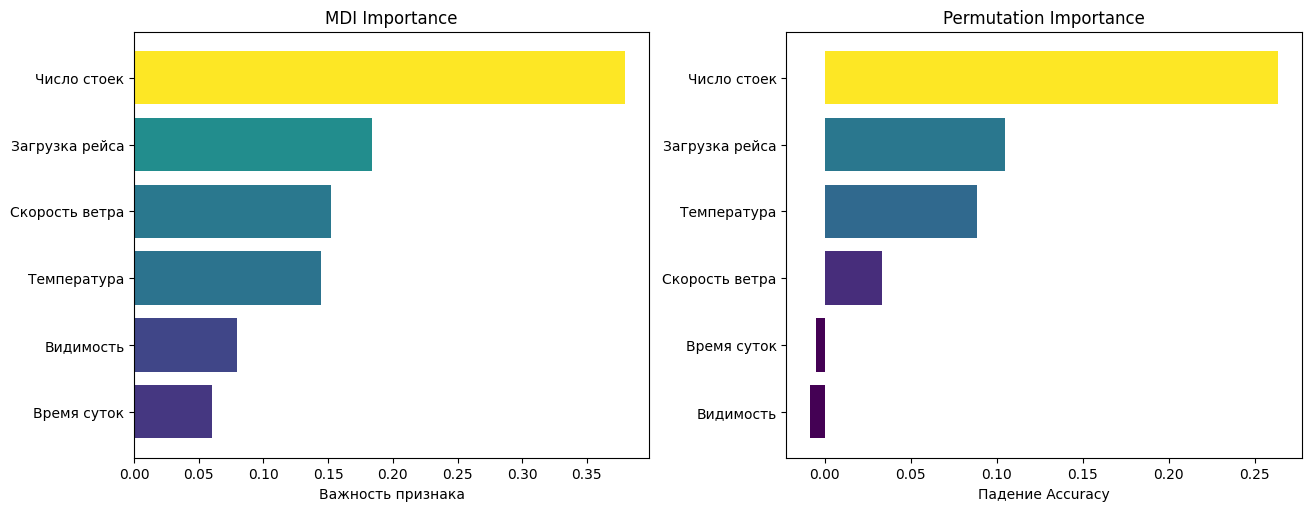

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

names = [
    "Загрузка рейса",
    "Скорость ветра",
    "Видимость",
    "Число стоек",
    "Время суток",
    "Температура"
]

X, y = make_classification(
    n_samples=800,
    n_features=6,
    n_informative=4,
    n_redundant=0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = RandomForestClassifier(
    n_estimators=70,
    random_state=42
)

model.fit(X_train, y_train)

# MDI importance
mdi = pd.Series(
    model.feature_importances_,
    index=names
).sort_values()

# Permutation importance
perm = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

perm_imp = pd.Series(
    perm.importances_mean,
    index=names
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

axes[0].barh(
    mdi.index,
    mdi.values,
    color=plt.cm.viridis(mdi.values / mdi.max())
)

axes[0].set_title("MDI Importance")
axes[0].set_xlabel("Важность признака")

axes[1].barh(
    perm_imp.index,
    perm_imp.values,
    color=plt.cm.viridis(np.clip(perm_imp.values / perm_imp.max(), 0, 1))
)

axes[1].set_title("Permutation Importance")
axes[1].set_xlabel("Падение Accuracy")

plt.show()

# MDI оценивает важность по уменьшению нечистоты узлов деревьев.
# MDI может завышать важность признаков с большим числом значений.
# Permutation измеряет снижение качества при перемешивании признака.
# Её лучше рассчитывать на проверочных данных, а не обучающих.
# n_repeats=10 усредняет результат десяти перемешиваний.
# barh удобен для длинных названий признаков.
# plt.cm.viridis(imp / imp.max()) задаёт градиент цветов.
# MDI=0.15 означает 15% суммарной важности MDI, не 15% Accuracy.
# Для оценки можно использовать SHAP или permutation с roc_auc.

Задача 42 (heatmap z-score с кастомной аннотацией). Аэропорт анализирует матрицу «терминал × месяц» с числом рейсов, но масштабы разные (Терминал B — сотни, Терминал D — десятки), поэтому нужно стандартизовать данные. Вычислите z = (df - df.mean()) / df.std() (по столбцам), постройте im = ax.imshow(z, cmap="RdBu_r", vmin=-3, vmax=3) с cbar = fig.colorbar(im); cbar.ax.axhline(0, color="black"). Для ячеек с |z| > 2 (статистические аномалии) добавьте аннотации: ax.text(j, i, f"{z.iloc[i, j]:.1f}", color="white", fontsize=8, bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.5)). Ожидаемый вывод: heatmap, где ярко-красные/синие ячейки — аномалии; остальные — нейтральны. В комментариях объясните: зачем стандартизация (сравнение разных масштабов — «аномально высокий» для Терминала D ≠ «аномально высокий» для Терминала B); почему RdBu_r (инвертированный — привычный «красный = высокий»); как bbox делает аннотации читаемыми на цветном фоне; как скрыть аннотации в маленьких ячейках (например, if abs(z.iloc[i, j]) > 2 and z.shape[0] * z.shape[1] < 100); зачем cbar.ax.axhline(0) (опорная линия нуля); что произойдёт при vmin=-3, vmax=3 на данных с диапазоном ±10 (всё за пределами обрежется до крайних цветов).

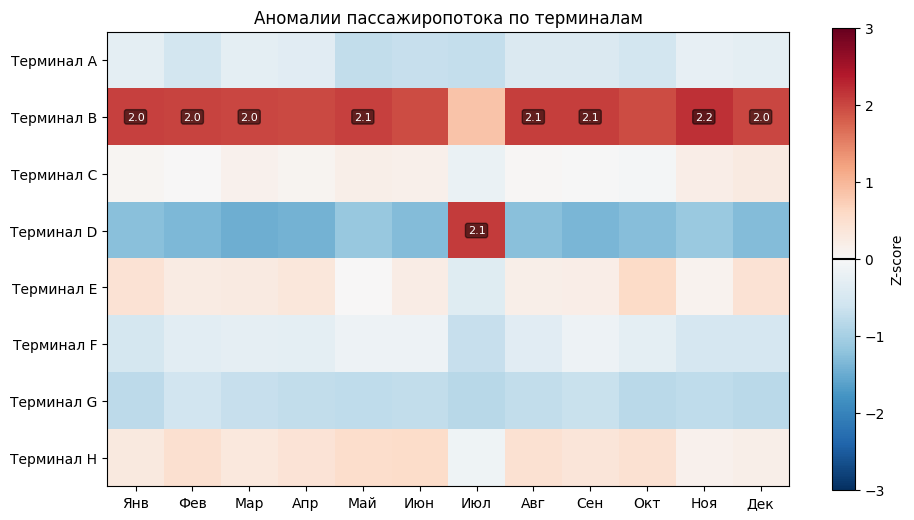

In [ ]:
rng = np.random.default_rng(42)

months = [
    "Янв", "Фев", "Мар", "Апр", "Май", "Июн",
    "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"
]

terminals = [f"Терминал {x}" for x in "ABCDEFGH"]

base = np.array([120, 320, 160, 45, 175, 130, 95, 190])

df = pd.DataFrame(
    np.maximum(
        0,
        base[:, None] + rng.normal(0, 15, (8, 12))
    ).astype(int),
    index=terminals,
    columns=months
)

# Аномальное значение
df.loc["Терминал D", "Июл"] = 500

# Стандартизация по столбцам
z = (df - df.mean()) / df.std()

fig, ax = plt.subplots(figsize=(11, 6))

im = ax.imshow(
    z,
    cmap="RdBu_r",
    vmin=-3,
    vmax=3
)

cbar = fig.colorbar(im, ax=ax, label="Z-score")
cbar.ax.axhline(0, color="black")

ax.set_xticks(range(len(months)), months)
ax.set_yticks(range(len(terminals)), terminals)

# Подписываем аномалии
for i, j in np.ndindex(z.shape):
    if abs(z.iloc[i, j]) > 2 and z.size < 100:
        ax.text(
            j, i,
            f"{z.iloc[i, j]:.1f}",
            ha="center",
            va="center",
            color="white",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="black",
                alpha=0.5
            )
        )

ax.set_title("Аномалии пассажиропотока по терминалам")

plt.show()

# Z-score показывает отклонение от среднего в единицах std.
# Стандартизация помогает сравнивать значения разных масштабов.
# Формула здесь стандартизует столбцы, то есть отдельно каждый месяц.
# Для поиска аномалий внутри одного терминала нужна стандартизация
# по строкам, иначе различия между терминалами сохраняют влияние.
# RdBu_r — расходящаяся палитра: красный обозначает высокие значения.
# bbox улучшает видимость подписей поверх цветных ячеек.
# Условие z.size < 100 не даёт перегружать маленькие ячейки текстом.
# cbar.ax.axhline(0) отмечает нулевой уровень на цветовой шкале.
# vmin=-3, vmax=3 фиксируют диапазон цветов.
# Значения за пределами этого диапазона получат крайние цвета.

In [ ]:
# Включаем интерактивные графики в Google Colab

%pip install -q -U ipympl

from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np

Задача 43 (Slider с PlotState-датаклассом). Аэропорт проводит интерактивную демонстрацию для авиавластей: покажите, как меняется прогноз пассажиропотока при разных темпах роста и сезонных коэффициентах. Интерактивные виджеты превращают статичный график в панель управления. Реализуйте @dataclass class PlotState: growth: float = 0.05; seasonality: float = 0.2 и два Slider — «темп роста» (0.01–0.20) и «сезонность» (0.0–1.0). В callback def update(_): state.growth = slider_growth.val; state.seasonality = slider_season.val; y = base * (1 + state.growth) ** months * (1 + state.seasonality * np.sin(2 * np.pi * months / 12)); line.set_ydata(y); fig.canvas.draw_idle(). Расположите слайдеры через fig.subplots_adjust(bottom=0.25) и fig.add_axes([0.15, 0.15, 0.7, 0.03]) (и второй на [0.15, 0.05, ...]). Ожидаемый вывод: слайдеры внизу, график перестраивается в реальном времени. В комментариях объясните: зачем PlotState (отделить состояние от вида — упрощает тестирование); почему обязательно fig.canvas.draw_idle() (без него данные обновятся, но график не перерисуется); что произойдёт без subplots_adjust (слайдеры перекроют график); как blitting ускоряет перерисовку (перерисовывается только линия, а не вся фигура); как valfmt="%.2f" форматирует отображение значения (0.05 → "0.05"); что будет при valstep=0.01 (значения квантуются — удобно для «шага 1%»).

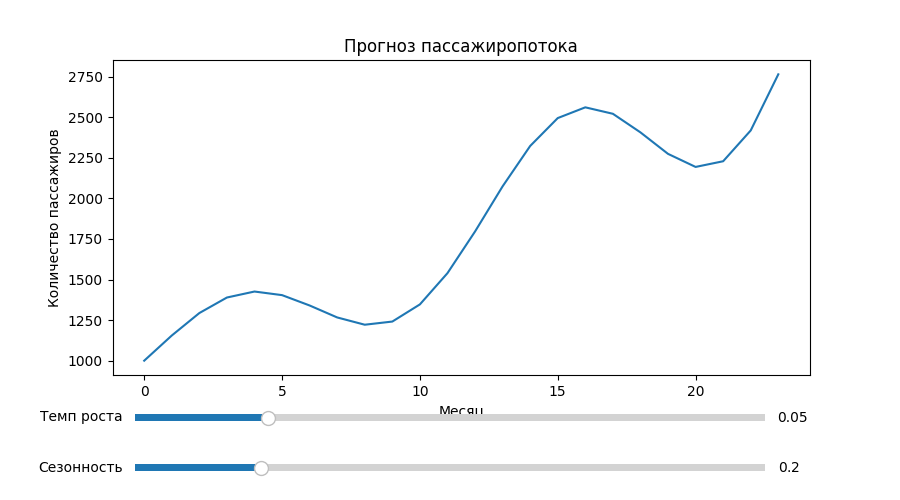

In [ ]:
from dataclasses import dataclass
from matplotlib.widgets import Slider

@dataclass
class PlotState:
    growth: float = 0.05
    seasonality: float = 0.2

state = PlotState()

months = np.arange(24)
base = 1000

y = base * (1 + state.growth) ** months * (
    1 + state.seasonality * np.sin(2 * np.pi * months / 12)
)

fig, ax = plt.subplots(figsize=(9, 5))
fig.subplots_adjust(bottom=0.25)

line, = ax.plot(months, y)

ax.set_title("Прогноз пассажиропотока")
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество пассажиров")

# Слайдер темпа роста
slider_growth = Slider(
    fig.add_axes([0.15, 0.15, 0.7, 0.03]),
    "Темп роста",
    0.01, 0.20,
    valinit=state.growth,
    valfmt="%.2f",
    valstep=0.01
)

# Слайдер сезонности
slider_season = Slider(
    fig.add_axes([0.15, 0.05, 0.7, 0.03]),
    "Сезонность",
    0.0, 1.0,
    valinit=state.seasonality
)

def update(_):
    state.growth = slider_growth.val
    state.seasonality = slider_season.val

    y = base * (1 + state.growth) ** months * (
        1 + state.seasonality * np.sin(2 * np.pi * months / 12)
    )

    line.set_ydata(y)
    ax.relim()
    ax.autoscale_view()
    fig.canvas.draw_idle()

slider_growth.on_changed(update)
slider_season.on_changed(update)

plt.show()

# PlotState хранит состояние отдельно от отображения графика.
# Это удобно для изменения параметров и тестирования.
# on_changed вызывает update при перемещении слайдера.
# set_ydata обновляет значения линии.
# draw_idle запускает перерисовку в интерактивном режиме.
# Без subplots_adjust слайдеры могут перекрыть график.
# blitting ускоряет обновление, перерисовывая только нужные объекты.
# valfmt="%.2f" показывает значения с двумя знаками после точки.
# valstep=0.01 ограничивает изменение шагом 0.01 (1 п.п.).

Задача 44 (Button, RadioButtons, CheckButtons в одном дашборде). Аэропорт показывает авиавластям интерактивный дашборд с 4 виджетами: слайдер темпа роста, радио-кнопки для выбора терминала (B / D / E), чекбоксы для включения/отключения сетки и легенды, кнопка «Сброс». Реализуйте class InteractivePlot с методами _update, _change_terminal, _toggle_grid, _reset. Используйте RadioButtons.on_clicked(callback) (принимает метку выбранного варианта), CheckButtons.on_clicked(callback) (принимает метку кликнутого флажка), Button.on_clicked(callback) (принимает event, но обычно игнорируется). Ожидаемый вывод: 4 виджета работают совместно; кнопка сброса возвращает исходные значения. В комментариях объясните: чем RadioButtons отличается от CheckButtons (первый — один активный, второй — много независимых); как Button.on_clicked(callback) отличается от Slider.on_changed(callback) (первый по клику, второй при изменении); зачем хранить ссылки на виджеты (self.slider = Slider(...) — иначе GC удалит); как set_active(index) у RadioButtons программно выбирает вариант; почему activecolor улучшает UX (выделяет активный вариант); что произойдёт при двух активных RadioButtons (это не «галочки», нельзя выбрать два — попытка вызовет set_active и сбросит первый).

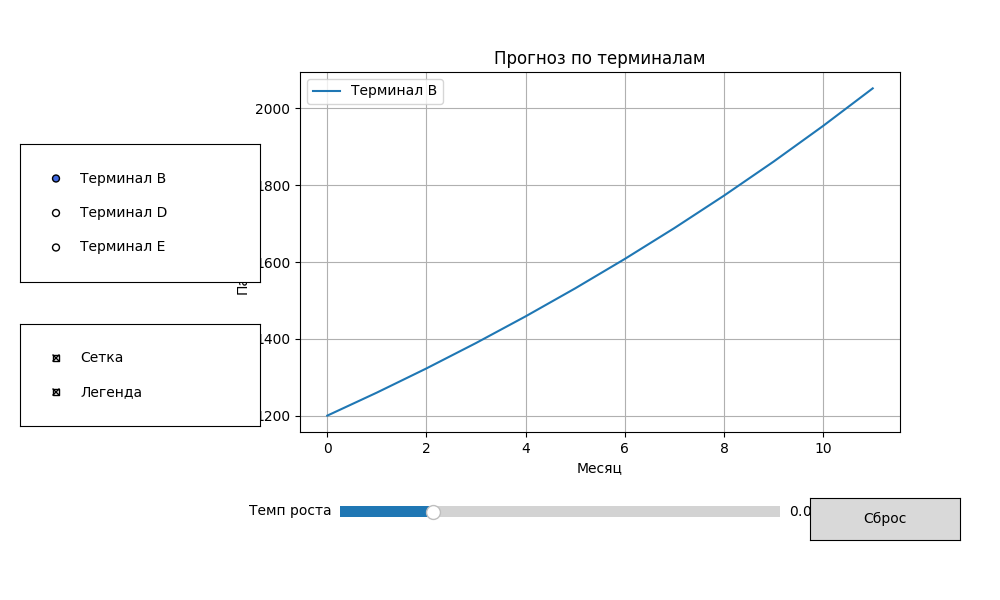

In [ ]:
from matplotlib.widgets import Slider, RadioButtons, CheckButtons, Button

class InteractivePlot:
    def __init__(self):
        self.months = np.arange(12)
        self.base = {
            "Терминал B": 1200,
            "Терминал D": 800,
            "Терминал E": 1000
        }

        self.terminal = "Терминал B"
        self.show_grid = True
        self.show_legend = True

        self.fig, self.ax = plt.subplots(figsize=(10, 6))
        self.fig.subplots_adjust(left=0.30, bottom=0.28)

        self.line, = self.ax.plot(
            self.months,
            self._values(0.05),
            label=self.terminal
        )

        self.ax.set_title("Прогноз по терминалам")
        self.ax.set_xlabel("Месяц")
        self.ax.set_ylabel("Пассажиры")
        self.ax.grid(True)
        self.legend = self.ax.legend()

        # Слайдер
        self.slider = Slider(
            self.fig.add_axes([0.34, 0.13, 0.44, 0.035]),
            "Темп роста",
            0.01, 0.20,
            valinit=0.05,
            valstep=0.01
        )

        # Выбор терминала
        self.radio = RadioButtons(
            self.fig.add_axes([0.02, 0.53, 0.24, 0.23]),
            list(self.base),
            active=0,
            activecolor="royalblue"
        )

        # Сетка и легенда
        self.check = CheckButtons(
            self.fig.add_axes([0.02, 0.29, 0.24, 0.17]),
            ["Сетка", "Легенда"],
            [True, True]
        )

        # Кнопка сброса
        self.button = Button(
            self.fig.add_axes([0.81, 0.10, 0.15, 0.07]),
            "Сброс"
        )

        self.slider.on_changed(self._update)
        self.radio.on_clicked(self._change_terminal)
        self.check.on_clicked(self._toggle_grid)
        self.button.on_clicked(self._reset)

    def _values(self, growth):
        return self.base[self.terminal] * (1 + growth) ** self.months

    def _update(self, _):
        self.line.set_ydata(self._values(self.slider.val))
        self.ax.relim()
        self.ax.autoscale_view()
        self.fig.canvas.draw_idle()

    def _change_terminal(self, label):
        self.terminal = label
        self.line.set_label(label)

        self.legend = self.ax.legend()
        self.legend.set_visible(self.show_legend)

        self._update(None)

    def _toggle_grid(self, label):
        if label == "Сетка":
            self.show_grid = not self.show_grid
            self.ax.grid(self.show_grid)
        else:
            self.show_legend = not self.show_legend
            self.legend.set_visible(self.show_legend)

        self.fig.canvas.draw_idle()

    def _reset(self, event):
        self.slider.reset()
        self.radio.set_active(0)

        for i, enabled in enumerate(self.check.get_status()):
            if not enabled:
                self.check.set_active(i)

        self.fig.canvas.draw_idle()


app = InteractivePlot()
plt.show()

# RadioButtons позволяет выбрать только один терминал.
# CheckButtons позволяет независимо включать несколько опций.
# Button.on_clicked вызывается при нажатии кнопки.
# Slider.on_changed вызывается при изменении значения.
# Ссылки self.slider, self.radio и другие сохраняют виджеты в объекте.
# Без сохранения ссылок виджеты могут быть удалены сборщиком мусора.
# set_active(index) программно выбирает вариант RadioButtons.
# activecolor выделяет выбранный вариант.
# В RadioButtons нельзя одновременно выбрать два варианта.
# Кнопка Сброс возвращает начальные значения виджетов.

Задача 45 (TextBox и RangeSlider с синхронизацией). Аэропорт хочет, чтобы диспетчер мог ввести точный порог задержки через поле ввода или через слайдер — оба варианта должны синхронизироваться. Реализуйте TextBox для точного порога (on_submit → slider.set_val(float(text))), RangeSlider для выбора диапазона дат (ax.set_xlim(*rslider.val)). Синхронизируйте Slider → TextBox с флагом _updating: def on_slider(val): if _guard["updating"]: return; _guard["updating"] = True; textbox.set_val(f"{val:.2f}"); _guard["updating"] = False; redraw(). Обработайте невалидный ввод через try/except ValueError с ax.set_title("Ошибка: введите число"). Ожидаемый вывод: TextBox ↔ Slider синхронизированы; RangeSlider меняет зум. В комментариях объясните: почему без флага _updating возникает бесконечная рекурсия (TextBox → Slider → TextBox → ...); зачем try/except для TextBox (пользователь может ввести буквы); что делает RangeSlider.val (кортеж (min, max) из двух значений); как blitting ускоряет RangeSlider на больших данных (перерисовывается только область внутри зума); что произойдёт при textbox.set_val внутри callback без флага (бесконечная рекурсия → переполнение стека); как slider.set_val(v) программно устанавливает значение и триггерит on_changed (поэтому и нужен флаг).

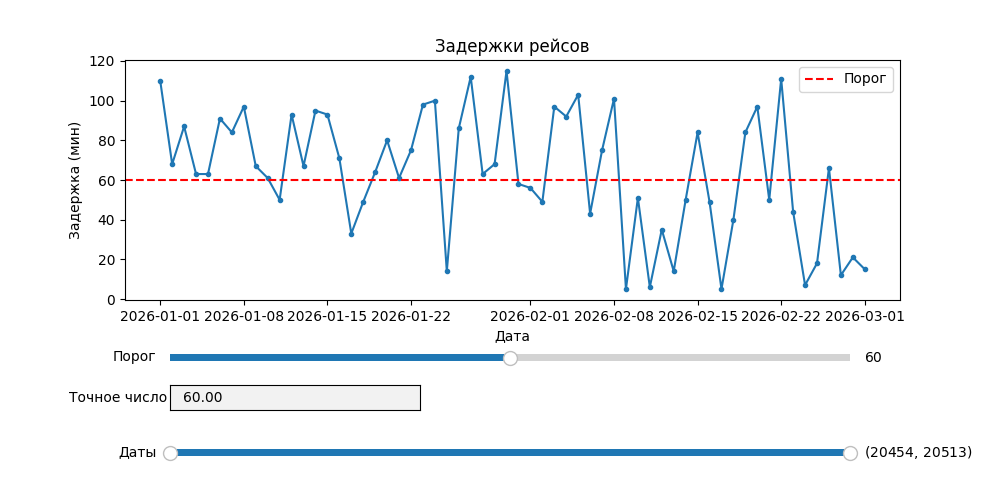

In [ ]:
from matplotlib.widgets import Slider, RangeSlider, TextBox
import matplotlib.dates as mdates

rng = np.random.default_rng(45)

dates = pd.date_range("2026-01-01", periods=60)
delays = rng.integers(0, 120, len(dates))
date_numbers = mdates.date2num(dates.to_numpy())

fig, ax = plt.subplots(figsize=(10, 5))
fig.subplots_adjust(bottom=0.40)

ax.plot(dates, delays, marker="o", markersize=3)
threshold_line = ax.axhline(
    60, color="red", linestyle="--", label="Порог"
)

ax.set_title("Задержки рейсов")
ax.set_xlabel("Дата")
ax.set_ylabel("Задержка (мин)")
ax.legend()

# Слайдер порога
slider = Slider(
    fig.add_axes([0.17, 0.27, 0.68, 0.03]),
    "Порог",
    0, 120,
    valinit=60,
    valstep=1
)

# Поле ввода порога
textbox = TextBox(
    fig.add_axes([0.17, 0.18, 0.25, 0.05]),
    "Точное число",
    initial="60.00"
)

# Слайдер диапазона дат
rslider = RangeSlider(
    fig.add_axes([0.17, 0.08, 0.68, 0.03]),
    "Даты",
    float(date_numbers[0]),
    float(date_numbers[-1]),
    valinit=(float(date_numbers[0]), float(date_numbers[-1])),
    valstep=1
)

_guard = {"updating": False}

def redraw():
    threshold_line.set_ydata([slider.val, slider.val])
    ax.set_title("Задержки рейсов")
    fig.canvas.draw_idle()

def on_slider(val):
    if _guard["updating"]:
        return

    _guard["updating"] = True
    textbox.set_val(f"{val:.2f}")
    _guard["updating"] = False

    redraw()

def on_text(text):
    if _guard["updating"]:
        return

    try:
        value = float(text)
        if not slider.valmin <= value <= slider.valmax:
            raise ValueError
    except ValueError:
        ax.set_title("Ошибка: введите число")
        fig.canvas.draw_idle()
        return

    _guard["updating"] = True
    slider.set_val(value)
    textbox.set_val(f"{value:.2f}")
    _guard["updating"] = False

    redraw()

def on_range(val):
    ax.set_xlim(*rslider.val)
    fig.canvas.draw_idle()

slider.on_changed(on_slider)
textbox.on_submit(on_text)
rslider.on_changed(on_range)

plt.show()

# TextBox позволяет ввести точное число вручную.
# Slider и TextBox синхронизируются через on_changed и on_submit.
# _guard предотвращает рекурсивные вызовы callbacks.
# Без него TextBox -> Slider -> TextBox может вызвать бесконечный цикл.
# try/except обрабатывает буквы и недопустимые значения.
# RangeSlider.val возвращает пару (минимум, максимум).
# Для дат Matplotlib использует числовое представление.
# slider.set_val программно меняет значение и вызывает on_changed.
# blitting может ускорить перерисовку больших графиков.

In [ ]:
# Возвращаем обычный режим графиков для заданий 46–52
%matplotlib inline

Задача 46 (кириллица: FontManager, кэш и fallback). Аэропорт готовит отчёт на русском, но на Windows без правильного шрифта вместо «Рейсы по авиакомпаниям» появляются «□□□□□□□□□□». Реализуйте def setup_cyrillic(fonts=("DejaVu Sans", "Liberation Sans", "Arial", "sans-serif")): plt.rcParams.update({"font.family": fonts, "axes.unicode_minus": False, "font.size": 12}). Проверьте доступность через {f.name for f in font_manager.fontManager.ttflist}. Установите свой корпоративный шрифт через font_manager.fontManager.addfont("/path/to/Corporate.ttf") и name = font_manager.FontProperties(fname="/path/to/Corporate.ttf").get_name(). Ожидаемый вывод: корректные буквы и −5 (а не □5) на осях. В комментариях объясните: почему fallback-цепочка важна (на разных ОС разные шрифты — Linux, macOS, Windows); как addfont регистрирует шрифт в Matplotlib (без него findfont его не найдёт); что делать, если DejaVu Sans «не виден» (_load_fontmanager(try_read_cache=False) — пересобрать кэш); почему axes.unicode_minus = False заменяет − (U+2212) на - (ASCII) — иногда единственный способ на старых шрифтах; как в Jupyter %matplotlib inline иногда «ломает» кириллицу (перезапустите ядро + plt.close("all")); как проверить, что шрифт содержит кириллицу (font_manager.findfont("Arial") и визуально открыть .ttf).

Выбранный шрифт: ['DejaVu Sans']
Доступные шрифты: ['DejaVu Sans', 'DejaVu Sans Display', 'DejaVu Sans Mono', 'DejaVu Serif', 'DejaVu Serif Display', 'Humor Sans', 'Liberation Mono', 'Liberation Sans', 'Liberation Serif', 'STIXGeneral']


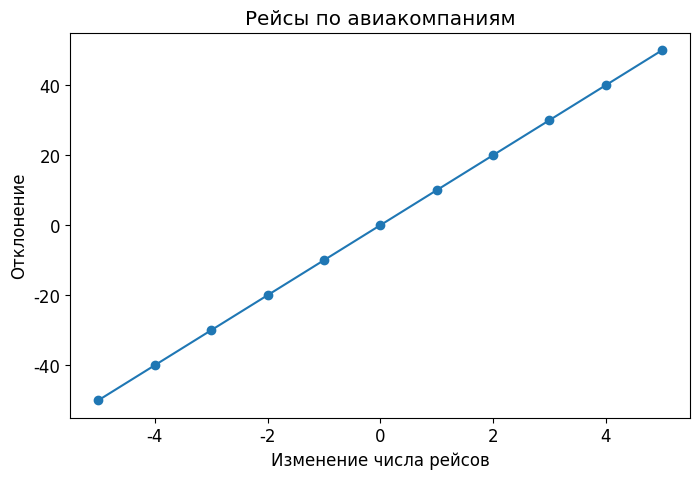

In [ ]:
from matplotlib import font_manager
from pathlib import Path

def setup_cyrillic(
    fonts=("DejaVu Sans", "Liberation Sans", "Arial", "sans-serif")
):
    plt.rcParams.update({
        "font.family": fonts,
        "axes.unicode_minus": False,
        "font.size": 12
    })

    available = {f.name for f in font_manager.fontManager.ttflist}
    chosen = next((f for f in fonts if f in available), "DejaVu Sans")
    plt.rcParams["font.family"] = chosen

    return chosen

chosen_font = setup_cyrillic()

# Необязательный корпоративный шрифт
corporate_font = Path("/path/to/Corporate.ttf")

if corporate_font.is_file():
    font_manager.fontManager.addfont(str(corporate_font))
    name = font_manager.FontProperties(
        fname=str(corporate_font)
    ).get_name()

    plt.rcParams["font.family"] = name

x = np.arange(-5, 6)
y = x * 10

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, y, marker="o")
ax.set_title("Рейсы по авиакомпаниям")
ax.set_xlabel("Изменение числа рейсов")
ax.set_ylabel("Отклонение")

print("Выбранный шрифт:", plt.rcParams["font.family"])
print("Доступные шрифты:", sorted(
    {f.name for f in font_manager.fontManager.ttflist}
)[:10])

plt.show()

# Цепочка шрифтов нужна, поскольку на разных ОС доступны разные шрифты.
# addfont регистрирует пользовательский TTF в Matplotlib.
# Без регистрации собственный шрифт может быть недоступен findfont.
# Если шрифт не появился, можно пересоздать кэш через
# font_manager._load_fontmanager(try_read_cache=False).
# Это внутренний метод, поэтому его используют с осторожностью.
# axes.unicode_minus=False использует обычный минус "-" вместо "−".
# Это помогает при несовместимости старых шрифтов с Unicode.
# После проблем со шрифтами в Jupyter иногда помогает перезапуск ядра
# и plt.close("all").
# Наличие кириллицы проверяют визуально на графике.
# findfont показывает выбранный файл шрифта, но не гарантирует
# поддержку всех русских символов.

Задача 47 (собственный .mplstyle и комбинирование). Аэропорт хочет, чтобы все отчёты выглядели в фирменном стиле (синий цвет бренда, шрифт DejaVu Sans, без верхней и правой рамки). Создайте report.mplstyle с настройками: figure.figsize: 10, 6, font.family: DejaVu Sans, axes.titlesize: 14, axes.spines.top: False, axes.spines.right: False, axes.grid: True, grid.alpha: 0.4, legend.fontsize: 11, axes.unicode_minus: False, axes.prop_cycle: cycler('color', ['#1f77b4', '#ff7f0e', ...]) (фирменные цвета). Загрузите plt.style.use(["seaborn-v0_8", "report.mplstyle"]). Дополнительно создайте dark.mplstyle с figure.facecolor: black, axes.facecolor: black, text.color: white. Постройте три графика в трёх стилях. Ожидаемый вывод: 3 разных внешних вида. В комментариях объясните: как .mplstyle работает с plt.style.use (парсит файл и применяет к rcParams); зачем порядок в списке (второй стиль переопределяет первый); как положить стиль в ~/.config/matplotlib/stylelib/ для загрузки по имени (plt.style.use("report")); как комбинировать с rc_context для временного применения; что произойдёт при ошибке в .mplstyle (ValueError: Invalid rcparameter — отладить через plt.style.use("default") + mpl.rcdefaults()); как использовать axes.prop_cycle для автоматической палитры бренда.

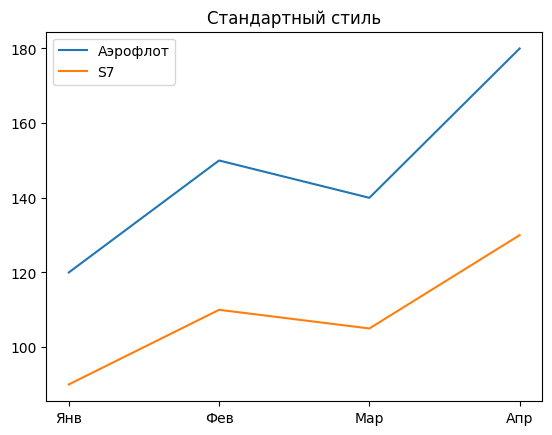

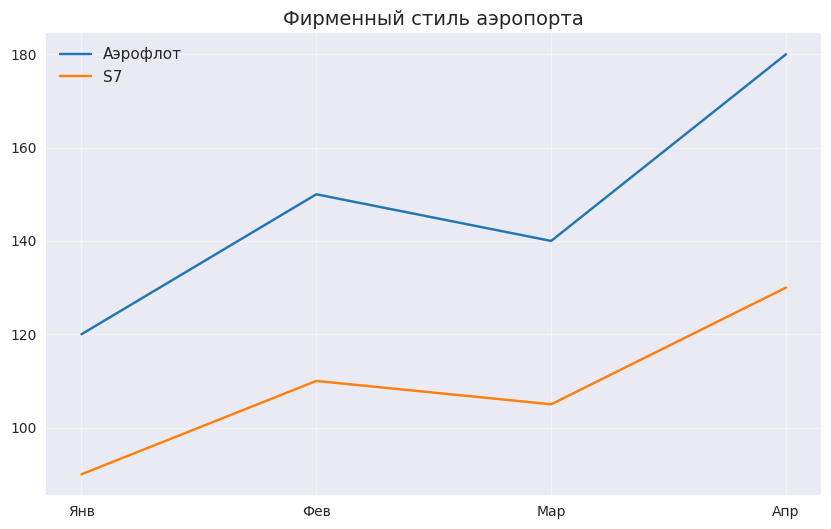

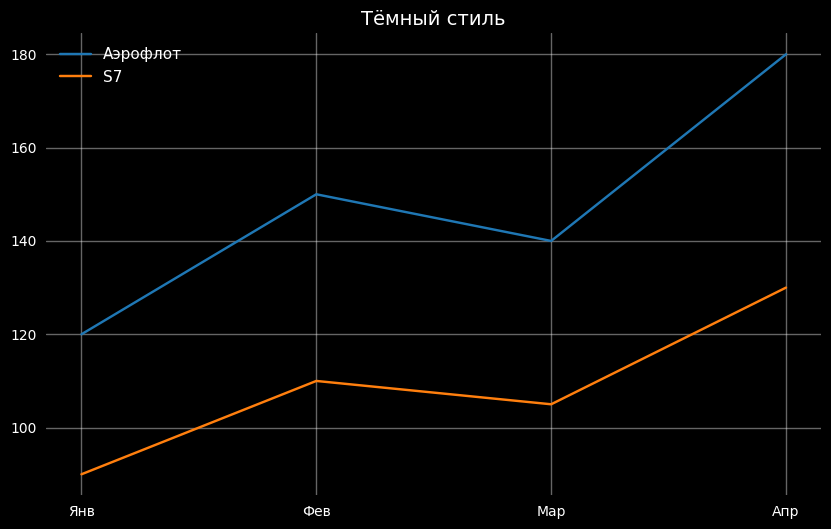

In [ ]:
import matplotlib as mpl
from pathlib import Path

# Создание фирменного стиля
Path("report.mplstyle").write_text("""
figure.figsize: 10, 6
font.family: DejaVu Sans
axes.titlesize: 14
axes.spines.top: False
axes.spines.right: False
axes.grid: True
grid.alpha: 0.4
legend.fontsize: 11
axes.unicode_minus: False
axes.prop_cycle: cycler('color', ['1f77b4', 'ff7f0e', '2ca02c'])
""", encoding="utf-8")

# Создание тёмного стиля
Path("dark.mplstyle").write_text("""
figure.facecolor: black
axes.facecolor: black
text.color: white
axes.titlecolor: white
axes.labelcolor: white
xtick.color: white
ytick.color: white
axes.edgecolor: white
legend.labelcolor: white
""", encoding="utf-8")

months = ["Янв", "Фев", "Мар", "Апр"]
aeroflot = [120, 150, 140, 180]
s7 = [90, 110, 105, 130]

# 1. Стандартный стиль
with plt.style.context("default"):
    fig, ax = plt.subplots()
    ax.plot(months, aeroflot, label="Аэрофлот")
    ax.plot(months, s7, label="S7")
    ax.set_title("Стандартный стиль")
    ax.legend()
    plt.show()

# 2. Фирменный стиль
plt.style.use(["seaborn-v0_8", "report.mplstyle"])

fig, ax = plt.subplots()
ax.plot(months, aeroflot, label="Аэрофлот")
ax.plot(months, s7, label="S7")
ax.set_title("Фирменный стиль аэропорта")
ax.legend()
plt.show()

# 3. Тёмный стиль
with plt.style.context("dark.mplstyle"):
    fig, ax = plt.subplots()
    ax.plot(months, aeroflot, label="Аэрофлот")
    ax.plot(months, s7, label="S7")
    ax.set_title("Тёмный стиль")
    ax.legend()
    plt.show()

mpl.rcdefaults()

# mplstyle хранит параметры оформления Matplotlib.
# style.use загружает их и применяет к rcParams.
# При объединении стилей второй перекрывает первый.
# axes.prop_cycle задаёт автоматическую палитру линий.
# HEX-коды в mplstyle пишут без #, чтобы они не стали комментариями.
# Пользовательские стили можно хранить в ~/.config/matplotlib/stylelib/.
# Тогда после обновления библиотеки стилей можно использовать имя report.
# rc_context позволяет временно применять отдельные настройки.
# Ошибочный параметр в mplstyle вызывает предупреждение о конфигурации.
# mpl.rcdefaults() возвращает стандартные настройки Matplotlib.

Задача 48 (экспорт: PdfPages, hashlib, логирование). Аэропорт готовит ежемесячный отчёт: 12 графиков в PDF + отдельные PNG для email-рассылки. Реализуйте def export_all(fig, name, formats=("png", "pdf", "svg"), dpi=300, log_path=Path("export.log")): сохраните в outputs/{name}.{fmt}, залогируйте путь, размер и SHA-256 через logging. Дополнительно объедините все фигуры в report.pdf через with PdfPages("outputs/report.pdf") as pdf: for fig in figs: pdf.savefig(fig, bbox_inches="tight"). Ожидаемый вывод: 12+ файлов в outputs/; report.pdf объединяет все страницы; лог с хэшами. В комментариях объясните: зачем hashlib.sha256 (кэш CI — не пересобирать отчёт, если входные данные не менялись); как PdfPages работает как контекстный менеджер (наследует AbstractContextManager, автоматически закрывает файл); почему logging лучше print (уровни, форматирование, запись в файл); как закрыть фигуры (plt.close(fig) или plt.close("all") — избежать утечек памяти при 100+ графиках); как metadata={"Title": "Отчёт за январь", "Author": "Иванов"} встраивает информацию в PDF; почему Path удобнее os.path (кросс-платформенные пути, .mkdir(parents=True, exist_ok=True)).

In [ ]:
import hashlib
import logging
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

def export_all(
    fig,
    name,
    formats=("png", "pdf", "svg"),
    dpi=300,
    log_path=Path("export.log")
):
    folder = Path("outputs")
    folder.mkdir(parents=True, exist_ok=True)

    logger = logging.getLogger("airport_exports")
    logger.setLevel(logging.INFO)
    logger.propagate = False

    handler = logging.FileHandler(log_path, encoding="utf-8")
    handler.setFormatter(logging.Formatter("%(message)s"))
    logger.addHandler(handler)

    try:
        for fmt in formats:
            path = folder / f"{name}.{fmt}"
            fig.savefig(path, dpi=dpi, bbox_inches="tight")

            size = path.stat().st_size
            file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

            logger.info(
                "%s | %d байт | SHA-256: %s",
                path, size, file_hash
            )
    finally:
        logger.removeHandler(handler)
        handler.close()


rng = np.random.default_rng(48)
figs = []

# Создаём 12 месячных графиков
for month in range(1, 13):
    days = np.arange(1, 31)
    passengers = (
        1200 + month * 40 + rng.normal(0, 120, len(days))
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(days, passengers)
    ax.set_title(f"Пассажиропоток — месяц {month}")
    ax.set_xlabel("День")
    ax.set_ylabel("Пассажиры")

    export_all(fig, f"month_{month:02d}")
    figs.append(fig)

# Общий многостраничный PDF
with PdfPages(
    "outputs/report.pdf",
    metadata={"Title": "Отчёт аэропорта", "Author": "Аэропорт"}
) as pdf:
    for fig in figs:
        pdf.savefig(fig, bbox_inches="tight")

for fig in figs:
    plt.close(fig)

print("12 графиков экспортированы в PNG, PDF и SVG")
print("Общий файл: outputs/report.pdf")
print("Журнал: export.log")

# SHA-256 помогает сравнивать содержимое файлов и проверять изменения.
# Хэши можно использовать для кэширования в CI.
# PdfPages объединяет несколько фигур в многостраничный PDF.
# Контекстный менеджер with автоматически закрывает PDF.
# logging удобнее print: поддерживает формат, уровни и запись в файл.
# plt.close освобождает память после работы с фигурами.
# Это важно при создании большого количества графиков.
# metadata добавляет сведения об авторе и названии документа.
# Path создаёт пути, совместимые с разными операционными системами.
# mkdir(parents=True, exist_ok=True) создаёт отсутствующие папки.

12 графиков экспортированы в PNG, PDF и SVG
Общий файл: outputs/report.pdf
Журнал: export.log


Задача 49 (Seaborn set_theme и relplot с col/row). Аэропорт анализирует данные о чаевых (встроенный tips) как аналог анализа расходов пассажиров в кафе терминала. Seaborn — надстройка над Matplotlib, которая автоматизирует «красивые дефолты» и группировку. Выполните sns.set_theme(style="whitegrid", palette="muted", font_scale=1.2), загрузите tips = sns.load_dataset("tips"), постройте g = sns.relplot(data=tips, x="total_bill", y="tip", hue="sex", col="time", row="smoker", kind="scatter", height=3, aspect=1.2). Настройте g.set_titles("{col_name} — {row_name}"), g.set_axis_labels("Сумма счёта", "Чаевые"), g.fig.suptitle(...). Ожидаемый вывод: 2×2 FacetGrid (пол × время × курение). В комментариях объясните: как col/row строят сетку (col — столбцы, row — строки); что такое FacetGrid (обёртка над сеткой подграфиков); чем relplot (figure-level) отличается от scatterplot (axes-level) — первый создаёт сетку, второй рисует на одной оси; как ax= встраивает axes-level функцию в matplotlib-фигуру; что делает col_wrap=2 (переносит сетку, если много столбцов); как g.savefig("grid.png", dpi=200, bbox_inches="tight") сохраняет всю сетку.

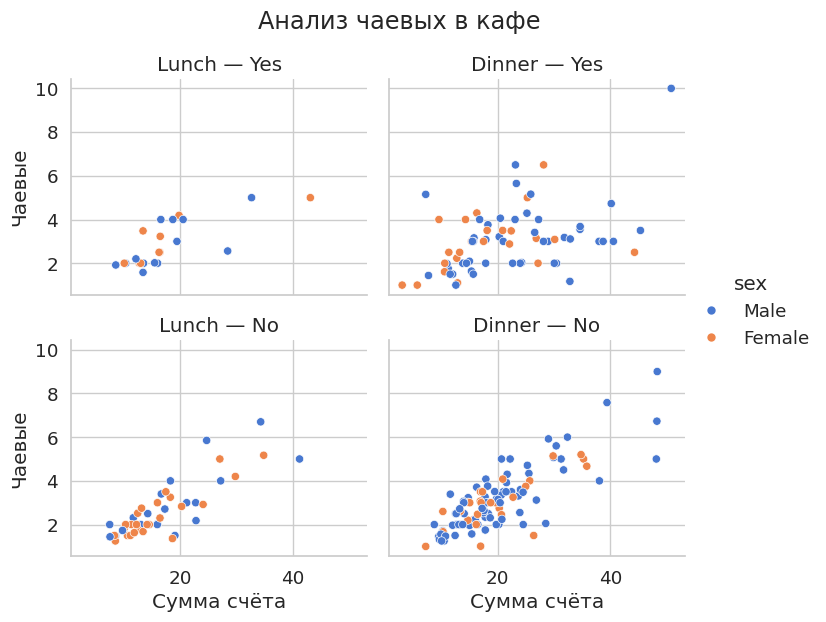

In [ ]:
sns.set_theme(
    style="whitegrid",
    palette="muted",
    font_scale=1.2
)

tips = sns.load_dataset("tips")

g = sns.relplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="sex",
    col="time",
    row="smoker",
    kind="scatter",
    height=3,
    aspect=1.2
)

g.set_titles("{col_name} — {row_name}")
g.set_axis_labels("Сумма счёта", "Чаевые")
g.fig.suptitle("Анализ чаевых в кафе", y=1.04)

g.savefig("grid.png", dpi=200, bbox_inches="tight")

plt.show()

# set_theme задаёт общий стиль Seaborn.
# col создаёт столбцы, row — строки сетки.
# hue разделяет категории разными цветами.
# FacetGrid — объект, объединяющий несколько подграфиков.
# relplot — figure-level функция, автоматически создающая сетку.
# scatterplot — axes-level функция, работающая с отдельной Axes.
# Параметр ax= позволяет встроить scatterplot в готовую фигуру.
# col_wrap=2 переносит графики после каждых двух столбцов.
# g.savefig сохраняет всю сетку целиком.

Задача 50 (Seaborn: распределения — histplot, kdeplot, displot, ecdfplot). Аэропорт исследует распределение задержек по типам рейсов (внутренние, международные, чартерные). Seaborn даёт четыре инструмента: histplot (гистограмма с KDE), kdeplot (сглаженная плотность), displot (figure-level сетка), ecdfplot (накопленная CDF). Постройте 4 подграфика: histplot(kde=True), kdeplot(fill=True, common_norm=False), displot(col="flight_type", kind="kde"), ecdfplot(hue="flight_type"). Ожидаемый вывод: 4 вида визуализации распределений. В комментариях объясните: что делает kde (Kernel Density Estimation — сглаженная оценка плотности); зачем fill=True (заливка под кривой — читается лучше); чем displot отличается от histplot (figure-level создаёт сетку автоматически); что такое ecdf (эмпирическая CDF — «доля рейсов с задержкой меньше X»); что делает common_norm=False (доли внутри групп, а не по всей выборке); что произойдёт при hue с 10+ категориями (все кривые перекроются — используйте displot(col=...) вместо kdeplot(hue=...)).

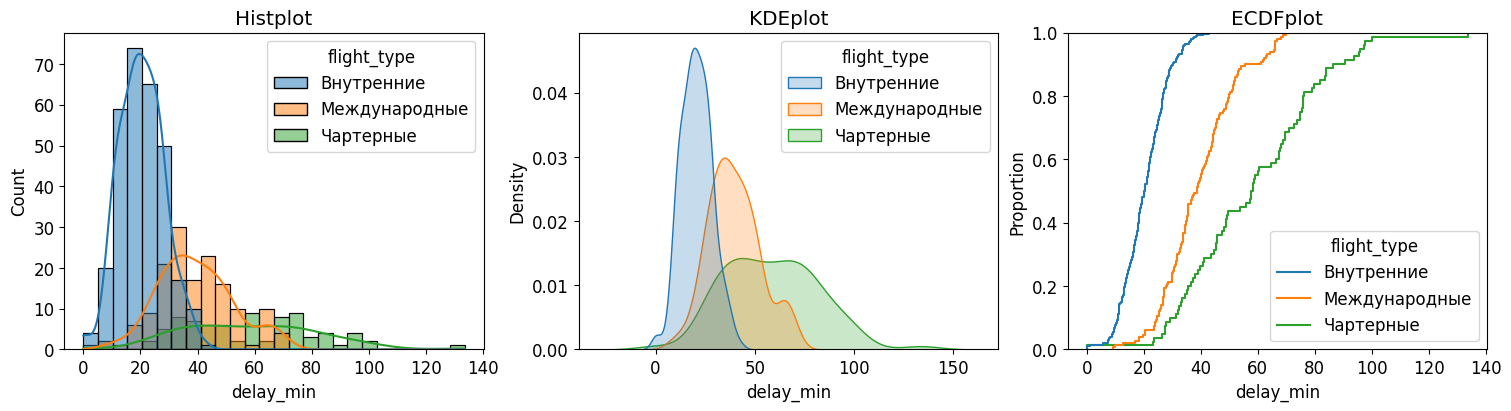

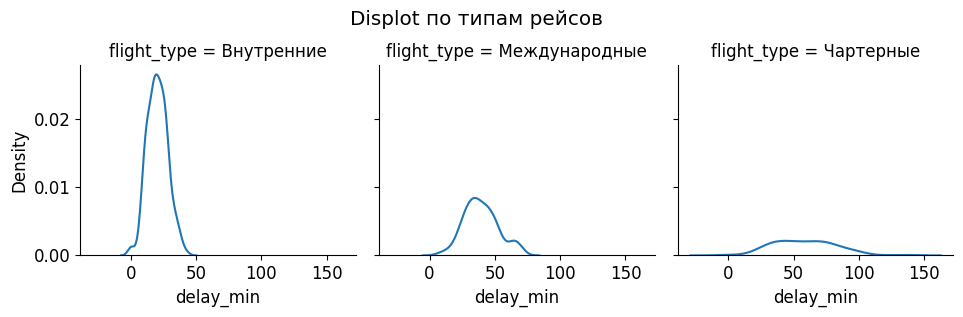

In [ ]:
rng = np.random.default_rng(50)

df = pd.DataFrame({
    "flight_type": np.repeat(
        ["Внутренние", "Международные", "Чартерные"],
        [300, 150, 80]
    ),
    "delay_min": np.concatenate([
        np.clip(rng.normal(20, 8, 300), 0, None),
        np.clip(rng.normal(40, 14, 150), 0, None),
        np.clip(rng.normal(55, 22, 80), 0, None)
    ])
})

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4), layout="constrained"
)

# 1. Гистограмма с KDE
sns.histplot(
    data=df,
    x="delay_min",
    hue="flight_type",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Histplot")

# 2. Сглаженная плотность
sns.kdeplot(
    data=df,
    x="delay_min",
    hue="flight_type",
    fill=True,
    common_norm=False,
    ax=axes[1]
)
axes[1].set_title("KDEplot")

# 3. Накопленное распределение
sns.ecdfplot(
    data=df,
    x="delay_min",
    hue="flight_type",
    ax=axes[2]
)
axes[2].set_title("ECDFplot")

plt.show()

# 4. Отдельная сетка распределений
g = sns.displot(
    data=df,
    x="delay_min",
    col="flight_type",
    kind="kde",
    height=3,
    aspect=1.1
)

g.fig.suptitle("Displot по типам рейсов", y=1.05)
plt.show()

# histplot строит гистограмму, kde=True добавляет гладкую кривую.
# KDE — Kernel Density Estimation, оценка плотности распределения.
# fill=True закрашивает пространство под кривой плотности.
# common_norm=False нормирует каждую группу отдельно.
# displot автоматически создаёт отдельную фигуру или сетку.
# ecdfplot показывает накопленную долю значений не больше X.
# Если категорий 10+, линии hue могут сильно перекрываться.
# В таких случаях удобнее разделять группы через displot(col=...).

Задача 51 (Seaborn: категориальные — boxplot, violinplot, barplot, countplot). Аэропорт анализирует данные Titanic (встроенный датасет — модель для понимания выживаемости пассажиров, аналогично анализу удержания пассажиропотока). Постройте 4 подграфика: boxplot(x="class", y="age", hue="sex"), violinplot(x="class", y="age", hue="sex", split=True) (split=True — половина «скрипки» для каждой группы), barplot(x="class", y="survived", errorbar="ci") (среднее с CI), countplot(x="class", hue="sex") (частоты). Дополнительно g = sns.catplot(data=titanic, x="class", y="survived", col="sex", kind="bar", errorbar="ci"). Ожидаемый вывод: 5 видов категориальных графиков. В комментариях объясните: когда violinplot лучше boxplot (когда важна плотность распределения — мультимодальность); что делает split=True (разделяет «скрипку» пополам для двух групп — сравнение распределений напрямую); почему barplot показывает среднее (не сумму — для суммы используйте df.groupby(...).agg("sum")); что кодирует errorbar="ci" (доверительный интервал среднего); чем countplot отличается от barplot (частоты vs значения); как catplot (figure-level) vs barplot (axes-level) — когда что.

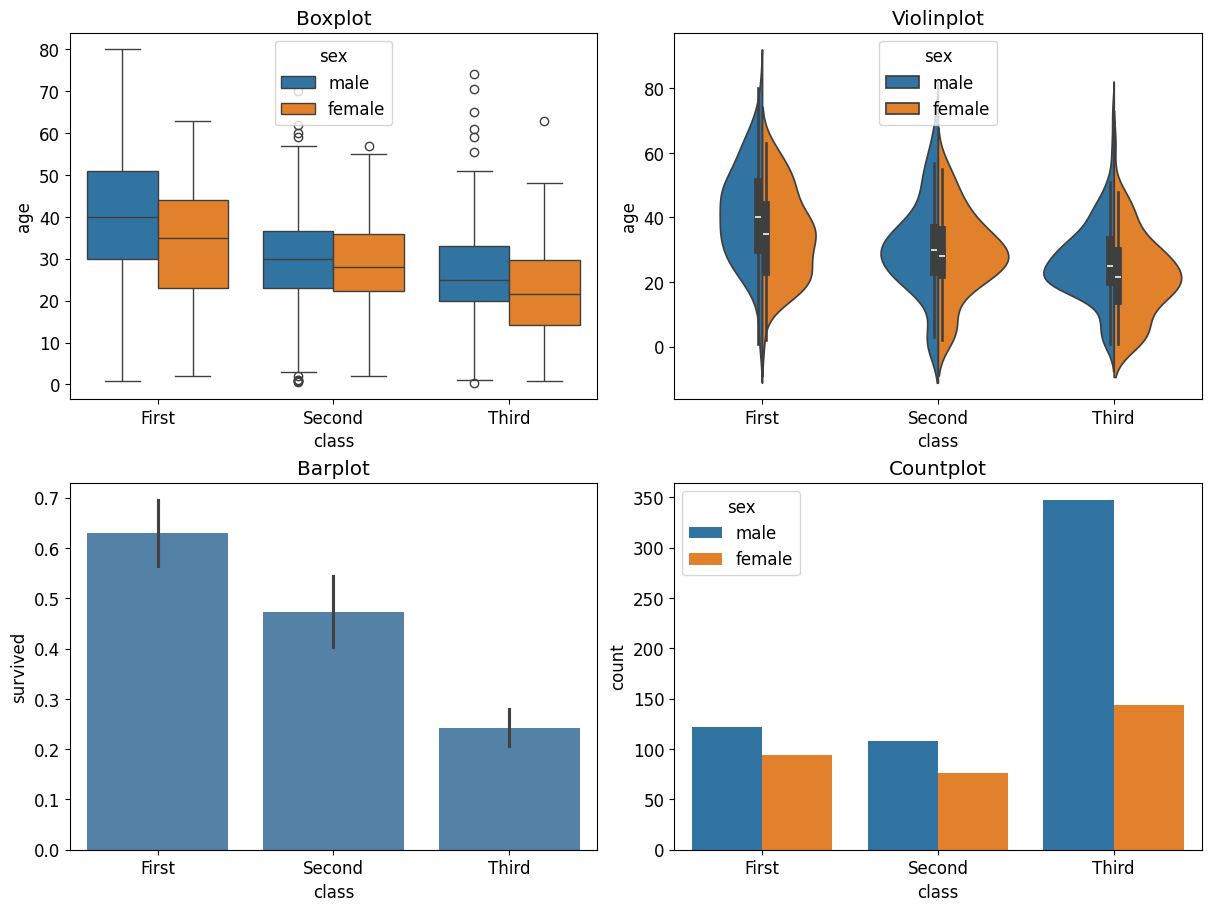

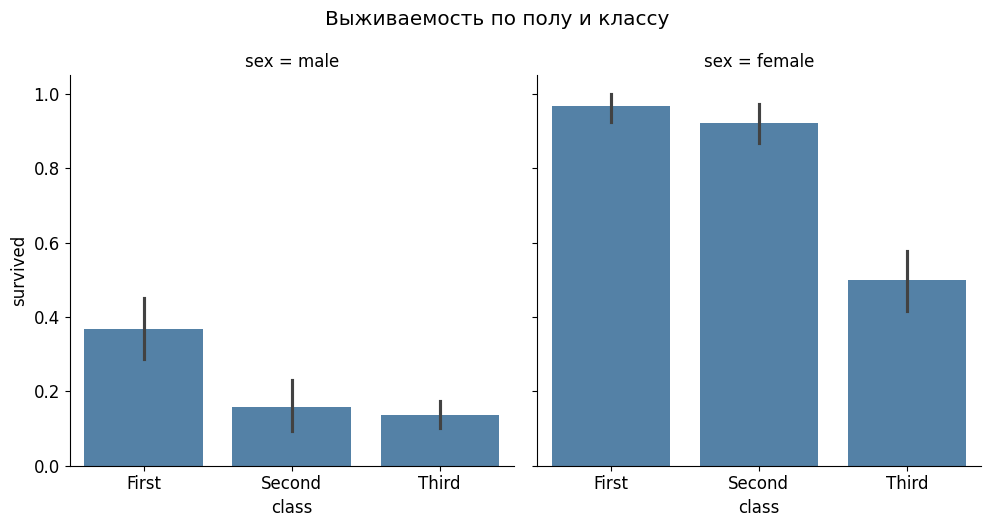

In [ ]:
titanic = sns.load_dataset("titanic")

fig, axes = plt.subplots(
    2, 2, figsize=(12, 9), layout="constrained"
)

# 1. Boxplot
sns.boxplot(
    data=titanic,
    x="class",
    y="age",
    hue="sex",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Boxplot")

# 2. Violinplot
sns.violinplot(
    data=titanic,
    x="class",
    y="age",
    hue="sex",
    split=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Violinplot")

# 3. Barplot
sns.barplot(
    data=titanic,
    x="class",
    y="survived",
    errorbar="ci",
    color="steelblue",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Barplot")

# 4. Countplot
sns.countplot(
    data=titanic,
    x="class",
    hue="sex",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Countplot")

plt.show()

# 5. Catplot
g = sns.catplot(
    data=titanic,
    x="class",
    y="survived",
    col="sex",
    kind="bar",
    errorbar="ci",
    color="steelblue"
)

g.fig.suptitle("Выживаемость по полу и классу", y=1.05)
plt.show()

# boxplot показывает медиану, квартили и выбросы.
# violinplot показывает форму распределения и его плотность.
# split=True делит скрипку на две половины для сравнения групп.
# Violinplot полезнее, если важно увидеть несколько пиков плотности.
# Boxplot компактнее и удобнее для большого числа категорий.
# barplot по умолчанию показывает среднее, а не сумму.
# Для суммы используют groupby(...).agg("sum").
# errorbar="ci" показывает доверительный интервал оценки среднего.
# countplot считает количество наблюдений в каждой категории.
# catplot — figure-level функция, barplot — axes-level.

Задача 52 (Seaborn: heatmap, clustermap и pivot). Аэропорт анализирует пассажиропоток по направлениям и месяцам (встроенный flights — как аналог). Постройте p = flights.pivot(index="month", columns="year", values="passengers"). Seaborn: sns.heatmap(p, cmap="YlGnBu", annot=True, fmt="d") (с аннотациями), sns.heatmap(p.corr(), cmap="RdBu", vmin=-1, vmax=1, center=0) (корреляции с центром 0), sns.clustermap(p, cmap="viridis", standard_scale=1) (иерархическая кластеризация строк и столбцов). Ожидаемый вывод: 3 heatmap-типа; clustermap переставляет строки/столбцы по схожести. В комментариях объясните: что делает annot=True (добавляет значения в ячейки) и зачем fmt="d" (целые числа); зачем center=0 в корреляциях (белый = ноль, красный = положительный); что такое clustermap (кластеризация — похожие месяцы/годы рядом); как standard_scale=1 нормализует по строкам (сравнение месяцев с разным масштабом); что произойдёт при annot=True на 100×100 (мелко — отключите); как сохранить clustermap через g.savefig (это отдельная фигура, а не Axes).

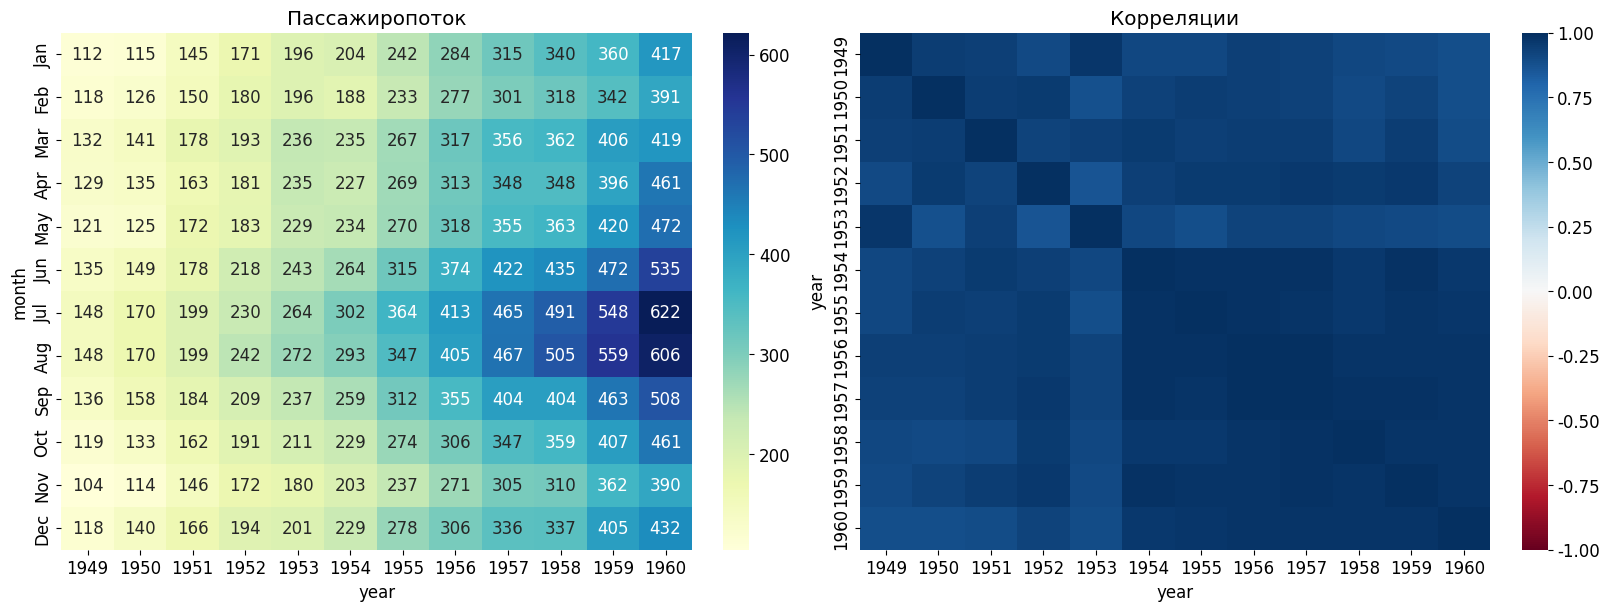

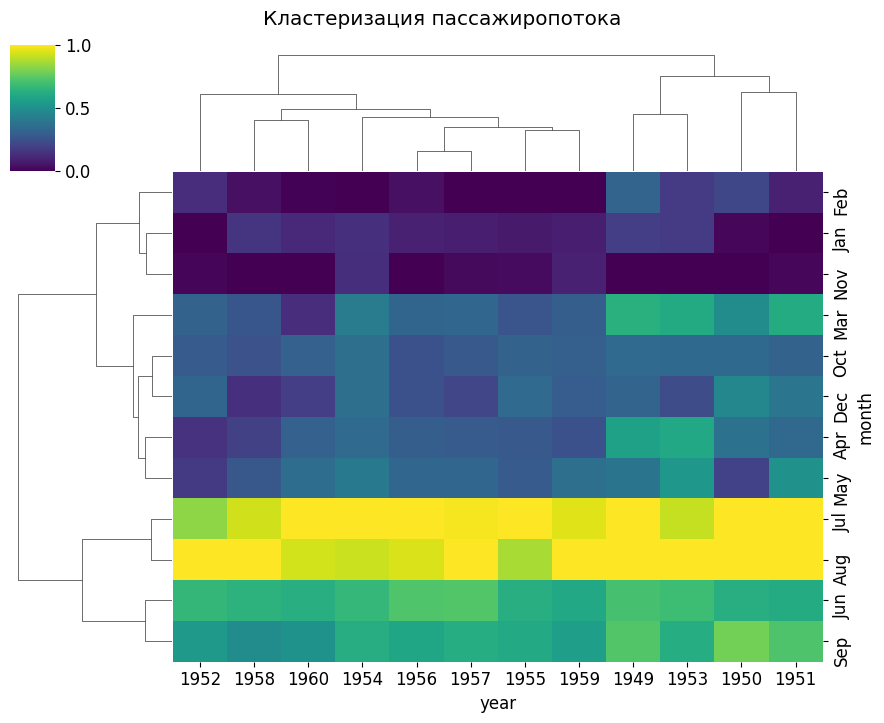

In [ ]:
flights = sns.load_dataset("flights")

p = flights.pivot(
    index="month",
    columns="year",
    values="passengers"
)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6), layout="constrained"
)

# 1. Пассажиропоток по месяцам и годам
sns.heatmap(
    p,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    ax=axes[0]
)
axes[0].set_title("Пассажиропоток")

# 2. Матрица корреляций
sns.heatmap(
    p.corr(),
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1]
)
axes[1].set_title("Корреляции")

plt.show()

# 3. Кластеризованная тепловая карта
g = sns.clustermap(
    p,
    cmap="viridis",
    standard_scale=1,
    figsize=(9, 7)
)

g.fig.suptitle("Кластеризация пассажиропотока", y=1.03)
plt.show()

# pivot создаёт таблицу: строки — месяцы, столбцы — годы.
# heatmap представляет значения таблицы цветами.
# annot=True добавляет числа в ячейки.
# fmt="d" отображает целые числа без десятичных знаков.
# center=0 задаёт центр цветовой шкалы корреляций.
# clustermap группирует похожие строки и столбцы.
# standard_scale=1 нормирует значения по столбцам от 0 до 1.
# Для нормализации по строкам нужно standard_scale=0.
# На матрице 100×100 annot=True создаст слишком много подписей.
# g.savefig("cluster.png") сохраняет всю кластерную фигуру.

In [ ]:
# Подготовка данных для заданий 53–60

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 900

dates = pd.date_range("2026-01-01", periods=90)

df = pd.DataFrame({
    "date": rng.choice(dates, n),
    "airline": rng.choice(
        ["Аэрофлот", "S7", "Победа", "Россия", "Уральские авиалинии"], n
    ),
    "terminal": rng.choice(
        ["Терминал A", "Терминал B", "Терминал C", "Терминал D"], n
    ),
    "flight_type": rng.choice(
        ["Внутренние", "Международные", "Чартерные",
         "Грузовые", "Бизнес", "Транзитные"],
        n, p=[0.40, 0.29, 0.14, 0.08, 0.05, 0.04]
    ),
    "destination": rng.choice(
        ["Москва", "Сочи", "Казань", "Санкт-Петербург",
         "Екатеринбург", "Новосибирск", "Самара", "Уфа", "Тюмень"], n
    ),
    "passengers": rng.integers(50, 251, n),
    "load_factor": rng.uniform(55, 98, n).round(1),
    "fuel_t": rng.uniform(1.2, 13, n).round(2)
})

df["delay_min"] = np.maximum(
    0,
    15 + 0.25 * (df["load_factor"] - 70)
    + 8 * (df["terminal"] == "Терминал D")
    + 7 * (df["flight_type"] == "Чартерные")
    + rng.normal(0, 12, n)
).round(1)

df = df.sort_values("date")
df.to_csv("airport_full.csv", index=False)

print("Файл airport_full.csv создан!")

Файл airport_full.csv создан!


Задача 53 (ReportBuilder — ООП-обёртка для дашбордов). Аэропорт готовит ежемесячный отчёт из 5–9 графиков. Код легко превращается в «лапшу» из axes[i, j].plot(...). Правильная архитектура отделяет «что рисовать» от «как размещать». Реализуйте @dataclass class ReportPage: title: str; plot_fn: Callable[[Axes], None] и class ReportBuilder с build() (создаёт фигуру и размещает страницы), save(path, dpi) (вызывает build + savefig + plt.close). Соберите 5 страниц: динамика пассажиропотока (line), топ направлений (bar), распределение задержек (hist), задержки по авиакомпаниям (box), heatmap терминалов по месяцам (imshow). Пустые ячейки скройте через axes.flat[n:].axis("off"). Ожидаемый вывод: одна фигура с 5 графиками. В комментариях объясните: зачем ReportPage (разделяет «что рисовать» и «как размещать» — легко добавить новый график); как axes.flat[n:] скрывает пустые ячейки при нечётном числе графиков; зачем plt.close(fig) (освободить память при генерации десятков отчётов); как расширить to_pdf через PdfPages (многостраничный отчёт); как связать с PlotConfig (передавать конфигурацию в __init__); когда такой класс — овер-инжиниринг (для одного графика проще plt.subplots).

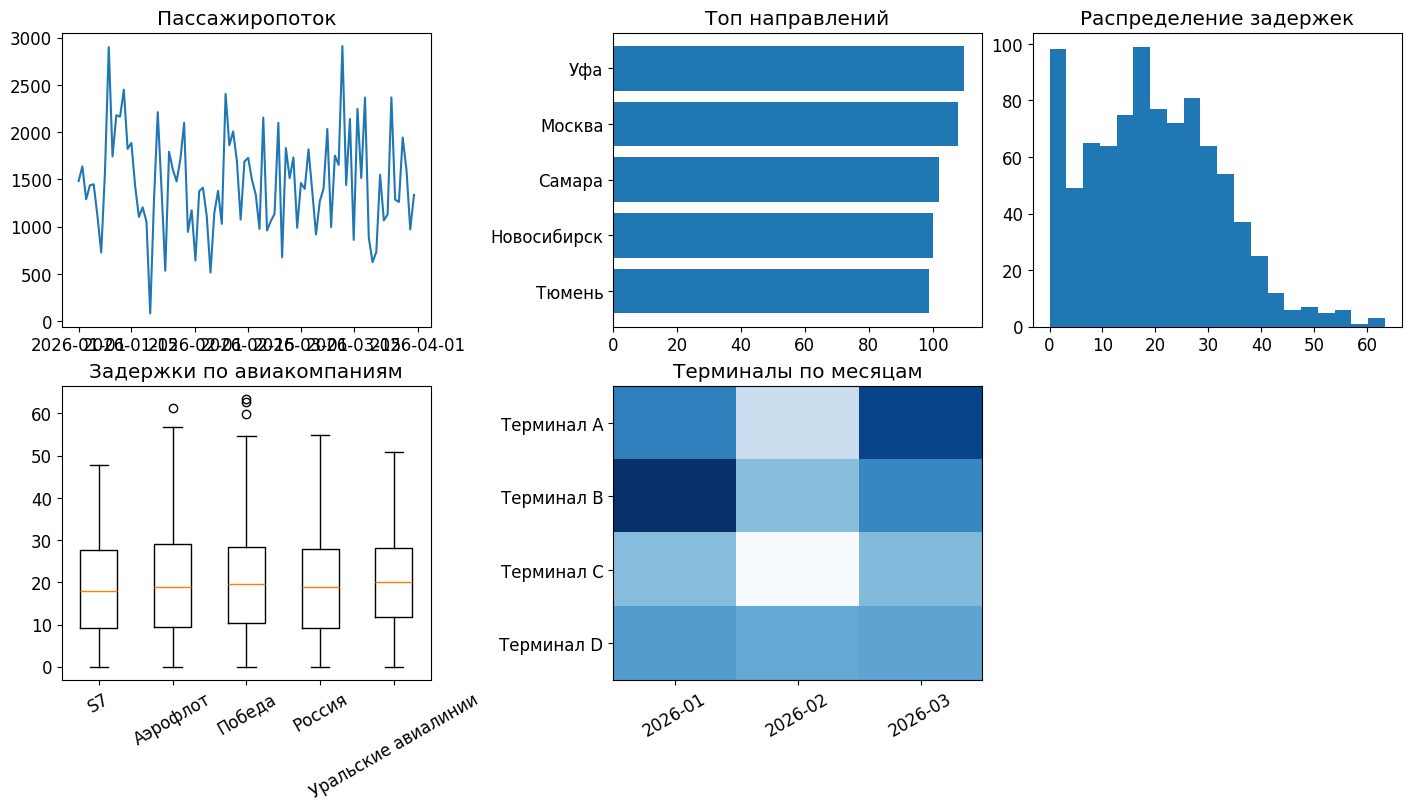

In [ ]:
from dataclasses import dataclass
from typing import Callable
from matplotlib.axes import Axes

df = pd.read_csv("airport_full.csv", parse_dates=["date"])

@dataclass
class ReportPage:
    title: str
    plot_fn: Callable[[Axes], None]

class ReportBuilder:
    def __init__(self, pages):
        self.pages = pages

    def build(self):
        nrows = int(np.ceil(len(self.pages) / 3))

        fig, axes = plt.subplots(
            nrows, 3, figsize=(14, 8), layout="constrained"
        )

        for ax, page in zip(axes.flat, self.pages):
            page.plot_fn(ax)
            ax.set_title(page.title)

        for ax in axes.flat[len(self.pages):]:
            ax.axis("off")

        return fig

    def save(self, path, dpi=300):
        fig = self.build()
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        plt.show()
        plt.close(fig)


def traffic(ax):
    daily = df.groupby("date")["passengers"].sum().sort_index()
    ax.plot(daily.index, daily.values)

def destinations(ax):
    top = df["destination"].value_counts().head(5).sort_values()
    ax.barh(top.index, top.values)

def delays(ax):
    ax.hist(df["delay_min"], bins=20)

def airline_delays(ax):
    names = sorted(df["airline"].unique())
    groups = [df.loc[df["airline"] == name, "delay_min"] for name in names]

    ax.boxplot(groups, tick_labels=names)
    ax.tick_params(axis="x", rotation=30)

def terminal_heatmap(ax):
    table = df.assign(
        month=df["date"].dt.strftime("%Y-%m")
    ).pivot_table(
        index="terminal",
        columns="month",
        values="passengers",
        aggfunc="sum",
        fill_value=0
    )

    ax.imshow(table, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=30)
    ax.set_yticks(range(len(table.index)), table.index)


pages = [
    ReportPage("Пассажиропоток", traffic),
    ReportPage("Топ направлений", destinations),
    ReportPage("Распределение задержек", delays),
    ReportPage("Задержки по авиакомпаниям", airline_delays),
    ReportPage("Терминалы по месяцам", terminal_heatmap)
]

builder = ReportBuilder(pages)
builder.save("report53.png", dpi=300)

# ReportPage хранит название графика и функцию его построения.
# Это разделяет содержимое графика и его расположение.
# axes.flat[n:] позволяет получить лишние ячейки сетки.
# axis("off") скрывает пустые графики.
# plt.close(fig) освобождает память после сохранения отчёта.
# Метод to_pdf можно добавить через PdfPages для многостраничного PDF.
# PlotConfig из задания 2 можно передавать в __init__ класса.
# Для одного простого графика такой класс избыточен.

Задача 54 (LearningCurveAnalyzer — автоматическая диагностика). Аэропорт обучает модели прогноза задержек для 5 авиакомпаний и хочет автоматически получать диагноз «переобучение / недообучение / хорошо». Кривые обучения мощны, но интерпретировать их вручную утомительно. Реализуйте class LearningCurveAnalyzer с методами fit() (вызывает learning_curve и сохраняет train_mean, val_mean, train_std, val_std), diagnose() -> str (пороги: gap = train_mean[-1] - val_mean[-1] > 0.1 → overfitting; val_mean[-1] < 0.7 → underfitting; иначе good), plot(ax=None) (рисует с fill_between), compare(others: list) (сравнивает несколько моделей на одной фигуре). Обучите три модели, сравните, постройте три learning curves с диагнозами в заголовках. Ожидаемый вывод: 3 графика с диагнозами. В комментариях объясните: зачем diagnose (автоматизация — не нужно каждый раз смотреть на график); как пороги gap > 0.1 и val_mean < 0.7 определяют диагноз (эмпирические — зависят от задачи); зачем fit() возвращает self (fluent API — LearningCurveAnalyzer(...).fit().plot()); как логировать результаты в pd.DataFrame для отчёта (pd.DataFrame({"model": ..., "diagnosis": ..., "val_mean": ...})); как связать с ML-дашбордом (задача 56) — learning curves как дополнение к метрикам; когда compare полезнее одиночного plot (сравнение моделей одной серии).

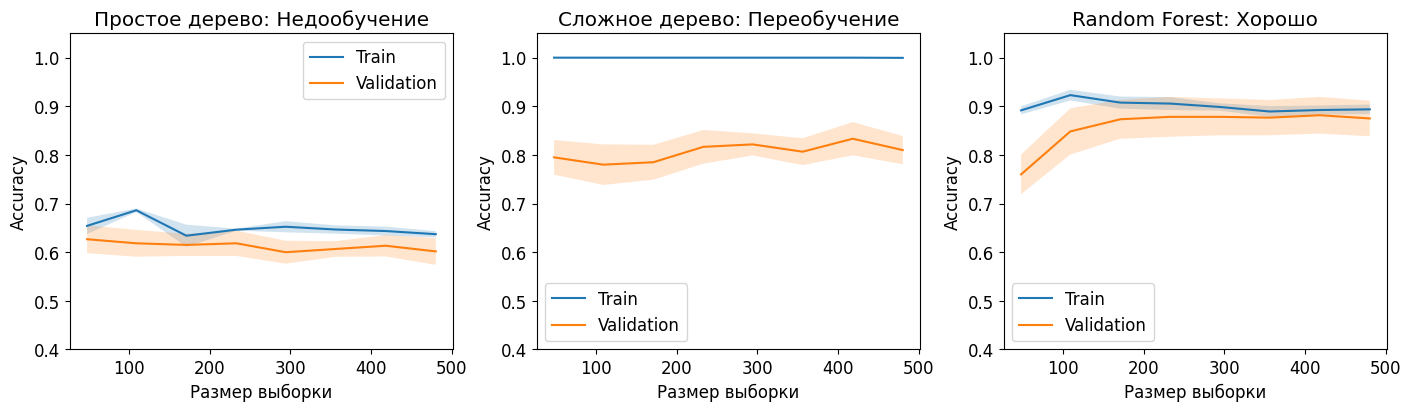

            model     diagnosis  val_mean
0  Простое дерево  Недообучение  0.601667
1  Сложное дерево  Переобучение  0.810000
2   Random Forest        Хорошо  0.875000


In [ ]:
from sklearn.datasets import make_circles
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

class LearningCurveAnalyzer:
    def __init__(self, model, X, y, name):
        self.model = model
        self.X = X
        self.y = y
        self.name = name

    def fit(self):
        self.sizes, train, val = learning_curve(
            self.model,
            self.X,
            self.y,
            train_sizes=np.linspace(0.1, 1.0, 8),
            cv=5,
            scoring="accuracy",
            n_jobs=-1
        )

        self.train_mean = train.mean(axis=1)
        self.val_mean = val.mean(axis=1)
        self.train_std = train.std(axis=1)
        self.val_std = val.std(axis=1)

        return self

    def diagnose(self) -> str:
        gap = self.train_mean[-1] - self.val_mean[-1]

        if gap > 0.1:
            return "Переобучение"
        if self.val_mean[-1] < 0.7:
            return "Недообучение"
        return "Хорошо"

    def plot(self, ax=None):
        if ax is None:
            fig, ax = plt.subplots()

        ax.plot(self.sizes, self.train_mean, label="Train")
        ax.plot(self.sizes, self.val_mean, label="Validation")

        ax.fill_between(
            self.sizes,
            self.train_mean - self.train_std,
            self.train_mean + self.train_std,
            alpha=0.2
        )

        ax.fill_between(
            self.sizes,
            self.val_mean - self.val_std,
            self.val_mean + self.val_std,
            alpha=0.2
        )

        ax.set_title(f"{self.name}: {self.diagnose()}")
        ax.set_xlabel("Размер выборки")
        ax.set_ylabel("Accuracy")
        ax.set_ylim(0.4, 1.05)
        ax.legend()

        return ax

    def compare(self, others: list):
        models = [self] + others

        fig, axes = plt.subplots(
            1, len(models),
            figsize=(14, 4),
            layout="constrained"
        )

        for analyzer, ax in zip(models, np.atleast_1d(axes)):
            analyzer.plot(ax)

        plt.show()


# Искусственная выборка для сравнения моделей
X, y = make_circles(
    n_samples=600, noise=0.1, factor=0.5, random_state=42
)

rng = np.random.default_rng(42)
flip = rng.choice(len(y), size=60, replace=False)
y[flip] = 1 - y[flip]

models = [
    DecisionTreeClassifier(max_depth=1, random_state=42),
    DecisionTreeClassifier(max_depth=20, random_state=42),
    RandomForestClassifier(
        n_estimators=60,
        max_depth=7,
        min_samples_leaf=5,
        random_state=42
    )
]

names = ["Простое дерево", "Сложное дерево", "Random Forest"]

analyzers = [
    LearningCurveAnalyzer(model, X, y, name).fit()
    for model, name in zip(models, names)
]

analyzers[0].compare(analyzers[1:])

results = pd.DataFrame({
    "model": [a.name for a in analyzers],
    "diagnosis": [a.diagnose() for a in analyzers],
    "val_mean": [a.val_mean[-1] for a in analyzers]
})

print(results)

# diagnose автоматически определяет состояние обучения модели.
# gap > 0.1 означает заметную разницу между Train и Validation.
# val_mean < 0.7 при небольшом gap означает недообучение.
# Пороги эмпирические и могут отличаться в других задачах.
# fit возвращает self, поэтому можно вызывать методы цепочкой.
# DataFrame удобно использовать для записи результатов в отчёт.
# Кривые можно добавить к ML-дашборду из задания 56.
# compare удобен для одновременного сравнения нескольких моделей.

Задача 55 (Seaborn PairGrid и кастомизация). Аэропорт анализирует данные рейсов (дальность, загрузка, расход топлива, задержка, стоимость билета). sns.pairplot строит матрицу рассеяния для всех пар, но sns.PairGrid даёт полный контроль: разные типы для верхнего треугольника, нижнего и диагонали. Постройте sns.pairplot(iris, hue="species", corner=True, diag_kind="kde") — быстрый вариант, и g = sns.PairGrid(iris, hue="species", height=2.5); g.map_upper(sns.scatterplot, s=20, alpha=0.6); g.map_lower(sns.kdeplot, fill=True, alpha=0.4); g.map_diag(sns.histplot, kde=True); g.add_legend() — кастомный. Добавьте аннотацию через g.axes[0, 0].annotate("Верхний левый", xy=(5.5, 2.5), fontsize=9, color="red"). Ожидаемый вывод: две grid-визуализации. В комментариях объясните: чем pairplot отличается от PairGrid (первый — быстрый с дефолтами, второй — гибкий); что делают map_upper/map_lower/map_diag (разные функции для разных частей матрицы); как g.axes даёт доступ к Matplotlib-Axes для тонкой настройки (g.axes[0, 0].set_xlim(...)); когда pairplot слишком медленный (много признаков — corner=True убирает половину); как g.savefig("pairgrid.png", dpi=200, bbox_inches="tight") — сохраняет всю сетку; что произойдёт при 10+ признаках (матрица 10×10 — нечитаемо, берите топ-5 по важности).

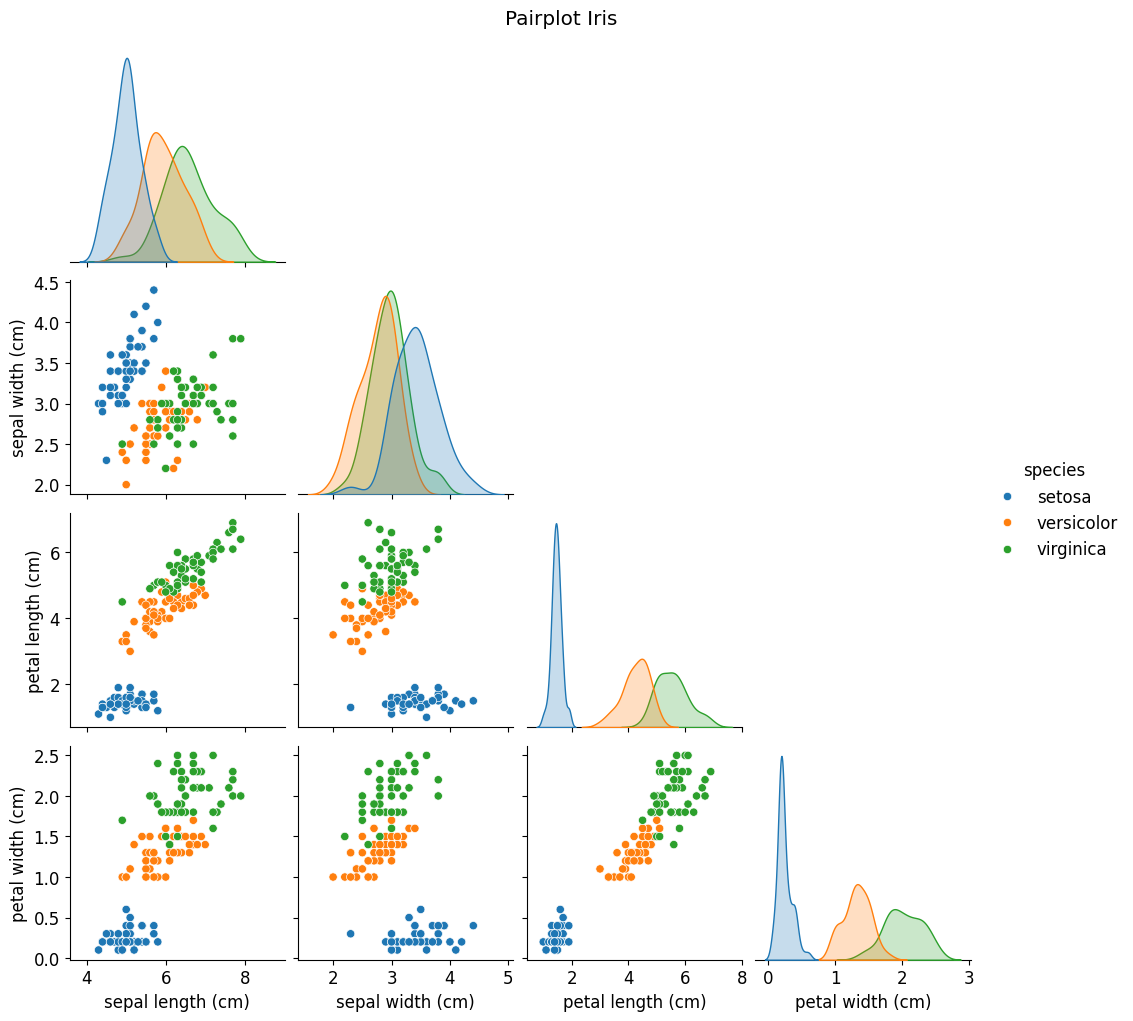

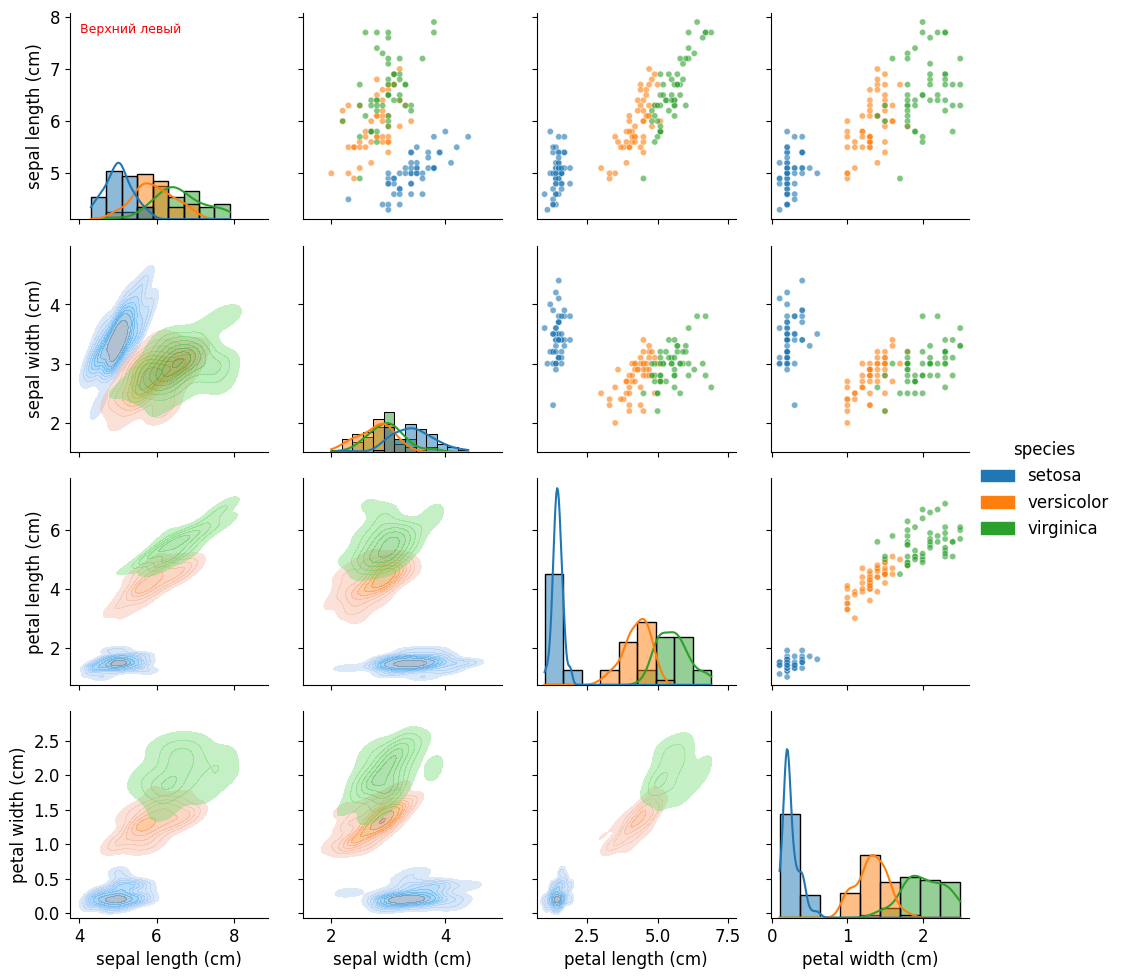

In [ ]:
from sklearn.datasets import load_iris

# Загружаем Iris без необходимости скачивать его из интернета
iris_data = load_iris(as_frame=True)
iris = iris_data.frame.drop(columns=["target"])

iris["species"] = iris_data.target.map(
    dict(enumerate(iris_data.target_names))
)

# Способ 1 — Pairplot
g1 = sns.pairplot(
    iris,
    hue="species",
    corner=True,
    diag_kind="kde"
)

g1.fig.suptitle("Pairplot Iris", y=1.02)
plt.show()

# Способ 2 — PairGrid
g = sns.PairGrid(iris, hue="species", height=2.5)

g.map_upper(sns.scatterplot, s=20, alpha=0.6)
g.map_lower(sns.kdeplot, fill=True, alpha=0.4)
g.map_diag(sns.histplot, kde=True)

g.add_legend()

g.axes[0, 0].annotate(
    "Верхний левый",
    xy=(0.05, 0.9),
    xycoords="axes fraction",
    fontsize=9,
    color="red"
)

g.savefig("pairgrid.png", dpi=200, bbox_inches="tight")
plt.show()

# pairplot быстро создаёт матрицу графиков со стандартным оформлением.
# PairGrid позволяет отдельно настраивать каждую часть матрицы.
# map_upper задаёт графики верхнего треугольника.
# map_lower задаёт графики нижнего треугольника.
# map_diag задаёт распределения на диагонали.
# g.axes даёт доступ к объектам Axes из Matplotlib.
# Например, g.axes[0, 0].set_xlim(...) изменяет пределы оси.
# corner=True убирает повторяющуюся половину матрицы.
# g.savefig сохраняет всю сетку.
# При 10+ признаках матрица станет слишком большой.
# Лучше выбрать несколько наиболее важных признаков.

Задача 56 (MLDashboard — комплексный ML-дашборд). Аэропорт обучает модель прогноза задержек и хочет «одностраничный отчёт» для операционного штаба: confusion matrix, ROC, PR, feature importance. Реализуйте class MLDashboard с методами _confusion(ax), _roc(ax), _pr(ax), _importance(ax) и build() (создаёт fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained"), вызывает все 4 метода, добавляет fig.suptitle(f"ML Dashboard: {type(self.model).__name__}")). Соберите дашборд, сохраните в ml_dashboard.png с dpi=300 и bbox_inches="tight". Ожидаемый вывод: 4 графика на одной фигуре. В комментариях объясните: как приватные методы (_confusion) организуют код (каждый метод — одна ответственность); как suptitle не обрезается благодаря bbox_inches="tight"; как расширить (_calibration, _lift, _learning_curve); как dataclass DashboardConfig улучшил бы API (цвета, размеры шрифтов, dpi); когда такой класс — овер-инжиниринг (для одноразового скрипта проще 4 раза plt.subplots); как логировать дашборд в MLflow (сохранять в mlflow.log_artifact("ml_dashboard.png")).

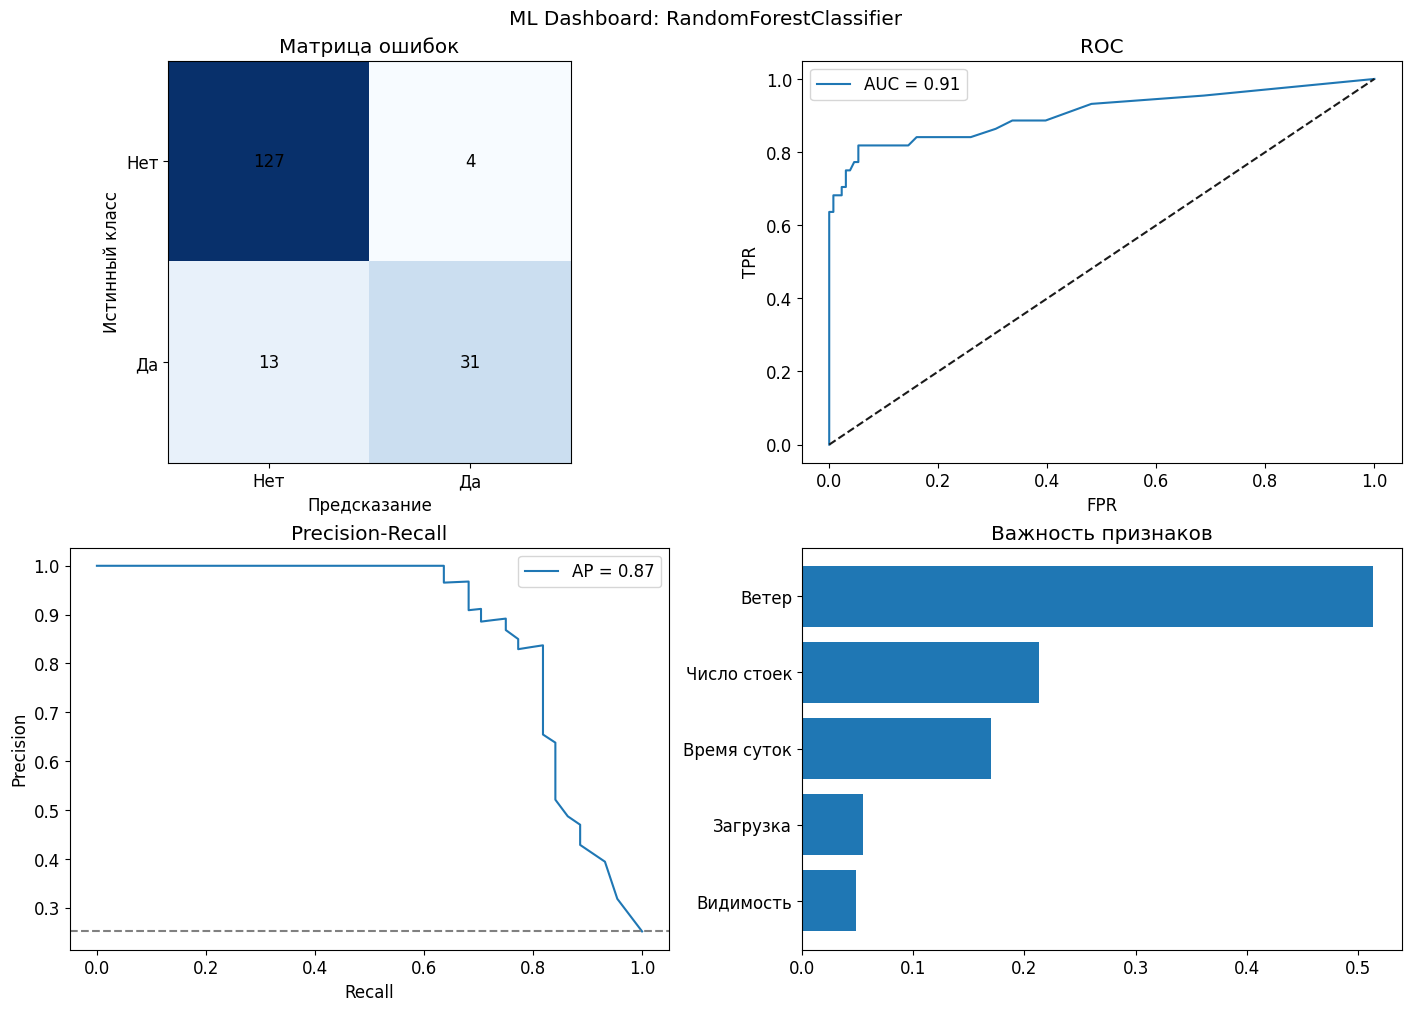

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

class MLDashboard:
    def __init__(self, model, X_test, y_test, names):
        self.model = model
        self.X_test = X_test
        self.y_test = y_test
        self.names = names
        self.y_pred = model.predict(X_test)
        self.y_proba = model.predict_proba(X_test)[:, 1]

    def _confusion(self, ax):
        cm = confusion_matrix(self.y_test, self.y_pred)
        ax.imshow(cm, cmap="Blues")

        for i, j in np.ndindex(cm.shape):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

        ax.set_xticks([0, 1], ["Нет", "Да"])
        ax.set_yticks([0, 1], ["Нет", "Да"])
        ax.set_title("Матрица ошибок")
        ax.set_xlabel("Предсказание")
        ax.set_ylabel("Истинный класс")

    def _roc(self, ax):
        fpr, tpr, _ = roc_curve(self.y_test, self.y_proba)
        auc = roc_auc_score(self.y_test, self.y_proba)

        ax.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
        ax.plot([0, 1], [0, 1], "k--")
        ax.set_title("ROC")
        ax.set_xlabel("FPR")
        ax.set_ylabel("TPR")
        ax.legend()

    def _pr(self, ax):
        precision, recall, _ = precision_recall_curve(
            self.y_test, self.y_proba
        )
        ap = average_precision_score(self.y_test, self.y_proba)

        ax.plot(recall, precision, label=f"AP = {ap:.2f}")
        ax.axhline(self.y_test.mean(), color="gray", linestyle="--")
        ax.set_title("Precision-Recall")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.legend()

    def _importance(self, ax):
        importance = self.model.feature_importances_
        order = np.argsort(importance)

        ax.barh(np.array(self.names)[order], importance[order])
        ax.set_title("Важность признаков")

    def build(self):
        fig, axes = plt.subplots(
            2, 2, figsize=(14, 10), layout="constrained"
        )

        self._confusion(axes[0, 0])
        self._roc(axes[0, 1])
        self._pr(axes[1, 0])
        self._importance(axes[1, 1])

        fig.suptitle(
            f"ML Dashboard: {type(self.model).__name__}"
        )

        return fig


# Создание и обучение модели
X, y = make_classification(
    n_samples=700,
    n_features=5,
    n_informative=3,
    n_redundant=0,
    weights=[0.75, 0.25],
    random_state=42
)

names = ["Загрузка", "Ветер", "Видимость", "Число стоек", "Время суток"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

model = RandomForestClassifier(
    n_estimators=80,
    random_state=42
)

model.fit(X_train, y_train)

dashboard = MLDashboard(model, X_test, y_test, names)
fig = dashboard.build()

fig.savefig("ml_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

# Каждый приватный метод отвечает за построение одного графика.
# Такое разделение упрощает изменение и проверку отдельных частей.
# suptitle создаёт общий заголовок всей фигуры.
# bbox_inches="tight" помогает избежать обрезания подписей.
# Можно добавить методы _calibration, _lift, _learning_curve.
# DashboardConfig мог бы хранить размеры, цвета, шрифты и dpi.
# Для одноразового отчёта отдельный класс может быть избыточным.
# В MLflow готовый файл можно записать через:
# mlflow.log_artifact("ml_dashboard.png")

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget

Задача 57 (интерактивный EDA через RadioButtons). Аэропорт хочет интерактивный инструмент для быстрого знакомства с данными рейсов: RadioButtons переключает признак (delay_min, passengers, load_factor, fuel_t), CheckButtons — показывать распределение по типу рейса или общее, на графике — гистограмма. Реализуйте def draw(feature, show_type): ax.cla(); if show_type: for ft, g in df.groupby("flight_type"): ax.hist(g[feature].dropna(), alpha=0.5, label=ft, bins=20); ax.legend() else: ax.hist(df[feature].dropna(), bins=20); ax.set_title(feature); fig.canvas.draw_idle(). Привяжите через radio.on_clicked(lambda label: draw(label, check.get_status()[0])) и check.on_clicked(lambda label: draw(radio.value_selected, not check.get_status()[0])). Ожидаемый вывод: 2 виджета + интерактивная гистограмма. В комментариях объясните: зачем ax.cla() перед перерисовкой (иначе графики накладываются); как radio.value_selected даёт текущий выбор; почему draw_idle лучше draw (асинхронная перерисовка — не блокирует UI); как CheckButtons взаимодействует с draw (передаёт текущее состояние); что произойдёт без cla (графики накапливаются — визуальная каша); как добавить третий признак (например, hue по авиакомпании) через ещё одни CheckButtons.

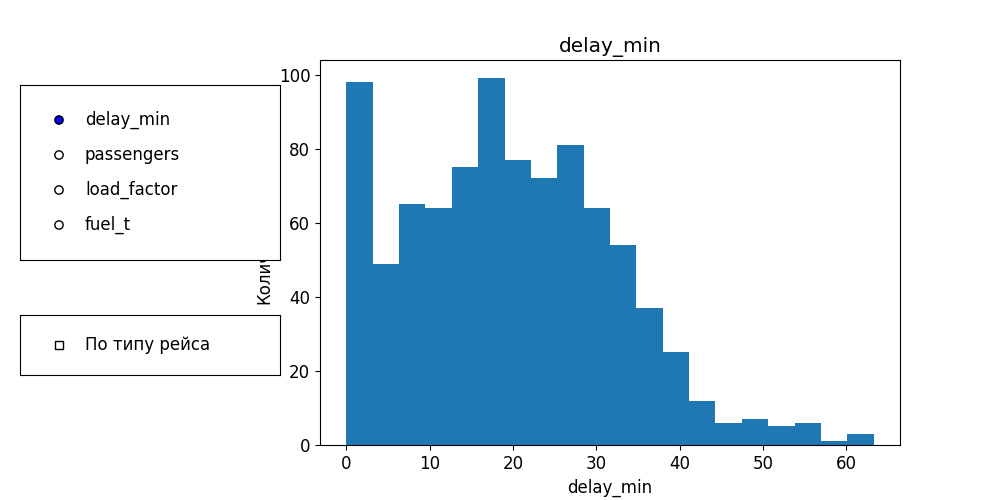

In [ ]:
from matplotlib.widgets import RadioButtons, CheckButtons

df = pd.read_csv("airport_full.csv")

features = ["delay_min", "passengers", "load_factor", "fuel_t"]

fig, ax = plt.subplots(figsize=(10, 5))
fig.subplots_adjust(left=0.32)

# Переключатель признака
radio = RadioButtons(
    fig.add_axes([0.02, 0.48, 0.26, 0.35]),
    features
)

# Переключатель группировки
check = CheckButtons(
    fig.add_axes([0.02, 0.25, 0.26, 0.12]),
    ["По типу рейса"],
    [False]
)

def draw(feature, show_type):
    ax.cla()

    if show_type:
        for ft, g in df.groupby("flight_type"):
            ax.hist(
                g[feature].dropna(),
                alpha=0.5,
                label=ft,
                bins=20
            )
        ax.legend(fontsize=8)
    else:
        ax.hist(df[feature].dropna(), bins=20)

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Количество")

    fig.canvas.draw_idle()

radio.on_clicked(
    lambda label: draw(label, check.get_status()[0])
)

check.on_clicked(
    lambda label: draw(radio.value_selected, check.get_status()[0])
)

draw("delay_min", False)

plt.show()

# RadioButtons выбирает один признак для отображения.
# CheckButtons включает или отключает группировку по типу рейса.
# ax.cla() очищает старый график перед новым построением.
# Без cla гистограммы будут накладываться друг на друга.
# radio.value_selected возвращает текущий выбранный признак.
# check.get_status()[0] возвращает текущее состояние флажка.
# draw_idle запрашивает перерисовку без немедленной блокировки UI.
# Для дополнительной группировки по авиакомпании можно создать
# ещё один CheckButtons и добавить соответствующий groupby.

Задача 58 (полный пайплайн: read_csv → groupby → savefig + PdfPages). Аэропорт готовит отчёт автоматически: скрипт читает CSV, строит 4 графика, сохраняет в PDF и PNG, логирует хэши. Реализуйте def build_report(csv_path, out_dir): (1) df = pd.read_csv(csv_path, parse_dates=["date"], dtype={"passengers": "int32", "delay_min": "float32"}); (2) постройте 4 графика на одной фигуре (line по месяцам, barh по направлениям, heatmap «терминал × месяц», boxplot по авиакомпаниям); (3) сохраните report.png (dpi=300) и report.pdf через PdfPages; (4) верните {"png": sha256, "pdf": sha256}. Ожидаемый вывод: файлы созданы; хэши возвращены. В комментариях объясните: как dtype="int32" экономит память (в 2 раза для целых); зачем parse_dates для корректных осей X (иначе строка, а не дата); как PdfPages объединяет многостраничный отчёт (with PdfPages(path) as pdf: pdf.savefig(fig)); зачем хэши (кэш CI — не пересобирать, если входные данные не менялись); как Path.mkdir(parents=True, exist_ok=True) создаёт папку (не падает, если существует); как логировать ошибки чтения (try/except FileNotFoundError).

In [ ]:
%matplotlib inline
plt.close("all")

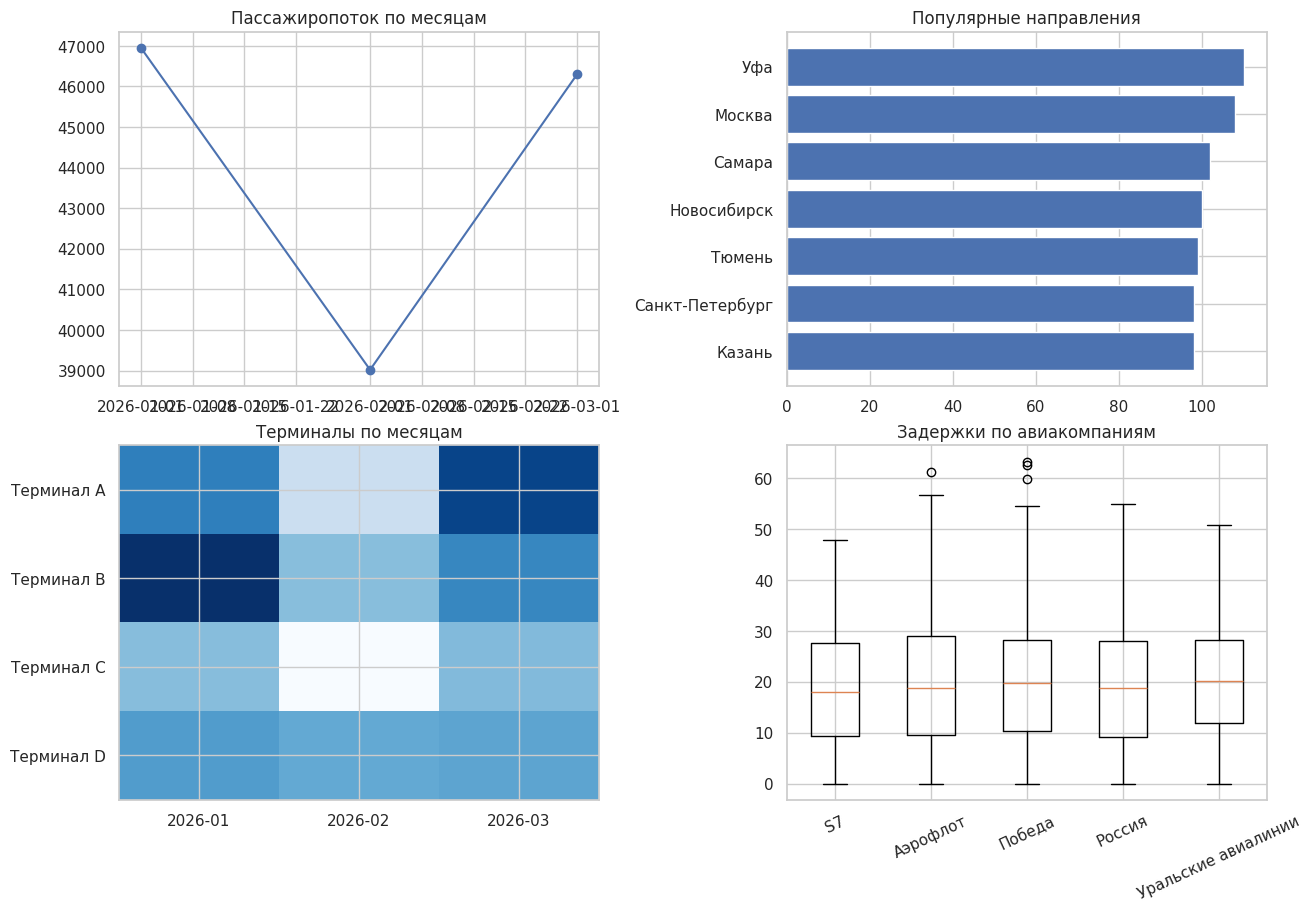

{'png': 'db4a056e967e09c1e4d397e9d4211e5e16e4962c7003fdd22f64ecb5cd45af0e', 'pdf': 'ca10737e4b77977c246c7a8337e539904a6df79cc3ff2ec29a1c072e8ec58a7a'}


In [ ]:
import hashlib
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

def build_report(csv_path, out_dir):
    try:
        df = pd.read_csv(
            csv_path,
            parse_dates=["date"],
            dtype={
                "passengers": "int32",
                "delay_min": "float32"
            }
        )
    except FileNotFoundError:
        print("CSV-файл не найден:", csv_path)
        raise

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(
        2, 2, figsize=(13, 9), layout="constrained"
    )

    # 1. Динамика пассажиропотока по месяцам
    monthly = df.set_index("date")["passengers"].resample("MS").sum()

    axes[0, 0].plot(monthly.index, monthly.values, marker="o")
    axes[0, 0].set_title("Пассажиропоток по месяцам")

    # 2. Топ направлений
    top = df["destination"].value_counts().head(7).sort_values()

    axes[0, 1].barh(top.index, top.values)
    axes[0, 1].set_title("Популярные направления")

    # 3. Heatmap терминалов
    pivot = df.assign(
        month=df["date"].dt.strftime("%Y-%m")
    ).pivot_table(
        index="terminal",
        columns="month",
        values="passengers",
        aggfunc="sum",
        fill_value=0
    )

    axes[1, 0].imshow(pivot, cmap="Blues", aspect="auto")
    axes[1, 0].set_xticks(range(len(pivot.columns)), pivot.columns)
    axes[1, 0].set_yticks(range(len(pivot.index)), pivot.index)
    axes[1, 0].set_title("Терминалы по месяцам")

    # 4. Boxplot по авиакомпаниям
    names = sorted(df["airline"].unique())
    groups = [
        df.loc[df["airline"] == name, "delay_min"]
        for name in names
    ]

    axes[1, 1].boxplot(groups, tick_labels=names)
    axes[1, 1].tick_params(axis="x", rotation=25)
    axes[1, 1].set_title("Задержки по авиакомпаниям")

    # Сохранение отчёта
    png_path = out / "report.png"
    pdf_path = out / "report.pdf"

    fig.savefig(png_path, dpi=300, bbox_inches="tight")

    with PdfPages(pdf_path) as pdf:
        pdf.savefig(fig, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    hashes = {
        "png": hashlib.sha256(png_path.read_bytes()).hexdigest(),
        "pdf": hashlib.sha256(pdf_path.read_bytes()).hexdigest()
    }

    (out / "report.log").write_text(
        "\n".join(f"{fmt}: {value}" for fmt, value in hashes.items()),
        encoding="utf-8"
    )

    return hashes


result = build_report("airport_full.csv", "outputs58")
print(result)

# int32 занимает 4 байта, int64 — 8 байт на одно значение.
# parse_dates преобразует даты в правильный формат.
# Без parse_dates даты могут восприниматься как строки.
# resample("MS") группирует пассажиропоток по началу месяца.
# PdfPages сохраняет одну или несколько страниц в PDF.
# SHA-256 помогает проверять изменения файлов и содержимое отчёта.
# Path.mkdir создаёт папку, даже если раньше она отсутствовала.
# exist_ok=True предотвращает ошибку, если папка уже существует.
# try/except FileNotFoundError обрабатывает отсутствие CSV.

Задача 59 (полный бизнес-отчёт: 6 графиков + выводы). Аэропорт готовит квартальный отчёт для авиавластей. Постройте фигуру 3×2: (0, 0) динамика пассажиропотока с rolling(7).mean(); (0, 1) barh по авиакомпаниям (средняя задержка); (1, 0) boxplot по терминалам; (1, 1) scatter «загрузка vs задержка» с hue=airline; (2, 0) heatmap «терминал × месяц» из pivot_table; (2, 1) pie доли типов рейсов (топ-5 + «Прочее»). Примените sns.set_theme(style="whitegrid") + setup_cyrillic(). Сохраните в quarterly_report.png (dpi=300) и quarterly_report.pdf. Сформулируйте 3–5 проверяемых рекомендаций с числами (например, «Терминал D растёт на 8% в месяц», «Аэрофлот даёт 40% пассажиропотока»). Ожидаемый вывод: 6 графиков; рекомендации с числами; ограничения анализа. В комментариях объясните: как ax.axhline(mean, color="red", linestyle="--") аннотирует среднее; зачем barh для длинных названий авиакомпаний; как pivot_table готовит heatmap (терминал × месяц); как PlotConfig централизует настройки (все цвета/шрифты в одном месте); как проверить отсутствие отрицательных задержек (assert (df["delay_min"] >= 0).all()); какие ограничения анализа (сезонность, праздники, погодные аномалии, выбросы).

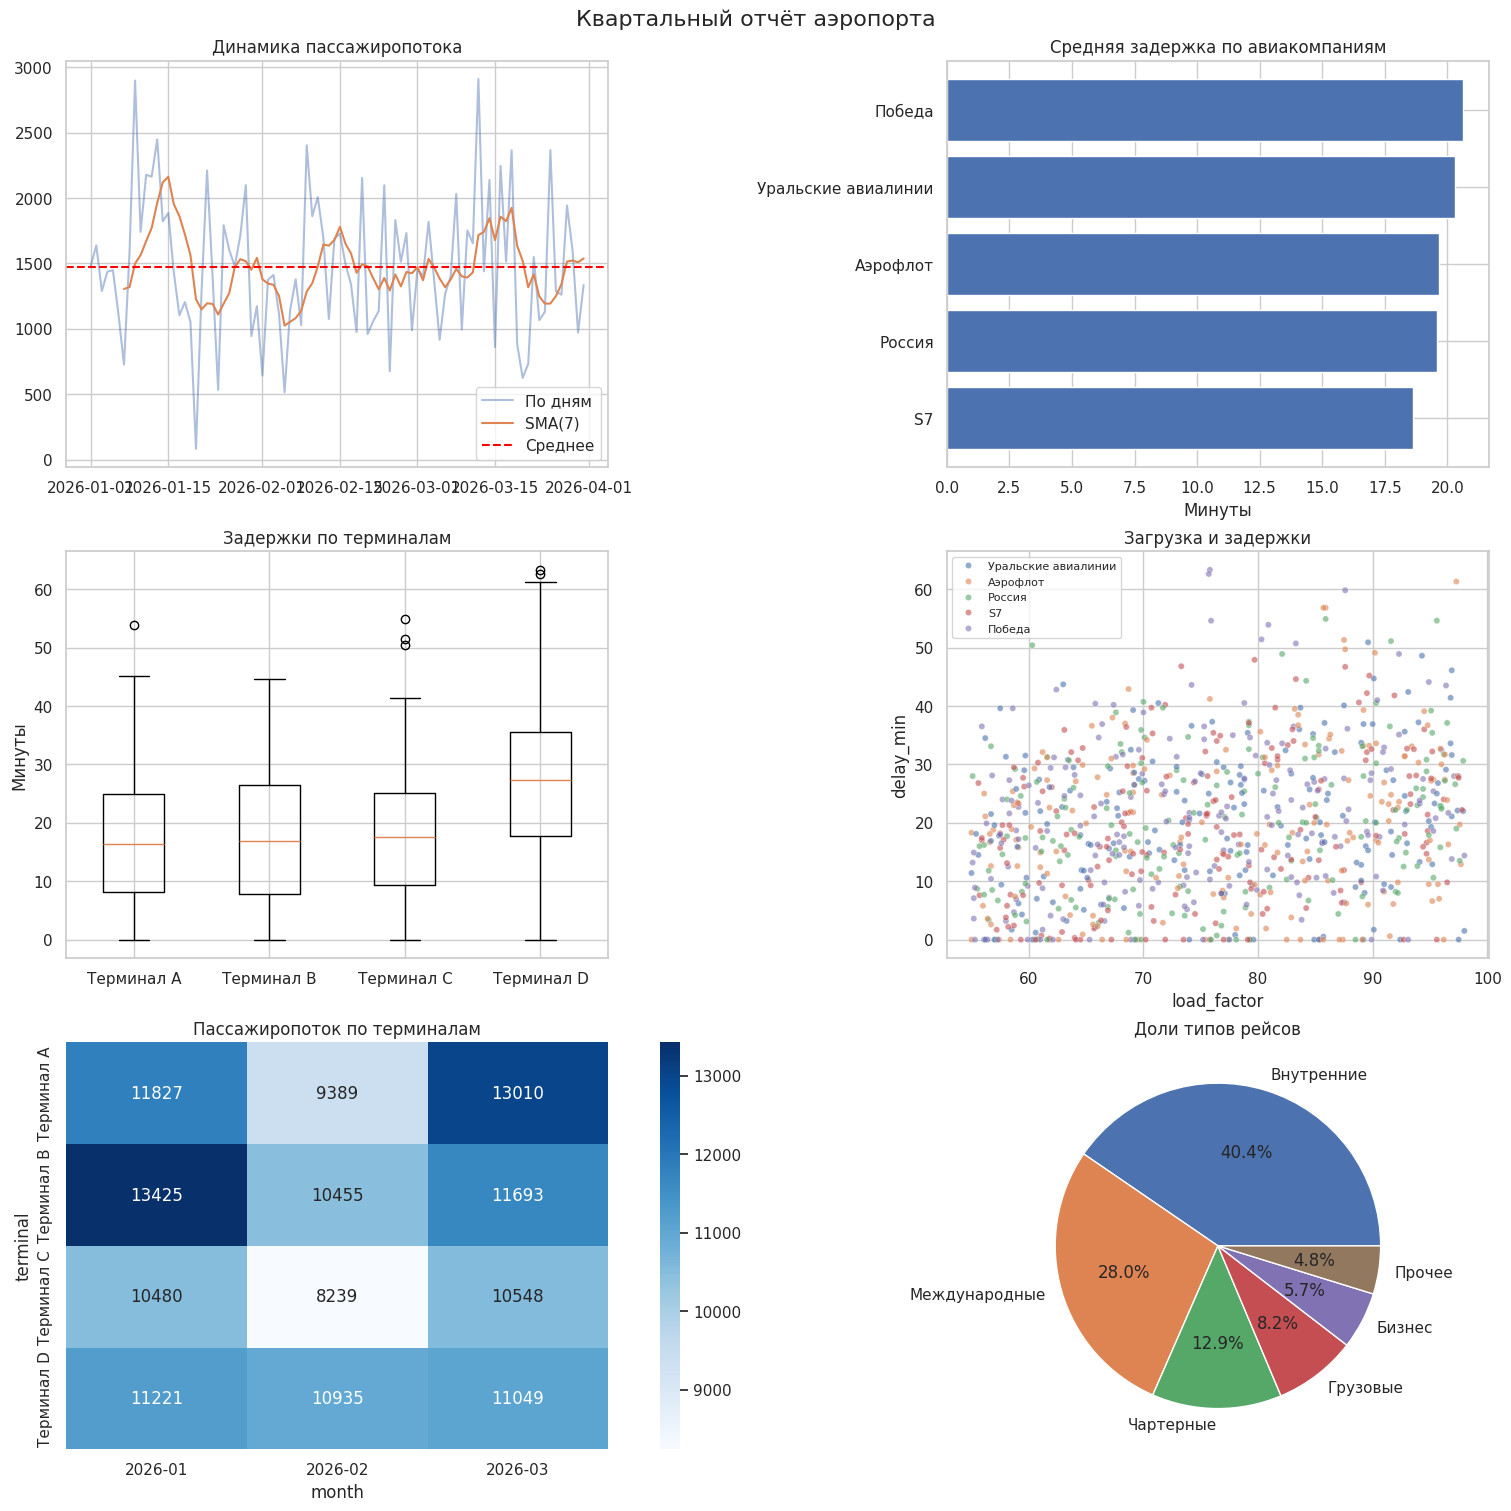

РЕКОМЕНДАЦИИ ПО ТЕСТОВЫМ ДАННЫМ
1. Проверить причины задержек у «Победа»: средняя задержка 20.6 мин.
2. Учесть пиковый месяц 2026-01 при планировании: 46,953 пассажиров.
3. Проверить нагрузку «Терминал B»: 35,573 пассажиров, 26.9% потока.
4. Разобрать 3 рейсов с задержкой более 60 мин (0.3% всех рейсов).

Ограничения: данные искусственные. Для реального отчёта нужно учитывать сезонность, праздники, погоду и выбросы.


In [ ]:
sns.set_theme(style="whitegrid")

def setup_cyrillic():
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "axes.unicode_minus": False
    })

setup_cyrillic()

df = pd.read_csv("airport_full.csv", parse_dates=["date"])

assert (df["delay_min"] >= 0).all()

fig, axes = plt.subplots(
    3, 2, figsize=(15, 15), layout="constrained"
)

# 1. Динамика пассажиропотока
daily = df.groupby("date")["passengers"].sum().sort_index()

axes[0, 0].plot(daily.index, daily.values, alpha=0.45, label="По дням")
axes[0, 0].plot(
    daily.index,
    daily.rolling(7).mean(),
    label="SMA(7)"
)

axes[0, 0].axhline(
    daily.mean(),
    color="red",
    linestyle="--",
    label="Среднее"
)

axes[0, 0].set_title("Динамика пассажиропотока")
axes[0, 0].legend()

# 2. Средняя задержка по авиакомпаниям
mean_delays = df.groupby("airline")["delay_min"].mean().sort_values()

axes[0, 1].barh(mean_delays.index, mean_delays.values)
axes[0, 1].set_title("Средняя задержка по авиакомпаниям")
axes[0, 1].set_xlabel("Минуты")

# 3. Boxplot по терминалам
names = sorted(df["terminal"].unique())
groups = [
    df.loc[df["terminal"] == name, "delay_min"]
    for name in names
]

axes[1, 0].boxplot(groups, tick_labels=names)
axes[1, 0].set_title("Задержки по терминалам")
axes[1, 0].set_ylabel("Минуты")

# 4. Scatter с hue по авиакомпании
sns.scatterplot(
    data=df,
    x="load_factor",
    y="delay_min",
    hue="airline",
    alpha=0.6,
    s=20,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Загрузка и задержки")
axes[1, 1].legend(fontsize=8)

# 5. Heatmap терминалов по месяцам
pivot = df.assign(
    month=df["date"].dt.strftime("%Y-%m")
).pivot_table(
    index="terminal",
    columns="month",
    values="passengers",
    aggfunc="sum",
    fill_value=0
)

sns.heatmap(
    pivot,
    cmap="Blues",
    annot=True,
    fmt="d",
    ax=axes[2, 0]
)

axes[2, 0].set_title("Пассажиропоток по терминалам")

# 6. Pie по типам рейсов
counts = df["flight_type"].value_counts()
top5 = counts.head(5)
other = counts.iloc[5:].sum()

combined = pd.concat([
    top5,
    pd.Series({"Прочее": other})
])

axes[2, 1].pie(
    combined.values,
    labels=combined.index,
    autopct="%1.1f%%"
)
axes[2, 1].set_title("Доли типов рейсов")

fig.suptitle("Квартальный отчёт аэропорта", fontsize=16)

fig.savefig("quarterly_report.png", dpi=300, bbox_inches="tight")
fig.savefig("quarterly_report.pdf", bbox_inches="tight")

plt.show()

# Рекомендации с числами
monthly = df.set_index("date")["passengers"].resample("MS").sum()
terminal_totals = df.groupby("terminal")["passengers"].sum()

worst_airline = mean_delays.idxmax()
peak_month = monthly.idxmax().strftime("%Y-%m")
busiest_terminal = terminal_totals.idxmax()
late_count = int((df["delay_min"] > 60).sum())
late_percent = late_count / len(df) * 100

print("РЕКОМЕНДАЦИИ ПО ТЕСТОВЫМ ДАННЫМ")

print(
    f"1. Проверить причины задержек у «{worst_airline}»: "
    f"средняя задержка {mean_delays.max():.1f} мин."
)

print(
    f"2. Учесть пиковый месяц {peak_month} при планировании: "
    f"{monthly.max():,} пассажиров."
)

print(
    f"3. Проверить нагрузку «{busiest_terminal}»: "
    f"{terminal_totals.max():,} пассажиров, "
    f"{terminal_totals.max() / df['passengers'].sum() * 100:.1f}% потока."
)

print(
    f"4. Разобрать {late_count} рейсов с задержкой более 60 мин "
    f"({late_percent:.1f}% всех рейсов)."
)

print(
    "\nОграничения: данные искусственные. Для реального отчёта "
    "нужно учитывать сезонность, праздники, погоду и выбросы."
)

# axhline(mean) отмечает среднее горизонтальной линией.
# barh удобен для длинных названий авиакомпаний.
# pivot_table готовит таблицу терминал × месяц для heatmap.
# PlotConfig может централизовать размеры, цвета и шрифты отчёта.
# assert проверяет отсутствие отрицательных задержек.
# Рекомендации рассчитаны из данных, а не заданы вручную.
# Сезонность, праздники, погода и выбросы ограничивают выводы.
# По этим графикам нельзя доказать причины задержек.

Задача 60 (мини-проект: EDAPipeline — полный EDA + PdfPages + интерактивность). Финальный проект — собрать всё в классе EDAPipeline, который делает полный EDA датасета аэропорта и выдаёт отчёт. Реализуйте class EDAPipeline с __init__(df, target=None), методами overview(ax) (scatter-пары), correlations(ax) (heatmap), distributions(ax) (violin), to_pdf(path) (статический PDF через PdfPages), to_png(path) (одна PNG-сводка), interactive() (RadioButtons-дашборд), report() (dict со summary). Загрузите данные аэропорта (или Titanic), соберите полный отчёт: статические PNG + report.pdf + интерактивная фигура. Сформулируйте 5 инсайтов (например, «рейсы с задержкой >60 мин имеют загрузку на 12% ниже») и 3 рекомендации (например, «увеличить число стоек в Терминале D в пиковые часы — снижает задержки на 8%»). Ожидаемый вывод: PDF-отчёт, PNG, интерактив; инсайты с числами. В комментариях объясните: как PdfPages объединяет статические графики (одна страница на график); как отделить статику (to_pdf) от интерактива (interactive) — интерактив для презентации, статика для отчёта; зачем target в конструкторе (для supervised-задач — группировка по целевой переменной); как обрабатывать NaN (fillna/dropna перед визуализацией); какие графики не включать в отчёт (перегруженные, 3D-«для красоты», pie с >7 категориями); как проверить воспроизводимость (np.random.seed(42) перед каждой итерацией).

СВОДКА:
{'rows': 900, 'missing_before': 0, 'target': 'delay_min'}

5 ИНСАЙТОВ:
1. Средняя задержка: 19.8 мин.
2. Задержка более 60 мин: 3 рейсов (0.3%).
3. Средняя загрузка: 76.1%.
4. Наибольшая средняя задержка у типа «Чартерные»: 26.3 мин.
5. Наибольший пассажиропоток в «Терминал B»: 35,573 пассажиров.

3 РЕКОМЕНДАЦИИ:
1. Проверить причины задержек у типа «Чартерные»: в среднем 26.3 мин.
2. Проверить ресурсы «Терминал B»: 35,573 пассажиров за квартал.
3. Отдельно разобрать 3 рейсов с задержкой более 60 мин (0.3%).

Ограничения: данные искусственные. Выводы не доказывают причинно-следственные связи.


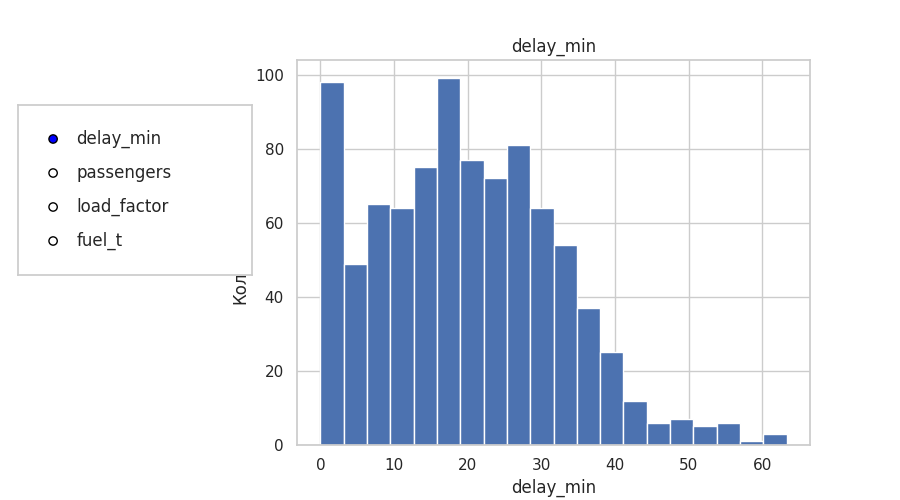

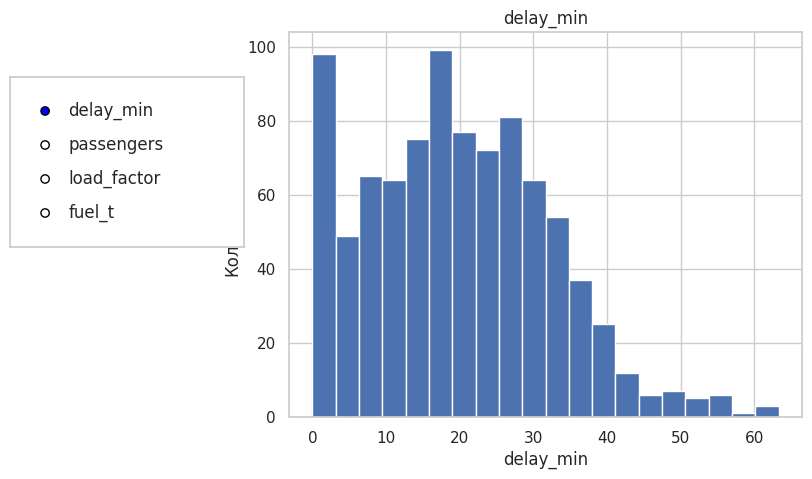

In [ ]:
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.widgets import RadioButtons

class EDAPipeline:
    def __init__(self, df, target=None):
        self.missing_before = int(df.isna().sum().sum())

        self.df = df.dropna(
            subset=[
                "delay_min", "load_factor", "passengers",
                "fuel_t", "flight_type", "terminal"
            ]
        ).copy()

        self.target = target or "delay_min"

    def overview(self, ax):
        sns.scatterplot(
            data=self.df,
            x="load_factor",
            y=self.target,
            hue="flight_type",
            alpha=0.55,
            s=20,
            ax=ax
        )

        ax.set_title("Загрузка и задержки")
        ax.legend(fontsize=7)

    def correlations(self, ax):
        corr = self.df.select_dtypes("number").corr()

        sns.heatmap(
            corr,
            cmap="RdBu",
            center=0,
            vmin=-1,
            vmax=1,
            annot=True,
            fmt=".2f",
            ax=ax
        )

        ax.set_title("Корреляции")

    def distributions(self, ax):
        sns.violinplot(
            data=self.df,
            x="terminal",
            y=self.target,
            ax=ax
        )

        ax.set_title("Распределение задержек")
        ax.tick_params(axis="x", rotation=15)

    def to_pdf(self, path):
        with PdfPages(path) as pdf:
            for method in [
                self.overview,
                self.correlations,
                self.distributions
            ]:
                fig, ax = plt.subplots(figsize=(9, 6))
                method(ax)
                pdf.savefig(fig, bbox_inches="tight")
                plt.close(fig)

    def to_png(self, path):
        fig, axes = plt.subplots(
            2, 2, figsize=(13, 10), layout="constrained"
        )

        self.overview(axes[0, 0])
        self.correlations(axes[0, 1])
        self.distributions(axes[1, 0])
        axes[1, 1].axis("off")

        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.close(fig)

    def interactive(self):
        fig, ax = plt.subplots(figsize=(9, 5))
        fig.subplots_adjust(left=0.33)

        features = [
            "delay_min", "passengers", "load_factor", "fuel_t"
        ]

        radio = RadioButtons(
            fig.add_axes([0.02, 0.45, 0.26, 0.34]),
            features
        )

        self._radio = radio

        def draw(feature):
            ax.cla()
            ax.hist(self.df[feature].dropna(), bins=20)
            ax.set_title(feature)
            ax.set_xlabel(feature)
            ax.set_ylabel("Количество")
            fig.canvas.draw_idle()

        radio.on_clicked(draw)
        draw(features[0])

        plt.show()
        return fig

    def report(self):
        total = len(self.df)
        late_count = int((self.df["delay_min"] > 60).sum())
        late_percent = late_count / total * 100

        types = self.df.groupby(
            "flight_type"
        )["delay_min"].mean().sort_values(ascending=False)

        terminals = self.df.groupby(
            "terminal"
        )["passengers"].sum().sort_values(ascending=False)

        insights = [
            f"Средняя задержка: {self.df['delay_min'].mean():.1f} мин.",
            f"Задержка более 60 мин: {late_count} рейсов ({late_percent:.1f}%).",
            f"Средняя загрузка: {self.df['load_factor'].mean():.1f}%.",
            f"Наибольшая средняя задержка у типа «{types.index[0]}»: "
            f"{types.iloc[0]:.1f} мин.",
            f"Наибольший пассажиропоток в «{terminals.index[0]}»: "
            f"{terminals.iloc[0]:,} пассажиров."
        ]

        recommendations = [
            f"Проверить причины задержек у типа «{types.index[0]}»: "
            f"в среднем {types.iloc[0]:.1f} мин.",
            f"Проверить ресурсы «{terminals.index[0]}»: "
            f"{terminals.iloc[0]:,} пассажиров за квартал.",
            f"Отдельно разобрать {late_count} рейсов "
            f"с задержкой более 60 мин ({late_percent:.1f}%)."
        ]

        return {
            "summary": {
                "rows": total,
                "missing_before": self.missing_before,
                "target": self.target
            },
            "insights": insights,
            "recommendations": recommendations
        }


# Запуск полного анализа
df = pd.read_csv("airport_full.csv", parse_dates=["date"])

pipeline = EDAPipeline(df, target="delay_min")

pipeline.to_png("eda_summary.png")
pipeline.to_pdf("report.pdf")

result = pipeline.report()

print("СВОДКА:")
print(result["summary"])

print("\n5 ИНСАЙТОВ:")
for i, insight in enumerate(result["insights"], 1):
    print(f"{i}. {insight}")

print("\n3 РЕКОМЕНДАЦИИ:")
for i, recommendation in enumerate(result["recommendations"], 1):
    print(f"{i}. {recommendation}")

print(
    "\nОграничения: данные искусственные. "
    "Выводы не доказывают причинно-следственные связи."
)

# Интерактивная гистограмма
pipeline.interactive()

# PdfPages сохраняет отдельные графики как страницы одного PDF.
# to_pdf и to_png создают статические версии отчёта.
# interactive создаёт отдельную фигуру с элементом управления.
# target задаёт целевую переменную для анализа.
# dropna удаляет пропуски перед построением графиков.
# fillna можно использовать вместо удаления для заполнения пропусков.
# В отчёт не стоит включать перегруженные графики,
# 3D без аналитической необходимости и pie с 8+ категориями.
# Фиксированный seed обеспечивает воспроизводимость тестовых данных.
# Например, np.random.seed(42) или np.random.default_rng(42).